In [ ]:
from google.colab import drive
drive.mount('/content/drive', force_remount=True)

Mounted at /content/drive


In [ ]:
import os

print("drive exists:", os.path.exists("/content/drive"))
print("drive is directory:", os.path.isdir("/content/drive"))

if os.path.exists("/content/drive"):
    print("Contents of /content/drive:")
    print(os.listdir("/content/drive")[:20])

drive exists: True
drive is directory: True
Contents of /content/drive:
['.shortcut-targets-by-id', 'MyDrive', '.Trash-0', '.Encrypted']


In [ ]:
import os

for path in [
    "/content/drive/MyDrive",
    "/content/drive/MyDrive/CVD",
    "/content/drive/MyDrive/CVD EX",
]:
    print("\n" + "="*80)
    print(path)
    print("Exists:", os.path.exists(path))

    if os.path.exists(path):
        print("Contents:")
        print(os.listdir(path)[:30])


/content/drive/MyDrive
Exists: True
Contents:
['Colab Notebooks', 'CVD', 'CVD EX']

/content/drive/MyDrive/CVD
Exists: True
Contents:
['dataset', 'models', 'results', 'figures']

/content/drive/MyDrive/CVD EX
Exists: True
Contents:
['LLCP2023.XPT', 'external_validation_2023']


In [ ]:
import os

base = "/content/drive/MyDrive/CVD EX"

for root, dirs, files in os.walk(base):
    level = root.replace(base, "").count(os.sep)
    indent = "  " * level
    print(f"{indent}{os.path.basename(root)}/")

    for f in files[:20]:
        print(f"{indent}  {f}")

CVD EX/
  LLCP2023.XPT
  external_validation_2023/
    heart_2023_same_columns_corrected.csv
    2023_mapping_report.csv
    heart_2023_preprocessed.csv
    heart_2023_final_47_features.csv
    heart_2023_final_47_features_FIXED.csv
    heart_2023_final_47_features_READY.csv
    external_validation_2023_predictions.csv
    external_validation_2023_metrics.csv
    external_validation_2023_confusion_matrix.csv
    table_2022_vs_2023_external_validation.csv
    table_2022_vs_2023_publication.csv
    external_validation_2023_roc_auc.csv
    figure_2023_external_validation_roc.png
    figure_2023_external_validation_roc.pdf
    external_validation_2023_pr_auc.csv
    figure_2023_external_validation_pr.png
    figure_2023_external_validation_pr.pdf
    external_validation_2023_threshold_metrics.csv
    external_validation_2023_confusion_matrices.csv
    external_validation_2022_vs_2023_comparison.csv
    feature_distribution_shift/


In [ ]:
import os

print("CVD EX exists:",
      os.path.exists('/content/drive/MyDrive/CVD EX'))

print("\nCVD EX contents:")
if os.path.exists('/content/drive/MyDrive/CVD EX'):
    print(os.listdir('/content/drive/MyDrive/CVD EX'))

print("\nDataset folder exists:",
      os.path.exists('/content/drive/MyDrive/CVD EX/LLCP2023.XPT'))

print("\nDataset contents:")
if os.path.exists('/content/drive/MyDrive/CVD EX/EX/LLCP2023.XPT'):
    print(os.listdir('/content/drive/MyDrive/CVD EX/EX/LLCP2023.XPT'))

CVD EX exists: True

CVD EX contents:
['LLCP2023.XPT', 'external_validation_2023']

Dataset folder exists: True

Dataset contents:


In [ ]:
import os
import pandas as pd

BASE = '/content/drive/MyDrive/CVD EX'
XPT_PATH = f'{BASE}/LLCP2023.XPT'

print("XPT exists:", os.path.exists(XPT_PATH))
print("XPT path:", XPT_PATH)

if not os.path.exists(XPT_PATH):
    raise FileNotFoundError(f"File not found: {XPT_PATH}")

# Load 2023 BRFSS XPT
df23_raw = pd.read_sas(XPT_PATH, format='xport')

print("\n" + "="*70)
print("LLCP2023.XPT LOADED SUCCESSFULLY")
print("="*70)
print("Shape:", df23_raw.shape)
print("Number of columns:", len(df23_raw.columns))
print("First 10 columns:")
print(df23_raw.columns[:10].tolist())

XPT exists: True
XPT path: /content/drive/MyDrive/CVD EX/LLCP2023.XPT

LLCP2023.XPT LOADED SUCCESSFULLY
Shape: (433323, 350)
Number of columns: 350
First 10 columns:
['_STATE', 'FMONTH', 'IDATE', 'IMONTH', 'IDAY', 'IYEAR', 'DISPCODE', 'SEQNO', '_PSU', 'CTELENM1']


In [ ]:
# ============================================================
# EXTERNAL VALIDATION — 2023 BRFSS
# CELL 1 — LOAD + INSPECT ACTUAL XPT
# ============================================================

import os
import numpy as np
import pandas as pd

print("=" * 75)
print("EXTERNAL VALIDATION — 2023 BRFSS")
print("=" * 75)

# ------------------------------------------------------------
# Paths
# ------------------------------------------------------------
TRAIN_BASE = '/content/drive/MyDrive/CVD'
EXTERNAL_BASE = '/content/drive/MyDrive/CVD EX'

MODELS_DIR = f'{TRAIN_BASE}/models'
RESULTS_DIR = f'{TRAIN_BASE}/results'

XPT_PATH = f'{EXTERNAL_BASE}/LLCP2023.XPT'

print("\nXPT path:")
print(XPT_PATH)

if not os.path.exists(XPT_PATH):
    raise FileNotFoundError(
        f"\nLLCP2023.XPT not found at:\n{XPT_PATH}"
    )

# ------------------------------------------------------------
# Load
# ------------------------------------------------------------
df23_raw = pd.read_sas(XPT_PATH, format='xport')

print("\n" + "=" * 75)
print("XPT LOADED")
print("=" * 75)

print("Shape:", df23_raw.shape)
print("Columns:", len(df23_raw.columns))

# ------------------------------------------------------------
# IYEAR inspection
# ------------------------------------------------------------
if 'IYEAR' in df23_raw.columns:
    print("\nIYEAR distribution:")
    print(df23_raw['IYEAR'].value_counts(dropna=False))

# ------------------------------------------------------------
# Target variables
# ------------------------------------------------------------
target_vars = ['CVDINFR4', 'CVDCRHD4', '_MICHD']

print("\nTarget-related variables:")
for c in target_vars:
    if c in df23_raw.columns:
        print(f"\n{c}")
        print(df23_raw[c].value_counts(dropna=False))
    else:
        print(f"{c}: NOT FOUND")

# ------------------------------------------------------------
# Required raw variables — inspect only
# ------------------------------------------------------------
required_candidates = [
    'SEXVAR',
    'GENHLTH',
    'PHYSHLTH',
    'MENTHLTH',
    'CHECKUP1',
    'EXERANY2',
    'SLEPTIM1',
    'RMVTETH4',
    'CVDSTRK3',
    'ASTHMA3',
    'ASTHNOW',
    'CHCSCNCR',
    'CHCSCNC1',
    'CHCOCNCR',
    'CHCCOPD2',
    'CHCCOPD3',
    'ADDEPEV3',
    'CHCKDNY2',
    'HAVARTH4',
    'DIABETE4',
    'WEIGHT2',
    'HEIGHT3',
    'DEAF',
    'BLIND',
    'DECIDE',
    'DIFFWALK',
    'DIFFDRES',
    'DIFFALON',
    'SMOKE100',
    '_SMOKER3',
    'ECIGARET',
    'ECIGNOW2',
    'LCSCTSC1',
    'CHESTSCN',
    '_AGEG5YR',
    'HTM4',
    'WTKG3',
    '_BMI5',
    'DRNKANY6',
    'DRNKANY5',
    'HIVTST7',
    'FLUSHOT7',
    'PNEUVAC4',
    'PNEUMO3',
    'HIVRISK5',
    'COVIDPO1',
    'COVIDPOS',
    '_RACEGR3',
    'TETANUS1',
    'TETANUS2',
    '_STATE'
]

print("\n" + "=" * 75)
print("REQUIRED VARIABLE AVAILABILITY")
print("=" * 75)

for c in required_candidates:
    print(f"{c:<15} {'FOUND' if c in df23_raw.columns else 'NOT FOUND'}")

EXTERNAL VALIDATION — 2023 BRFSS

XPT path:
/content/drive/MyDrive/CVD EX/LLCP2023.XPT

XPT LOADED
Shape: (433323, 350)
Columns: 350

IYEAR distribution:
IYEAR
b'2023'    408012
b'2024'     25311
Name: count, dtype: int64

Target-related variables:

CVDINFR4
CVDINFR4
2.0    407304
1.0     23451
7.0      2314
9.0       251
NaN         3
Name: count, dtype: int64

CVDCRHD4
CVDCRHD4
2.0    405638
1.0     23454
7.0      3936
9.0       292
NaN         3
Name: count, dtype: int64

_MICHD
_MICHD
2.0    392427
1.0     36311
NaN      4585
Name: count, dtype: int64

REQUIRED VARIABLE AVAILABILITY
SEXVAR          FOUND
GENHLTH         FOUND
PHYSHLTH        FOUND
MENTHLTH        FOUND
CHECKUP1        FOUND
EXERANY2        FOUND
SLEPTIM1        NOT FOUND
RMVTETH4        NOT FOUND
CVDSTRK3        FOUND
ASTHMA3         FOUND
ASTHNOW         FOUND
CHCSCNCR        NOT FOUND
CHCSCNC1        FOUND
CHCOCNCR        NOT FOUND
CHCCOPD2        NOT FOUND
CHCCOPD3        FOUND
ADDEPEV3        FOUND
CHCKDNY2    

In [ ]:
# ============================================================
# EXTERNAL VALIDATION
# SAFE CHECKPOINT READ — NO FILES WILL BE MODIFIED
# ============================================================

import os
import sys
import subprocess

print("=" * 75)
print("CHECKING REQUIRED PYTHON PACKAGES")
print("=" * 75)

# Make sure pandas is available
try:
    import pandas as pd
    print("pandas:", pd.__version__)
except Exception as e:
    print("pandas import problem:", e)

# Check sklearn
try:
    import sklearn
    print("scikit-learn:", sklearn.__version__)
except Exception as e:
    print("scikit-learn problem:", e)

# Check xgboost
try:
    import xgboost
    print("xgboost:", xgboost.__version__)
except Exception as e:
    print("xgboost problem:", e)

# Check lightgbm
try:
    import lightgbm
    print("lightgbm:", lightgbm.__version__)
except Exception as e:
    print("lightgbm problem:", e)

# Check catboost
try:
    import catboost
    print("catboost:", catboost.__version__)
except Exception as e:
    print("catboost problem:", e)

print("\n" + "=" * 75)
print("IMPORTANT")
print("=" * 75)
print("No CVD files are being written.")
print("No CVD models are being changed.")
print("No CVD checkpoints are being changed.")
print("This cell only checks the environment.")

CHECKING REQUIRED PYTHON PACKAGES
pandas: 2.2.3
scikit-learn: 1.6.1
xgboost: 3.4.1
lightgbm: 4.6.0
catboost problem: No module named 'catboost'

IMPORTANT
No CVD files are being written.
No CVD models are being changed.
No CVD checkpoints are being changed.
This cell only checks the environment.


In [ ]:
# ============================================================
# EXTERNAL VALIDATION — INSTALL CATBOOST
# SAFE: DOES NOT MODIFY CVD FILES
# ============================================================

!pip install -q catboost

import catboost

print("=" * 75)
print("CATBOOST INSTALLED SUCCESSFULLY")
print("=" * 75)
print("CatBoost version:", catboost.__version__)

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 97.1/97.1 MB 7.9 MB/s eta 0:00:00
CATBOOST INSTALLED SUCCESSFULLY
CatBoost version: 1.2.10


In [ ]:
# ============================================================
# EXTERNAL VALIDATION — SAFE CHECKPOINT LOAD TEST
# ============================================================
# IMPORTANT:
# CVD folder is READ-ONLY.
# Nothing will be saved, overwritten, deleted, or modified.
# ============================================================

import os
import pickle
import joblib

BASE = '/content/drive/MyDrive/CVD'
MODELS_DIR = f'{BASE}/models'

CHECKPOINTS = {
    'preprocessing': f'{MODELS_DIR}/preprocessing_checkpoint.pkl',
    'encoding':      f'{MODELS_DIR}/encoding_checkpoint.pkl',
    'fe':             f'{MODELS_DIR}/fe_checkpoint.pkl',
    'scaler':         f'{MODELS_DIR}/scaler.pkl',
    'weights':        f'{MODELS_DIR}/ensemble/ensemble_weights.pkl',
    'threshold':     f'{MODELS_DIR}/ensemble/best_threshold.pkl',
    'strategy':       f'{MODELS_DIR}/ensemble/winning_strategy.pkl'
}

print("=" * 75)
print("READ-ONLY CHECKPOINT TEST")
print("=" * 75)

for name, path in CHECKPOINTS.items():

    print(f"\n{'-' * 75}")
    print(name.upper())
    print(path)

    if not os.path.exists(path):
        print("STATUS: FILE NOT FOUND")
        continue

    print("STATUS: FILE EXISTS")
    print("Size:", os.path.getsize(path), "bytes")

    # --------------------------------------------------------
    # First try joblib
    # --------------------------------------------------------
    try:
        obj = joblib.load(path)

        print("LOAD METHOD: joblib")
        print("TYPE:", type(obj))

        if isinstance(obj, dict):
            print("KEYS:", list(obj.keys()))

        elif hasattr(obj, 'shape'):
            print("SHAPE:", obj.shape)

        print("RESULT: SUCCESS")

    except Exception as e:

        print("joblib load failed:")
        print(type(e).__name__, ":", str(e))

        # ----------------------------------------------------
        # Then try standard pickle
        # ----------------------------------------------------
        try:
            with open(path, 'rb') as f:
                obj = pickle.load(f)

            print("LOAD METHOD: pickle")
            print("TYPE:", type(obj))

            if isinstance(obj, dict):
                print("KEYS:", list(obj.keys()))

            elif hasattr(obj, 'shape'):
                print("SHAPE:", obj.shape)

            print("RESULT: SUCCESS")

        except Exception as e2:

            print("pickle load failed:")
            print(type(e2).__name__, ":", str(e2))

            print("RESULT: BOTH METHODS FAILED")

print("\n" + "=" * 75)
print("CHECKPOINT TEST FINISHED")
print("=" * 75)
print("NO FILE WAS WRITTEN TO /CVD")
print("NO MODEL WAS MODIFIED")
print("NO CHECKPOINT WAS MODIFIED")
print("=" * 75)

READ-ONLY CHECKPOINT TEST

---------------------------------------------------------------------------
PREPROCESSING
/content/drive/MyDrive/CVD/models/preprocessing_checkpoint.pkl
STATUS: FILE EXISTS
Size: 70939229 bytes
LOAD METHOD: joblib
TYPE: <class 'dict'>
KEYS: ['X_train', 'X_val', 'X_test', 'y_train']
RESULT: SUCCESS

---------------------------------------------------------------------------
ENCODING
/content/drive/MyDrive/CVD/models/encoding_checkpoint.pkl
STATUS: FILE EXISTS
Size: 128746350 bytes
LOAD METHOD: joblib
TYPE: <class 'dict'>
KEYS: ['X_train', 'X_val', 'X_test']
RESULT: SUCCESS

---------------------------------------------------------------------------
FE
/content/drive/MyDrive/CVD/models/fe_checkpoint.pkl
STATUS: FILE EXISTS
Size: 139401422 bytes
LOAD METHOD: joblib
TYPE: <class 'dict'>
KEYS: ['X_train', 'X_val', 'X_test']
RESULT: SUCCESS

---------------------------------------------------------------------------
SCALER
/content/drive/MyDrive/CVD/models/scaler.p

In [ ]:
EXTERNAL_BASE = '/content/drive/MyDrive/CVD EX'

In [ ]:
# ============================================================
# EXTERNAL VALIDATION — EXACT TRAINING STRUCTURE INSPECTION
# ============================================================
# READ-ONLY
# Nothing is saved or modified.
# ============================================================

import os
import joblib
import pandas as pd
import numpy as np

BASE = '/content/drive/MyDrive/CVD'
MODELS_DIR = f'{BASE}/models'

PREP_PATH = f'{MODELS_DIR}/preprocessing_checkpoint.pkl'
ENC_PATH  = f'{MODELS_DIR}/encoding_checkpoint.pkl'
FE_PATH   = f'{MODELS_DIR}/fe_checkpoint.pkl'
SCALER_PATH = f'{MODELS_DIR}/scaler.pkl'

# ------------------------------------------------------------
# LOAD SAVED CHECKPOINTS
# ------------------------------------------------------------

prep = joblib.load(PREP_PATH)
enc  = joblib.load(ENC_PATH)
fe   = joblib.load(FE_PATH)
scaler = joblib.load(SCALER_PATH)

# ------------------------------------------------------------
# HELPER
# ------------------------------------------------------------

def inspect_df(name, obj):
    print("\n" + "=" * 75)
    print(name)
    print("=" * 75)

    print("Type:", type(obj))

    if isinstance(obj, pd.DataFrame):
        print("Shape:", obj.shape)
        print("Number of columns:", len(obj.columns))

        print("\nColumns:")
        for i, c in enumerate(obj.columns, 1):
            print(f"{i:3d}. {c}")

    else:
        print("NOT A DATAFRAME")


# ------------------------------------------------------------
# PREPROCESSING
# ------------------------------------------------------------

inspect_df(
    "PREPROCESSING — X_TRAIN",
    prep['X_train']
)

# ------------------------------------------------------------
# ENCODING
# ------------------------------------------------------------

inspect_df(
    "ENCODING — X_TRAIN",
    enc['X_train']
)

# ------------------------------------------------------------
# FEATURE ENGINEERING
# ------------------------------------------------------------

inspect_df(
    "FEATURE ENGINEERING — X_TRAIN",
    fe['X_train']
)

# ------------------------------------------------------------
# SCALER
# ------------------------------------------------------------

print("\n" + "=" * 75)
print("SCALER")
print("=" * 75)

print("Type:", type(scaler))
print("Number of features:", scaler.n_features_in_)

if hasattr(scaler, 'feature_names_in_'):
    print("\nScaler feature_names_in_:")
    for i, c in enumerate(scaler.feature_names_in_, 1):
        print(f"{i:3d}. {c}")

# ------------------------------------------------------------
# CHECKPOINT SHAPES
# ------------------------------------------------------------

print("\n" + "=" * 75)
print("CHECKPOINT SHAPES")
print("=" * 75)

print("PREP X_train:", prep['X_train'].shape)
print("PREP X_val:  ", prep['X_val'].shape)
print("PREP X_test: ", prep['X_test'].shape)

print("ENC X_train: ", enc['X_train'].shape)
print("ENC X_val:   ", enc['X_val'].shape)
print("ENC X_test:  ", enc['X_test'].shape)

print("FE X_train:  ", fe['X_train'].shape)
print("FE X_val:    ", fe['X_val'].shape)
print("FE X_test:   ", fe['X_test'].shape)

# ------------------------------------------------------------
# FINAL FEATURE CHECK
# ------------------------------------------------------------

final_cols = list(fe['X_train'].columns)

print("\n" + "=" * 75)
print("FINAL TRAINING FEATURE COUNT")
print("=" * 75)

print("Final feature count:", len(final_cols))

if len(final_cols) == 47:
    print("STATUS: EXACTLY 47 FEATURES")
else:
    print("WARNING: FEATURE COUNT IS NOT 47")

print("\nFinal 47 training features:")
for i, c in enumerate(final_cols, 1):
    print(f"{i:3d}. {c}")

print("\n" + "=" * 75)
print("INSPECTION COMPLETE")
print("=" * 75)
print("CVD FOLDER WAS ONLY READ.")
print("NO FILES WERE CREATED OR MODIFIED.")


PREPROCESSING — X_TRAIN
Type: <class 'pandas.core.frame.DataFrame'>
Shape: (354903, 37)
Number of columns: 37

Columns:
  1. Sex
  2. GeneralHealth
  3. PhysicalHealthDays
  4. MentalHealthDays
  5. LastCheckupTime
  6. PhysicalActivities
  7. SleepHours
  8. RemovedTeeth
  9. HadStroke
 10. HadAsthma
 11. HadSkinCancer
 12. HadCOPD
 13. HadDepressiveDisorder
 14. HadKidneyDisease
 15. HadArthritis
 16. HadDiabetes
 17. DeafOrHardOfHearing
 18. BlindOrVisionDifficulty
 19. DifficultyConcentrating
 20. DifficultyWalking
 21. DifficultyDressingBathing
 22. DifficultyErrands
 23. SmokerStatus
 24. ECigaretteUsage
 25. ChestScan
 26. RaceEthnicityCategory
 27. AgeCategory
 28. HeightInMeters
 29. WeightInKilograms
 30. BMI
 31. AlcoholDrinkers
 32. HIVTesting
 33. FluVaxLast12
 34. PneumoVaxEver
 35. TetanusLast10Tdap
 36. HighRiskLastYear
 37. CovidPos

ENCODING — X_TRAIN
Type: <class 'pandas.core.frame.DataFrame'>
Shape: (354903, 44)
Number of columns: 44

Columns:
  1. Sex
  2. General

In [ ]:
# ============================================================
# EXTERNAL VALIDATION — 2023 BRFSS VARIABLE MAPPING
# ============================================================
# READ-ONLY
# No model training
# No CVD file modification
# No output files created
# ============================================================

import numpy as np
import pandas as pd

# ------------------------------------------------------------
# 2023 data already loaded as df23_raw
# ------------------------------------------------------------

print("=" * 75)
print("EXTERNAL VALIDATION — 2023 VARIABLE MAPPING")
print("=" * 75)

print("Input shape:", df23_raw.shape)

# ------------------------------------------------------------
# SELECT 2023 records only
# ------------------------------------------------------------

df23 = df23_raw.copy()

# IYEAR is stored as bytes in this XPT
iyear_clean = (
    df23['IYEAR']
    .astype(str)
    .str.replace("b'", "", regex=False)
    .str.replace("'", "", regex=False)
)

df23 = df23[iyear_clean == '2023'].copy()

print("\n2023 records:", len(df23))

# ------------------------------------------------------------
# Exact training variable names
# ------------------------------------------------------------

training_raw_features = [
    'Sex',
    'GeneralHealth',
    'PhysicalHealthDays',
    'MentalHealthDays',
    'LastCheckupTime',
    'PhysicalActivities',
    'SleepHours',
    'RemovedTeeth',
    'HadStroke',
    'HadAsthma',
    'HadSkinCancer',
    'HadCOPD',
    'HadDepressiveDisorder',
    'HadKidneyDisease',
    'HadArthritis',
    'HadDiabetes',
    'DeafOrHardOfHearing',
    'BlindOrVisionDifficulty',
    'DifficultyConcentrating',
    'DifficultyWalking',
    'DifficultyDressingBathing',
    'DifficultyErrands',
    'SmokerStatus',
    'ECigaretteUsage',
    'ChestScan',
    'RaceEthnicityCategory',
    'AgeCategory',
    'HeightInMeters',
    'WeightInKilograms',
    'BMI',
    'AlcoholDrinkers',
    'HIVTesting',
    'FluVaxLast12',
    'PneumoVaxEver',
    'TetanusLast10Tdap',
    'HighRiskLastYear',
    'CovidPos'
]

# ------------------------------------------------------------
# 2023 BRFSS source variables actually FOUND in your XPT
# ------------------------------------------------------------

source_mapping = {
    'Sex':                    'SEXVAR',
    'GeneralHealth':          'GENHLTH',
    'PhysicalHealthDays':     'PHYSHLTH',
    'MentalHealthDays':       'MENTHLTH',
    'LastCheckupTime':        'CHECKUP1',
    'PhysicalActivities':     'EXERANY2',

    # These two are NOT directly available under expected names
    'SleepHours':             None,
    'RemovedTeeth':           None,

    'HadStroke':              'CVDSTRK3',
    'HadAsthma':              'ASTHMA3',

    # ASTHNOW is available but original 2022 variable is HadAsthma
    # so it is NOT substituted here.

    'HadSkinCancer':          'CHCSCNC1',
    'HadCOPD':                'CHCCOPD3',
    'HadDepressiveDisorder':  'ADDEPEV3',
    'HadKidneyDisease':       'CHCKDNY2',
    'HadArthritis':            'HAVARTH4',
    'HadDiabetes':             'DIABETE4',

    'DeafOrHardOfHearing':    'DEAF',
    'BlindOrVisionDifficulty':'BLIND',
    'DifficultyConcentrating':'DECIDE',
    'DifficultyWalking':      'DIFFWALK',
    'DifficultyDressingBathing':'DIFFDRES',
    'DifficultyErrands':      'DIFFALON',

    'SmokerStatus':           '_SMOKER3',
    'ECigaretteUsage':        'ECIGNOW2',
    'ChestScan':              'LCSCTSC1',

    'RaceEthnicityCategory':  '_RACEGR3',
    'AgeCategory':            '_AGEG5YR',

    'HeightInMeters':         'HTM4',
    'WeightInKilograms':      'WTKG3',
    'BMI':                    '_BMI5',

    'AlcoholDrinkers':        'DRNKANY6',
    'HIVTesting':             'HIVTST7',
    'FluVaxLast12':           'FLUSHOT7',
    'PneumoVaxEver':          'PNEUVAC4',

    'TetanusLast10Tdap':      'TETANUS1',

    # No direct equivalent confirmed in the available list
    'HighRiskLastYear':       None,
    'CovidPos':               'COVIDPO1'
}

# ------------------------------------------------------------
# Check actual source columns
# ------------------------------------------------------------

print("\n" + "=" * 75)
print("MAPPING STATUS")
print("=" * 75)

mapping_status = []

for target_col in training_raw_features:

    source_col = source_mapping.get(target_col)

    if source_col is None:
        status = "NO DIRECT SOURCE FOUND"
    elif source_col in df23.columns:
        status = "FOUND"
    else:
        status = "MAPPED NAME NOT IN XPT"

    mapping_status.append(
        [target_col, source_col, status]
    )

mapping_df = pd.DataFrame(
    mapping_status,
    columns=['Training_Feature', '2023_Source', 'Status']
)

print(mapping_df.to_string(index=False))

# ------------------------------------------------------------
# Show missing mappings
# ------------------------------------------------------------

missing_mapping = mapping_df[
    mapping_df['Status'] != 'FOUND'
]

print("\n" + "=" * 75)
print("FEATURES REQUIRING SPECIAL HANDLING")
print("=" * 75)

if len(missing_mapping) == 0:
    print("None")
else:
    print(missing_mapping.to_string(index=False))

# ------------------------------------------------------------
# Target construction check
# ------------------------------------------------------------

print("\n" + "=" * 75)
print("TARGET CONSTRUCTION")
print("=" * 75)

target_valid = (
    df23['CVDINFR4'].isin([1.0, 2.0]) &
    df23['CVDCRHD4'].isin([1.0, 2.0])
)

y23 = (
    (df23['CVDINFR4'] == 1.0) |
    (df23['CVDCRHD4'] == 1.0)
).astype(int)

print("Total 2023 records:", len(df23))
print("Valid target records:", int(target_valid.sum()))
print("Excluded target records:", int((~target_valid).sum()))

print("\nTarget distribution among valid records:")

print(
    y23[target_valid]
    .value_counts()
    .sort_index()
    .to_string()
)

print("\nTarget proportions among valid records:")

print(
    y23[target_valid]
    .value_counts(normalize=True)
    .sort_index()
    .to_string()
)

# ------------------------------------------------------------
# Cross-check against _MICHD
# ------------------------------------------------------------

mic_hd_valid = df23['_MICHD'].isin([1.0, 2.0])

comparison = pd.crosstab(
    y23[target_valid],
    df23.loc[target_valid, '_MICHD']
)

print("\n" + "=" * 75)
print("_MICHD CROSS-CHECK")
print("=" * 75)

print(comparison)

print("\n" + "=" * 75)
print("MAPPING INSPECTION COMPLETE")
print("=" * 75)

print("NO FILES WERE CREATED.")
print("NO CVD FILES WERE MODIFIED.")
print("NO MODEL WAS LOADED OR CHANGED.")

EXTERNAL VALIDATION — 2023 VARIABLE MAPPING
Input shape: (433323, 350)

2023 records: 408012

MAPPING STATUS
         Training_Feature 2023_Source                 Status
                      Sex      SEXVAR                  FOUND
            GeneralHealth     GENHLTH                  FOUND
       PhysicalHealthDays    PHYSHLTH                  FOUND
         MentalHealthDays    MENTHLTH                  FOUND
          LastCheckupTime    CHECKUP1                  FOUND
       PhysicalActivities    EXERANY2                  FOUND
               SleepHours        None NO DIRECT SOURCE FOUND
             RemovedTeeth        None NO DIRECT SOURCE FOUND
                HadStroke    CVDSTRK3                  FOUND
                HadAsthma     ASTHMA3                  FOUND
            HadSkinCancer    CHCSCNC1                  FOUND
                  HadCOPD    CHCCOPD3                  FOUND
    HadDepressiveDisorder    ADDEPEV3                  FOUND
         HadKidneyDisease    CHCKDNY2

In [ ]:
# ============================================================
# EXTERNAL VALIDATION — 2023 CORRECTED VARIABLE CONVERSION
# FINAL SAFE VERSION
# ============================================================
#
# IMPORTANT:
#   - LLCP2023.XPT is READ ONLY
#   - /CVD folder is READ ONLY
#   - NOTHING is written to /content/drive/MyDrive/CVD
#   - All outputs go to CVD EX
#   - NO MODEL LOADING
#   - NO MODEL RETRAINING
# ============================================================

import os
import numpy as np
import pandas as pd

# ============================================================
# 1. PATHS
# ============================================================

XPT_PATH = '/content/drive/MyDrive/CVD EX/LLCP2023.XPT'

EXTERNAL_BASE = (
    '/content/drive/MyDrive/CVD EX/'
    'external_validation_2023'
)

os.makedirs(EXTERNAL_BASE, exist_ok=True)

OUTPUT_CSV = os.path.join(
    EXTERNAL_BASE,
    'heart_2023_same_columns_corrected.csv'
)

MAPPING_REPORT = os.path.join(
    EXTERNAL_BASE,
    '2023_mapping_report.csv'
)

# ============================================================
# 2. LOAD 2023 XPT
# ============================================================

print("=" * 75)
print("LOADING 2023 BRFSS XPT")
print("=" * 75)

df = pd.read_sas(
    XPT_PATH,
    format='xport'
)

print("Input shape:", df.shape)

# ============================================================
# 3. KEEP ONLY 2023 RECORDS
# ============================================================

def clean_year(x):

    if pd.isna(x):
        return np.nan

    if isinstance(x, bytes):
        return x.decode(errors='ignore').strip()

    return str(x).strip()


iyear_clean = df['IYEAR'].apply(clean_year)

df23 = df.loc[
    iyear_clean == '2023'
].copy()

print("2023 records:", len(df23))

# ============================================================
# 4. HELPER FUNCTIONS
# ============================================================

def raw_series(name):

    if name in df23.columns:
        return df23[name]

    return pd.Series(
        np.nan,
        index=df23.index
    )


def decode_value(x):

    if pd.isna(x):
        return np.nan

    if isinstance(x, bytes):
        return x.decode(
            errors='ignore'
        ).strip()

    if isinstance(x, str):
        return x.strip()

    return x


def decode_series(s):

    return s.map(decode_value)


def yes_no_from_12(s):

    s = pd.to_numeric(
        s,
        errors='coerce'
    )

    return s.map({
        1: 'Yes',
        2: 'No'
    })


def days_recode(s):

    s = pd.to_numeric(
        s,
        errors='coerce'
    )

    out = s.copy()

    out = out.replace({
        88: 0,
        77: np.nan,
        99: np.nan
    })

    out[
        (out < 0) |
        (out > 30)
    ] = np.nan

    return out

# ============================================================
# 5. CREATE 40 SEMANTIC COLUMNS
# ============================================================

out = pd.DataFrame(
    index=df23.index
)

# ------------------------------------------------------------
# State
# ------------------------------------------------------------

out['State'] = decode_series(
    raw_series('_STATE')
)

# ------------------------------------------------------------
# Sex
# ------------------------------------------------------------

sex = pd.to_numeric(
    raw_series('SEXVAR'),
    errors='coerce'
)

out['Sex'] = sex.map({
    1: 'Male',
    2: 'Female'
})

# ------------------------------------------------------------
# General Health
# ------------------------------------------------------------

gh = pd.to_numeric(
    raw_series('GENHLTH'),
    errors='coerce'
)

out['GeneralHealth'] = gh.map({
    1: 'Excellent',
    2: 'Very good',
    3: 'Good',
    4: 'Fair',
    5: 'Poor'
})

# ------------------------------------------------------------
# Physical Health Days
# ------------------------------------------------------------

out['PhysicalHealthDays'] = days_recode(
    raw_series('PHYSHLTH')
)

# ------------------------------------------------------------
# Mental Health Days
# ------------------------------------------------------------

out['MentalHealthDays'] = days_recode(
    raw_series('MENTHLTH')
)

# ------------------------------------------------------------
# Last Checkup
# ------------------------------------------------------------

checkup = pd.to_numeric(
    raw_series('CHECKUP1'),
    errors='coerce'
)

out['LastCheckupTime'] = checkup.map({
    1: 'within past year',
    2: 'within past 2 years',
    3: 'within past 5 years',
    4: '5 or more years ago',
    8: 'Never'
})

# ------------------------------------------------------------
# Physical Activities
# ------------------------------------------------------------

out['PhysicalActivities'] = yes_no_from_12(
    raw_series('EXERANY2')
)

# ------------------------------------------------------------
# SleepHours
# ------------------------------------------------------------
# NO DIRECT 2023 SOURCE
# Keep NaN.
# Training preprocessing will handle this later.
# ------------------------------------------------------------

out['SleepHours'] = np.nan

# ------------------------------------------------------------
# RemovedTeeth
# ------------------------------------------------------------
# NO DIRECT 2023 SOURCE
# Keep NaN.
# ------------------------------------------------------------

out['RemovedTeeth'] = np.nan

# ============================================================
# 6. CARDIOVASCULAR VARIABLES
# ============================================================

out['HadHeartAttack'] = yes_no_from_12(
    raw_series('CVDINFR4')
)

out['HadAngina'] = yes_no_from_12(
    raw_series('CVDCRHD4')
)

out['HadStroke'] = yes_no_from_12(
    raw_series('CVDSTRK3')
)

# ============================================================
# 7. CHRONIC CONDITIONS
# ============================================================

out['HadAsthma'] = yes_no_from_12(
    raw_series('ASTHMA3')
)

out['HadSkinCancer'] = yes_no_from_12(
    raw_series('CHCSCNC1')
)

out['HadCOPD'] = yes_no_from_12(
    raw_series('CHCCOPD3')
)

out['HadDepressiveDisorder'] = yes_no_from_12(
    raw_series('ADDEPEV3')
)

out['HadKidneyDisease'] = yes_no_from_12(
    raw_series('CHCKDNY2')
)

out['HadArthritis'] = yes_no_from_12(
    raw_series('HAVARTH4')
)

# ============================================================
# 8. DIABETES
# ============================================================

diab = pd.to_numeric(
    raw_series('DIABETE4'),
    errors='coerce'
)

out['HadDiabetes'] = diab.map({

    1: 'Yes',

    2: (
        'Yes, but only during pregnancy (female)'
    ),

    3: (
        'No, pre-diabetes or borderline diabetes'
    ),

    4: 'No'
})

# ============================================================
# 9. FUNCTIONAL VARIABLES
# ============================================================

out['DeafOrHardOfHearing'] = yes_no_from_12(
    raw_series('DEAF')
)

out['BlindOrVisionDifficulty'] = yes_no_from_12(
    raw_series('BLIND')
)

out['DifficultyConcentrating'] = yes_no_from_12(
    raw_series('DECIDE')
)

out['DifficultyWalking'] = yes_no_from_12(
    raw_series('DIFFWALK')
)

out['DifficultyDressingBathing'] = yes_no_from_12(
    raw_series('DIFFDRES')
)

out['DifficultyErrands'] = yes_no_from_12(
    raw_series('DIFFALON')
)

# ============================================================
# 10. SMOKER STATUS
# ============================================================

smoker = pd.to_numeric(
    raw_series('_SMOKER3'),
    errors='coerce'
)

out['SmokerStatus'] = smoker.map({

    1: 'Current smoker - every day',

    2: 'Current smoker - some days',

    3: 'Former smoker',

    4: 'Never smoked'
})

# ============================================================
# 11. E-CIGARETTE
# ============================================================

ecig = pd.to_numeric(
    raw_series('ECIGNOW2'),
    errors='coerce'
)

out['ECigaretteUsage'] = ecig.map({

    1: (
        'Never used e-cigarettes in my entire life'
    ),

    2: 'Use them every day',

    3: 'Use them some days',

    4: 'Not at all'
})

# ============================================================
# 12. CHEST SCAN
# ============================================================
# CORRECT 2023 SOURCE = LCSCTSC1
# ============================================================

out['ChestScan'] = yes_no_from_12(
    raw_series('LCSCTSC1')
)

# ============================================================
# 13. RACE / ETHNICITY
# ============================================================
# CORRECT 2023 SOURCE = _RACEGR3
# ============================================================

race = pd.to_numeric(
    raw_series('_RACEGR3'),
    errors='coerce'
)

out['RaceEthnicityCategory'] = race.map({

    1: 'White only, Non-Hispanic',

    2: 'Black only, Non-Hispanic',

    3: 'Other race only, Non-Hispanic',

    4: 'Multiracial, Non-Hispanic',

    5: 'Hispanic'
})

# ============================================================
# 14. AGE CATEGORY
# ============================================================

age = pd.to_numeric(
    raw_series('_AGEG5YR'),
    errors='coerce'
)

age_labels = {

    1: 'Age 18 to 24',
    2: 'Age 25 to 29',
    3: 'Age 30 to 34',
    4: 'Age 35 to 39',
    5: 'Age 40 to 44',
    6: 'Age 45 to 49',
    7: 'Age 50 to 54',
    8: 'Age 55 to 59',
    9: 'Age 60 to 64',
    10: 'Age 65 to 69',
    11: 'Age 70 to 74',
    12: 'Age 75 to 79',
    13: 'Age 80 or older'
}

out['AgeCategory'] = age.map(
    age_labels
)

# ============================================================
# 15. HEIGHT
# ============================================================

height = pd.to_numeric(
    raw_series('HTM4'),
    errors='coerce'
)

out['HeightInMeters'] = (
    height / 100.0
)

# ============================================================
# 16. WEIGHT
# ============================================================

weight = pd.to_numeric(
    raw_series('WTKG3'),
    errors='coerce'
)

out['WeightInKilograms'] = (
    weight / 100.0
)

# ============================================================
# 17. BMI
# ============================================================

bmi = pd.to_numeric(
    raw_series('_BMI5'),
    errors='coerce'
)

out['BMI'] = (
    bmi / 100.0
)

# ============================================================
# 18. ALCOHOL
# ============================================================
# CORRECT 2023 SOURCE = DRNKANY6
# ============================================================

out['AlcoholDrinkers'] = yes_no_from_12(
    raw_series('DRNKANY6')
)

# ============================================================
# 19. HIV TESTING
# ============================================================

out['HIVTesting'] = yes_no_from_12(
    raw_series('HIVTST7')
)

# ============================================================
# 20. FLU VACCINATION
# ============================================================

out['FluVaxLast12'] = yes_no_from_12(
    raw_series('FLUSHOT7')
)

# ============================================================
# 21. PNEUMOCOCCAL VACCINATION
# ============================================================

out['PneumoVaxEver'] = yes_no_from_12(
    raw_series('PNEUVAC4')
)

# ============================================================
# 22. TETANUS / TDAP
# ============================================================
# Correct TETANUS1 coding:
#
# 1 = Tdap
# 2 = tetanus shot, not Tdap
# 3 = tetanus shot, type unknown
# 4 = no tetanus shot
# ============================================================

tetanus = pd.to_numeric(
    raw_series('TETANUS1'),
    errors='coerce'
)

out['TetanusLast10Tdap'] = tetanus.map({

    1: 'Yes, received Tdap',

    2: (
        'Yes, received tetanus shot, but not Tdap'
    ),

    3: (
        'Yes, received tetanus shot but not sure what type'
    ),

    4: (
        'No, did not receive any tetanus shot '
        'in the past 10 years'
    )
})

# ============================================================
# 23. HIGH RISK LAST YEAR
# ============================================================
# NO DIRECT 2023 SOURCE
# Keep NaN.
# ============================================================

out['HighRiskLastYear'] = np.nan

# ============================================================
# 24. COVID POSITIVE
# ============================================================

covid = pd.to_numeric(
    raw_series('COVIDPO1'),
    errors='coerce'
)

out['CovidPos'] = covid.map({

    1: 'Yes',
    2: 'No'
})

# ============================================================
# 25. EXACT ORIGINAL 40-COLUMN ORDER
# ============================================================

expected_40_columns = [

    'State',
    'Sex',
    'GeneralHealth',
    'PhysicalHealthDays',
    'MentalHealthDays',
    'LastCheckupTime',
    'PhysicalActivities',
    'SleepHours',
    'RemovedTeeth',

    'HadHeartAttack',
    'HadAngina',
    'HadStroke',
    'HadAsthma',
    'HadSkinCancer',
    'HadCOPD',
    'HadDepressiveDisorder',
    'HadKidneyDisease',
    'HadArthritis',
    'HadDiabetes',

    'DeafOrHardOfHearing',
    'BlindOrVisionDifficulty',
    'DifficultyConcentrating',
    'DifficultyWalking',
    'DifficultyDressingBathing',
    'DifficultyErrands',

    'SmokerStatus',
    'ECigaretteUsage',
    'ChestScan',

    'RaceEthnicityCategory',
    'AgeCategory',

    'HeightInMeters',
    'WeightInKilograms',
    'BMI',

    'AlcoholDrinkers',
    'HIVTesting',
    'FluVaxLast12',
    'PneumoVaxEver',
    'TetanusLast10Tdap',
    'HighRiskLastYear',
    'CovidPos'
]

# ------------------------------------------------------------
# SAFETY CHECK
# ------------------------------------------------------------

missing_columns = [
    c for c in expected_40_columns
    if c not in out.columns
]

if len(missing_columns) > 0:

    raise RuntimeError(
        "Missing expected columns: "
        + str(missing_columns)
    )

out = out[
    expected_40_columns
].copy()

# ============================================================
# 26. CONSTRUCT HEART DISEASE TARGET
# ============================================================
# EXACT SAME LOGIC AS 2022 TRAINING
# ============================================================

out['HeartDisease'] = (

    (out['HadHeartAttack'] == 'Yes') |

    (out['HadAngina'] == 'Yes')

).astype(int)

# ============================================================
# 27. VALID TARGET RECORDS
# ============================================================

valid_target = (

    out['HadHeartAttack'].notna() &

    out['HadAngina'].notna()
)

valid_out = out.loc[
    valid_target
].copy()

# ============================================================
# 28. MAPPING REPORT
# ============================================================
# IMPORTANT:
# This version creates the report from ONE dictionary,
# so there can be NO unequal-list-length error.
# ============================================================

mapping_dict = {

    'Sex':
        ('SEXVAR', 'FOUND'),

    'GeneralHealth':
        ('GENHLTH', 'FOUND'),

    'PhysicalHealthDays':
        ('PHYSHLTH', 'FOUND'),

    'MentalHealthDays':
        ('MENTHLTH', 'FOUND'),

    'LastCheckupTime':
        ('CHECKUP1', 'FOUND'),

    'PhysicalActivities':
        ('EXERANY2', 'FOUND'),

    'SleepHours':
        ('None', 'NO DIRECT SOURCE - NaN'),

    'RemovedTeeth':
        ('None', 'NO DIRECT SOURCE - NaN'),

    'HadHeartAttack':
        ('CVDINFR4', 'FOUND'),

    'HadAngina':
        ('CVDCRHD4', 'FOUND'),

    'HadStroke':
        ('CVDSTRK3', 'FOUND'),

    'HadAsthma':
        ('ASTHMA3', 'FOUND'),

    'HadSkinCancer':
        ('CHCSCNC1', 'FOUND'),

    'HadCOPD':
        ('CHCCOPD3', 'FOUND'),

    'HadDepressiveDisorder':
        ('ADDEPEV3', 'FOUND'),

    'HadKidneyDisease':
        ('CHCKDNY2', 'FOUND'),

    'HadArthritis':
        ('HAVARTH4', 'FOUND'),

    'HadDiabetes':
        ('DIABETE4', 'FOUND'),

    'DeafOrHardOfHearing':
        ('DEAF', 'FOUND'),

    'BlindOrVisionDifficulty':
        ('BLIND', 'FOUND'),

    'DifficultyConcentrating':
        ('DECIDE', 'FOUND'),

    'DifficultyWalking':
        ('DIFFWALK', 'FOUND'),

    'DifficultyDressingBathing':
        ('DIFFDRES', 'FOUND'),

    'DifficultyErrands':
        ('DIFFALON', 'FOUND'),

    'SmokerStatus':
        ('_SMOKER3', 'FOUND'),

    'ECigaretteUsage':
        ('ECIGNOW2', 'FOUND'),

    'ChestScan':
        ('LCSCTSC1', 'FOUND'),

    'RaceEthnicityCategory':
        ('_RACEGR3', 'FOUND'),

    'AgeCategory':
        ('_AGEG5YR', 'FOUND'),

    'HeightInMeters':
        ('HTM4', 'FOUND'),

    'WeightInKilograms':
        ('WTKG3', 'FOUND'),

    'BMI':
        ('_BMI5', 'FOUND'),

    'AlcoholDrinkers':
        ('DRNKANY6', 'FOUND'),

    'HIVTesting':
        ('HIVTST7', 'FOUND'),

    'FluVaxLast12':
        ('FLUSHOT7', 'FOUND'),

    'PneumoVaxEver':
        ('PNEUVAC4', 'FOUND'),

    'TetanusLast10Tdap':
        ('TETANUS1', 'FOUND'),

    'HighRiskLastYear':
        ('None', 'NO DIRECT SOURCE - NaN'),

    'CovidPos':
        ('COVIDPO1', 'FOUND')
}

mapping_report = pd.DataFrame(

    [
        {
            'Training_Feature': feature,
            '2023_Source': source,
            'Status': status
        }

        for feature, (source, status)
        in mapping_dict.items()
    ]

)

mapping_report.to_csv(
    MAPPING_REPORT,
    index=False
)

# ============================================================
# 29. SAVE CORRECTED CSV
# ============================================================

out.to_csv(
    OUTPUT_CSV,
    index=False
)

# ============================================================
# 30. FINAL OUTPUT
# ============================================================

print("\n")
print("=" * 75)
print("CORRECTED 2023 DATASET CREATED SUCCESSFULLY")
print("=" * 75)

print(
    "Output shape:",
    out.shape
)

print(
    "Semantic columns:",
    len(expected_40_columns)
)

print(
    "Target column:",
    'HeartDisease'
)

print("\n2023 records:", len(out))

print(
    "Valid target records:",
    len(valid_out)
)

print(
    "Excluded target records:",
    len(out) - len(valid_out)
)

# ============================================================
# 31. TARGET DISTRIBUTION
# ============================================================

print("\n" + "=" * 75)
print("TARGET DISTRIBUTION")
print("=" * 75)

target_counts = (
    valid_out['HeartDisease']
    .value_counts()
    .sort_index()
)

print(target_counts)

print("\nTarget proportions:")

target_props = (
    valid_out['HeartDisease']
    .value_counts(
        normalize=True
    )
    .sort_index()
)

print(target_props)

# ============================================================
# 32. SPECIAL VARIABLES
# ============================================================

print("\n" + "=" * 75)
print("SPECIAL-HANDLING VARIABLES")
print("=" * 75)

for c in [
    'SleepHours',
    'RemovedTeeth',
    'HighRiskLastYear'
]:

    missing_n = out[c].isna().sum()

    print(
        f"{c}: "
        f"{missing_n:,} missing / "
        f"{len(out):,}"
    )

# ============================================================
# 33. KEY VARIABLE CHECKS
# ============================================================

print("\n" + "=" * 75)
print("KEY CORRECTED VARIABLE CHECKS")
print("=" * 75)

key_variables = [

    'ChestScan',
    'RaceEthnicityCategory',
    'AlcoholDrinkers',
    'TetanusLast10Tdap',
    'CovidPos'
]

for c in key_variables:

    print("\n" + "-" * 60)
    print(c)
    print("-" * 60)

    print(
        out[c]
        .value_counts(
            dropna=False
        )
        .head(20)
    )

# ============================================================
# 34. TARGET CROSS-CHECK WITH _MICHD
# ============================================================

print("\n" + "=" * 75)
print("_MICHD CROSS-CHECK")
print("=" * 75)

if '_MICHD' in df23.columns:

    michd = pd.to_numeric(
        df23['_MICHD'],
        errors='coerce'
    )

    crosscheck = pd.crosstab(
        valid_out['HeartDisease'],
        michd.loc[valid_out.index]
    )

    print(crosscheck)

else:

    print("_MICHD not available.")

# ============================================================
# 35. FINAL FILE INFORMATION
# ============================================================

print("\n" + "=" * 75)
print("FILES CREATED")
print("=" * 75)

print("\nCorrected CSV:")
print(OUTPUT_CSV)

print("\nMapping report:")
print(MAPPING_REPORT)

print("\n" + "=" * 75)
print("SAFETY CONFIRMATION")
print("=" * 75)

print(
    "NO FILES WERE WRITTEN TO "
    "/content/drive/MyDrive/CVD"
)

print(
    "NO MODEL WAS LOADED"
)

print(
    "NO MODEL WAS RETRAINED"
)

print(
    "LLCP2023.XPT WAS NOT MODIFIED"
)

print("\n" + "=" * 75)
print("MAPPING CONVERSION COMPLETE")
print("=" * 75)

LOADING 2023 BRFSS XPT
Input shape: (433323, 350)
2023 records: 408012


CORRECTED 2023 DATASET CREATED SUCCESSFULLY
Output shape: (408012, 41)
Semantic columns: 40
Target column: HeartDisease

2023 records: 408012
Valid target records: 402225
Excluded target records: 5787

TARGET DISTRIBUTION
HeartDisease
0    369475
1     32750
Name: count, dtype: int64

Target proportions:
HeartDisease
0    0.918578
1    0.081422
Name: proportion, dtype: float64

SPECIAL-HANDLING VARIABLES
SleepHours: 408,012 missing / 408,012
RemovedTeeth: 408,012 missing / 408,012
HighRiskLastYear: 408,012 missing / 408,012

KEY CORRECTED VARIABLE CHECKS

------------------------------------------------------------
ChestScan
------------------------------------------------------------
ChestScan
NaN    387021
No      11651
Yes      9340
Name: count, dtype: int64

------------------------------------------------------------
RaceEthnicityCategory
------------------------------------------------------------
RaceEthnic

In [ ]:
# ============================================================
# EXTERNAL VALIDATION — 2023 PREPROCESSING
# ============================================================
#
# PURPOSE:
#   Convert corrected 2023 semantic dataset into the EXACT
#   feature representation expected by the trained model.
#
# IMPORTANT:
#   - 2022 training data is used ONLY to recover training-time
#     medians/modes.
#   - NO 2023 statistics are fitted.
#   - NO model is retrained.
#   - /content/drive/MyDrive/CVD is READ ONLY.
#   - Outputs are written ONLY inside CVD EX.
# ============================================================

import os
import numpy as np
import pandas as pd
import joblib

from sklearn.model_selection import train_test_split

# ============================================================
# 1. PATHS
# ============================================================

BASE_2022 = '/content/drive/MyDrive/CVD'

DATASET_DIR = f'{BASE_2022}/dataset'
MODELS_DIR = f'{BASE_2022}/models'

RAW_2022 = (
    f'{DATASET_DIR}/heart_2022_with_nans.csv'
)

CORRECTED_2023 = (
    '/content/drive/MyDrive/CVD EX/'
    'external_validation_2023/'
    'heart_2023_same_columns_corrected.csv'
)

EXTERNAL_BASE = (
    '/content/drive/MyDrive/CVD EX/'
    'external_validation_2023'
)

PREPROCESS_OUTPUT = os.path.join(
    EXTERNAL_BASE,
    'heart_2023_preprocessed.csv'
)

# ============================================================
# 2. SAFETY CHECK
# ============================================================

assert os.path.exists(CORRECTED_2023), (
    "Corrected 2023 CSV not found:\n"
    + CORRECTED_2023
)

assert os.path.exists(RAW_2022), (
    "2022 training dataset not found:\n"
    + RAW_2022
)

print("=" * 75)
print("EXTERNAL VALIDATION — 2023 PREPROCESSING")
print("=" * 75)

print("\n2023 input:")
print(CORRECTED_2023)

print("\n2022 training reference:")
print(RAW_2022)

print("\nIMPORTANT:")
print("2022 model folder will NOT be modified.")
print("No model will be loaded or retrained.")

# ============================================================
# 3. LOAD CORRECTED 2023 DATA
# ============================================================

df23 = pd.read_csv(
    CORRECTED_2023
)

print("\n" + "=" * 75)
print("2023 DATA LOADED")
print("=" * 75)

print("Shape:", df23.shape)

# ============================================================
# 4. LOAD 2022 RAW DATA
# ============================================================

df22 = pd.read_csv(
    RAW_2022
)

print("\n2022 raw shape:", df22.shape)

# ============================================================
# 5. RECREATE EXACT TRAIN / VAL / TEST SPLIT
# ============================================================
#
# Original code:
#
# X = df_work.drop(columns=['HeartDisease'])
# y = df_work['HeartDisease']
#
# train_test_split(
#     X, y,
#     test_size=0.20,
#     stratify=y,
#     random_state=42
# )
#
# then:
#
# train_test_split(
#     X_temp, y_temp,
#     test_size=0.50,
#     stratify=y_temp,
#     random_state=42
# )
#
# We reproduce this only to recover the ORIGINAL training
# partition used for fitting preprocessing statistics.
# ============================================================

print("\n" + "=" * 75)
print("RECREATING 2022 TRAINING PARTITION")
print("=" * 75)

# Exact target construction from original training pipeline
df22['HeartDisease'] = (
    (df22['HadHeartAttack'] == 'Yes') |
    (df22['HadAngina'] == 'Yes')
).astype(int)

# Exact columns dropped before split
drop_columns = [
    'State',
    'HadHeartAttack',
    'HadAngina'
]

df22_work = df22.drop(
    columns=drop_columns
)

X22 = df22_work.drop(
    columns=['HeartDisease']
)

y22 = df22_work['HeartDisease']

X22_train, X22_temp, y22_train, y22_temp = train_test_split(
    X22,
    y22,
    test_size=0.20,
    stratify=y22,
    random_state=42
)

X22_val, X22_test, y22_val, y22_test = train_test_split(
    X22_temp,
    y22_temp,
    test_size=0.50,
    stratify=y22_temp,
    random_state=42
)

print("2022 training partition:", X22_train.shape)
print("2022 validation partition:", X22_val.shape)
print("2022 test partition:", X22_test.shape)

# ============================================================
# 6. REMOVE TRAINING DUPLICATES
# ============================================================
#
# Original preprocessing checkpoint removed duplicates from
# TRAIN ONLY before calculating medians/modes.
# ============================================================

train_full22 = X22_train.copy()

train_full22['HeartDisease'] = y22_train.values

before_duplicates = len(train_full22)

train_full22 = train_full22.drop_duplicates()

after_duplicates = len(train_full22)

print("\nTraining duplicates removed:",
      before_duplicates - after_duplicates)

X22_train_clean = train_full22.drop(
    columns=['HeartDisease']
)

y22_train_clean = train_full22[
    'HeartDisease'
]

print(
    "Clean 2022 training shape:",
    X22_train_clean.shape
)

# ============================================================
# 7. CONTINUOUS VARIABLES
# ============================================================

continuous_cols = [
    'BMI',
    'HeightInMeters',
    'WeightInKilograms',
    'PhysicalHealthDays',
    'MentalHealthDays',
    'SleepHours'
]

continuous_cols = [
    c for c in continuous_cols
    if c in X22_train_clean.columns
]

print("\nContinuous columns:")
print(continuous_cols)

# ============================================================
# 8. TRAINING-ONLY MEDIANS
# ============================================================

training_medians = (
    X22_train_clean[
        continuous_cols
    ]
    .median()
)

print("\n" + "=" * 75)
print("2022 TRAINING MEDIANS")
print("=" * 75)

print(training_medians)

# ============================================================
# 9. APPLY 2022 MEDIANS TO 2023
# ============================================================

X23 = df23.drop(
    columns=['HeartDisease'],
    errors='ignore'
).copy()

for c in continuous_cols:

    if c in X23.columns:

        X23[c] = X23[c].fillna(
            training_medians[c]
        )

# ============================================================
# 10. CATEGORICAL COLUMNS
# ============================================================

cat_cols = (
    X22_train_clean
    .select_dtypes(
        include='object'
    )
    .columns
    .tolist()
)

print("\nCategorical columns:", len(cat_cols))

# ============================================================
# 11. TRAINING-ONLY MODES
# ============================================================

training_modes = (
    X22_train_clean[
        cat_cols
    ]
    .mode()
    .iloc[0]
)

print("\n" + "=" * 75)
print("2022 TRAINING MODES")
print("=" * 75)

print(training_modes)

# ============================================================
# 12. APPLY 2022 MODES TO 2023
# ============================================================

for c in cat_cols:

    if c in X23.columns:

        X23[c] = X23[c].fillna(
            training_modes[c]
        )

# ============================================================
# 13. VERIFY NO MISSING VALUES REMAIN IN MODEL INPUT
# ============================================================

print("\n" + "=" * 75)
print("MISSING-VALUE CHECK AFTER TRAINING IMPUTATION")
print("=" * 75)

remaining_missing = (
    X23.isna()
    .sum()
    .sort_values(
        ascending=False
    )
)

missing_nonzero = (
    remaining_missing[
        remaining_missing > 0
    ]
)

if len(missing_nonzero) == 0:

    print(
        "✓ No missing values remain."
    )

else:

    print(
        "WARNING — remaining missing values:"
    )

    print(
        missing_nonzero
    )

# ============================================================
# 14. BINARY ENCODING
# ============================================================
#
# EXACT TRAINING MAP
# ============================================================

binary_cols = [

    'Sex',
    'PhysicalActivities',
    'HadAsthma',
    'HadSkinCancer',
    'HadCOPD',
    'HadDepressiveDisorder',
    'HadKidneyDisease',
    'HadArthritis',
    'DeafOrHardOfHearing',
    'BlindOrVisionDifficulty',
    'DifficultyConcentrating',
    'DifficultyWalking',
    'DifficultyDressingBathing',
    'DifficultyErrands',
    'ChestScan',
    'AlcoholDrinkers',
    'HIVTesting',
    'FluVaxLast12',
    'PneumoVaxEver',
    'HighRiskLastYear',
    'CovidPos',
    'HadStroke'
]

binary_cols = [
    c for c in binary_cols
    if c in X23.columns
]

binary_map = {
    'Yes': 1,
    'No': 0,
    'Male': 1,
    'Female': 0
}

print("\n" + "=" * 75)
print("BINARY ENCODING")
print("=" * 75)

print("Binary columns:", len(binary_cols))

for c in binary_cols:

    X23[c] = X23[c].map(
        binary_map
    )

# ============================================================
# 15. ORDINAL ENCODING
# ============================================================

ordinal_maps = {

    'GeneralHealth': {
        'Poor': 0,
        'Fair': 1,
        'Good': 2,
        'Very good': 3,
        'Excellent': 4
    },

    'AgeCategory': {
        f'Age {a}': i
        for i, a in enumerate([
            '18 to 24',
            '25 to 29',
            '30 to 34',
            '35 to 39',
            '40 to 44',
            '45 to 49',
            '50 to 54',
            '55 to 59',
            '60 to 64',
            '65 to 69',
            '70 to 74',
            '75 to 79',
            '80 or older'
        ])
    },

    'RemovedTeeth': {
        'None of them': 0,
        '1 to 5': 1,
        '6 or more, but not all': 2,
        'All': 3
    },

    'SmokerStatus': {
        'Never smoked': 0,
        'Former smoker': 1,
        'Current smoker - now smokes some days': 2,
        'Current smoker - now smokes every day': 3
    },

    'ECigaretteUsage': {
        'Never used e-cigarettes in my entire life': 0,
        'Not at all (right now)': 1,
        'Use them some days': 2,
        'Use them every day': 3
    },

    'LastCheckupTime': {
        'Within past year (anytime less than 12 months ago)': 0,
        'Within past 2 years (1 year but less than 2 years ago)': 1,
        'Within past 5 years (2 years but less than 5 years ago)': 2,
        '5 or more years ago': 3
    }
}

print("\n" + "=" * 75)
print("ORDINAL ENCODING")
print("=" * 75)

for c, mp in ordinal_maps.items():

    if c in X23.columns:

        X23[c] = X23[c].map(mp)

        print(
            f"{c}: encoded"
        )

# ============================================================
# 16. NOMINAL COLUMNS
# ============================================================

nominal_cols = [
    c for c in [
        'RaceEthnicityCategory',
        'HadDiabetes',
        'TetanusLast10Tdap'
    ]
    if c in X23.columns
]

print("\nNominal columns:")
print(nominal_cols)

# ============================================================
# 17. RECOVER EXACT 44 TRAINING ENCODING COLUMNS
# ============================================================
#
# IMPORTANT:
#   We do NOT fit encoding on 2023.
#
#   We use the already-saved encoding checkpoint from CVD
#   ONLY to recover the exact 44 training column names.
# ============================================================

ENCODING_CKPT = (
    f'{MODELS_DIR}/encoding_checkpoint.pkl'
)

if not os.path.exists(ENCODING_CKPT):

    raise FileNotFoundError(
        "Encoding checkpoint not found:\n"
        + ENCODING_CKPT
    )

encoding_checkpoint = joblib.load(
    ENCODING_CKPT
)

X_train_encoded_22 = (
    encoding_checkpoint['X_train']
)

expected_encoded_columns = (
    X_train_encoded_22.columns.tolist()
)

print("\n" + "=" * 75)
print("EXACT TRAINING ENCODING COLUMNS")
print("=" * 75)

print(
    "Expected encoded features:",
    len(expected_encoded_columns)
)

print(
    "Checkpoint training shape:",
    X_train_encoded_22.shape
)

# ============================================================
# 18. APPLY ONE-HOT ENCODING TO 2023
# ============================================================

X23_encoded = pd.get_dummies(
    X23,
    columns=nominal_cols,
    drop_first=True
)

# ============================================================
# 19. ALIGN EXACTLY TO TRAINING 44 COLUMNS
# ============================================================

X23_encoded = (
    X23_encoded
    .reindex(
        columns=expected_encoded_columns,
        fill_value=0
    )
)

print("\n" + "=" * 75)
print("ENCODED 2023 DATA")
print("=" * 75)

print(
    "2023 encoded shape:",
    X23_encoded.shape
)

print(
    "Expected:",
    (len(X23_encoded), 44)
)

# ============================================================
# 20. VERIFY EXACT COLUMN MATCH
# ============================================================

if (
    X23_encoded.columns.tolist()
    != expected_encoded_columns
):

    raise RuntimeError(
        "2023 encoded columns do NOT exactly "
        "match the training encoding columns."
    )

print(
    "✓ Exact 44-column alignment confirmed."
)

# ============================================================
# 21. SAVE PREPROCESSED 2023 DATA
# ============================================================

# Keep HeartDisease separately.
y23 = df23[
    'HeartDisease'
].astype(int).copy()

# Add target only for saved validation dataset.
X23_encoded_saved = X23_encoded.copy()

X23_encoded_saved[
    'HeartDisease'
] = y23.values

X23_encoded_saved.to_csv(
    PREPROCESS_OUTPUT,
    index=False
)

# ============================================================
# 22. FINAL SUMMARY
# ============================================================

print("\n" + "=" * 75)
print("2023 PREPROCESSING COMPLETE")
print("=" * 75)

print(
    "Original 2023 semantic data:",
    df23.shape
)

print(
    "2023 model-input columns:",
    X23_encoded.shape
)

print(
    "Expected encoded columns:",
    44
)

print(
    "Target records:",
    len(y23)
)

print(
    "Target 0:",
    int((y23 == 0).sum())
)

print(
    "Target 1:",
    int((y23 == 1).sum())
)

print("\nSaved:")
print(PREPROCESS_OUTPUT)

print("\n" + "=" * 75)
print("SAFETY CONFIRMATION")
print("=" * 75)

print(
    "✓ No files written to /content/drive/MyDrive/CVD"
)

print(
    "✓ No model loaded"
)

print(
    "✓ No model retrained"
)

print(
    "✓ 2023 statistics were NOT used for imputation"
)

print(
    "✓ Encoding was aligned to the existing 2022 checkpoint"
)

print("=" * 75)

EXTERNAL VALIDATION — 2023 PREPROCESSING

2023 input:
/content/drive/MyDrive/CVD EX/external_validation_2023/heart_2023_same_columns_corrected.csv

2022 training reference:
/content/drive/MyDrive/CVD/dataset/heart_2022_with_nans.csv

IMPORTANT:
2022 model folder will NOT be modified.
No model will be loaded or retrained.


/tmp/ipykernel_3427/2191281974.py:86: DtypeWarning: Columns (27,37) have mixed types. Specify dtype option on import or set low_memory=False.
  df23 = pd.read_csv(



2023 DATA LOADED
Shape: (408012, 41)

2022 raw shape: (445132, 40)

RECREATING 2022 TRAINING PARTITION
2022 training partition: (356105, 37)
2022 validation partition: (44513, 37)
2022 test partition: (44514, 37)

Training duplicates removed: 1202
Clean 2022 training shape: (354903, 37)

Continuous columns:
['BMI', 'HeightInMeters', 'WeightInKilograms', 'PhysicalHealthDays', 'MentalHealthDays', 'SleepHours']

2022 TRAINING MEDIANS
BMI                   27.44
HeightInMeters         1.70
WeightInKilograms     80.74
PhysicalHealthDays     0.00
MentalHealthDays       0.00
SleepHours             7.00
dtype: float64

Categorical columns: 31

2022 TRAINING MODES
Sex                                                                     Female
GeneralHealth                                                        Very good
LastCheckupTime              Within past year (anytime less than 12 months ...
PhysicalActivities                                                         Yes
RemovedTeeth       

In [ ]:
# ============================================================
# EXTERNAL VALIDATION — TARGET FILTER + 47 FEATURE ENGINEERING
# ============================================================
#
# PURPOSE:
#   1. Keep only 2023 records with valid target
#   2. Align X and y correctly
#   3. Create EXACT 47 features used by trained model
#   4. Apply existing 2022 scaler
#
# IMPORTANT:
#   - NO model loading
#   - NO retraining
#   - NO fitting on 2023
#   - /CVD remains READ ONLY
#   - Outputs ONLY inside CVD EX
# ============================================================

import os
import numpy as np
import pandas as pd
import joblib

# ============================================================
# 1. PATHS
# ============================================================

BASE_2022 = '/content/drive/MyDrive/CVD'

MODELS_DIR = f'{BASE_2022}/models'

EXTERNAL_BASE = (
    '/content/drive/MyDrive/CVD EX/'
    'external_validation_2023'
)

INPUT_2023 = os.path.join(
    EXTERNAL_BASE,
    'heart_2023_same_columns_corrected.csv'
)

OUTPUT_47 = os.path.join(
    EXTERNAL_BASE,
    'heart_2023_final_47_features.csv'
)

FE_CHECKPOINT = (
    f'{MODELS_DIR}/fe_checkpoint.pkl'
)

SCALER_PATH = (
    f'{MODELS_DIR}/scaler.pkl'
)

# ============================================================
# 2. LOAD CORRECTED 2023 DATA
# ============================================================

print("=" * 75)
print("EXTERNAL VALIDATION — TARGET FILTER + FEATURE ENGINEERING")
print("=" * 75)

df23 = pd.read_csv(
    INPUT_2023,
    low_memory=False
)

print("\nInput shape:", df23.shape)

# ============================================================
# 3. DEFINE VALID TARGET
# ============================================================
#
# EXACT SAME target definition:
#
# HeartDisease =
# HadHeartAttack == Yes OR HadAngina == Yes
#
# But BOTH source variables must be known.
# ============================================================

valid_target = (
    df23['HadHeartAttack'].notna()
    &
    df23['HadAngina'].notna()
)

print("\n" + "=" * 75)
print("TARGET VALIDITY")
print("=" * 75)

print(
    "Total 2023 records:",
    len(df23)
)

print(
    "Valid target records:",
    int(valid_target.sum())
)

print(
    "Excluded records:",
    int((~valid_target).sum())
)

# ============================================================
# 4. KEEP ONLY VALID TARGET ROWS
# ============================================================

df23_valid = df23.loc[
    valid_target
].copy()

# ============================================================
# 5. RE-CREATE TARGET
# ============================================================

y23 = (
    (
        df23_valid['HadHeartAttack']
        == 'Yes'
    )
    |
    (
        df23_valid['HadAngina']
        == 'Yes'
    )
).astype(int)

print("\nTarget distribution:")

print(
    y23.value_counts()
    .sort_index()
)

print("\nTarget proportions:")

print(
    y23.value_counts(
        normalize=True
    ).sort_index()
)

# ============================================================
# 6. LOAD 44-COLUMN PREPROCESSED DATA
# ============================================================

PREPROCESSED_44 = os.path.join(
    EXTERNAL_BASE,
    'heart_2023_preprocessed.csv'
)

df44_all = pd.read_csv(
    PREPROCESSED_44,
    low_memory=False
)

print("\n" + "=" * 75)
print("LOADING PREPROCESSED 44-COLUMN DATA")
print("=" * 75)

print(
    "Preprocessed shape:",
    df44_all.shape
)

# ============================================================
# 7. ALIGN VALID ROWS USING ORIGINAL INDEX
# ============================================================
#
# The corrected CSV was created from df23 without resetting
# the original BRFSS index.
#
# To make the alignment robust, use the valid-target mask
# based on the SAME row positions.
# ============================================================

valid_positions = np.flatnonzero(
    valid_target.to_numpy()
)

df44_valid = df44_all.iloc[
    valid_positions
].copy()

# Remove target from feature matrix
X23_44 = df44_valid.drop(
    columns=['HeartDisease'],
    errors='ignore'
)

# ============================================================
# 8. VERIFY X / y ALIGNMENT
# ============================================================

print("\n" + "=" * 75)
print("X / y ALIGNMENT CHECK")
print("=" * 75)

print(
    "X23 valid shape:",
    X23_44.shape
)

print(
    "y23 valid shape:",
    y23.shape
)

if len(X23_44) != len(y23):

    raise RuntimeError(
        "X23 and y23 row counts do not match."
    )

print(
    "✓ X and y have identical row counts."
)

# ============================================================
# 9. LOAD EXACT FE CHECKPOINT
# ============================================================

if not os.path.exists(FE_CHECKPOINT):

    raise FileNotFoundError(
        "FE checkpoint not found:\n"
        + FE_CHECKPOINT
    )

fe_checkpoint = joblib.load(
    FE_CHECKPOINT
)

print("\n" + "=" * 75)
print("FEATURE-ENGINEERING CHECKPOINT")
print("=" * 75)

print(
    "Checkpoint type:",
    type(fe_checkpoint)
)

# ============================================================
# 10. DETERMINE EXPECTED 47 FEATURES
# ============================================================

if isinstance(fe_checkpoint, dict):

    print(
        "Checkpoint keys:",
        list(fe_checkpoint.keys())
    )

    # Find training feature matrix
    if 'X_train' in fe_checkpoint:

        X_train_fe = (
            fe_checkpoint['X_train']
        )

    else:

        raise RuntimeError(
            "X_train not found in FE checkpoint."
        )

else:

    raise RuntimeError(
        "Unexpected FE checkpoint format."
    )

expected_47 = X_train_fe.columns.tolist()

print(
    "\nExpected final feature count:",
    len(expected_47)
)

print("\nExpected 47 features:")

for i, c in enumerate(
    expected_47,
    start=1
):

    print(
        f"{i:02d}. {c}"
    )

if len(expected_47) != 47:

    raise RuntimeError(
        "FE checkpoint does not contain exactly 47 features."
    )

# ============================================================
# 11. FEATURE ENGINEERING
# ============================================================
#
# EXACT ORIGINAL TRAINING LOGIC:
#
# BMI_Category = pd.qcut(BMI, q=4, labels=[0,1,2,3])
#
# Health_Risk_Score =
#     (4 - GeneralHealth)
#     + HadDiabetes_Yes
#     + HadStroke
#     + HadKidneyDisease
#
# Lifestyle_Risk_Interaction =
#     SmokerStatus * (1 - PhysicalActivities)
#
# IMPORTANT:
#   We DO NOT fit a new scaler here.
# ============================================================

X23_fe = X23_44.copy()

# ------------------------------------------------------------
# BMI CATEGORY
# ------------------------------------------------------------

if 'BMI' not in X23_fe.columns:

    raise RuntimeError(
        "BMI missing before feature engineering."
    )

X23_fe['BMI_Category'] = pd.qcut(
    X23_fe['BMI'],
    q=4,
    labels=[0, 1, 2, 3],
    duplicates='drop'
).astype(float)

# ------------------------------------------------------------
# DIABETES FEATURE
# ------------------------------------------------------------

if 'HadDiabetes_Yes' in X23_fe.columns:

    diabetes_col = 'HadDiabetes_Yes'

else:

    diabetes_col = None

# ------------------------------------------------------------
# HEALTH RISK SCORE
# ------------------------------------------------------------

if diabetes_col is not None:

    diabetes_component = (
        X23_fe[diabetes_col]
    )

else:

    diabetes_component = 0

X23_fe['Health_Risk_Score'] = (

    (4 - X23_fe['GeneralHealth'])

    + diabetes_component

    + X23_fe['HadStroke']

    + X23_fe['HadKidneyDisease']
)

# ------------------------------------------------------------
# LIFESTYLE RISK INTERACTION
# ------------------------------------------------------------

X23_fe[
    'Lifestyle_Risk_Interaction'
] = (

    X23_fe['SmokerStatus']

    * (
        1
        - X23_fe['PhysicalActivities']
    )
)

# ============================================================
# 12. ALIGN EXACTLY TO 47 TRAINING FEATURES
# ============================================================

X23_47 = X23_fe.reindex(
    columns=expected_47
)

print("\n" + "=" * 75)
print("FINAL 47-FEATURE ALIGNMENT")
print("=" * 75)

print(
    "2023 final shape:",
    X23_47.shape
)

print(
    "Expected:",
    (len(X23_47), 47)
)

# ============================================================
# 13. CHECK FOR MISSING VALUES
# ============================================================

missing_47 = (
    X23_47.isna()
    .sum()
    .sort_values(
        ascending=False
    )
)

missing_47_nonzero = (
    missing_47[
        missing_47 > 0
    ]
)

print("\n" + "=" * 75)
print("FINAL 47-FEATURE MISSING VALUE CHECK")
print("=" * 75)

if len(missing_47_nonzero) == 0:

    print(
        "✓ No missing values in final 47 features."
    )

else:

    print(
        "WARNING — missing values remain:"
    )

    print(
        missing_47_nonzero
    )

# ============================================================
# 14. LOAD EXISTING 2022 SCALER
# ============================================================
#
# IMPORTANT:
#   scaler is ONLY loaded.
#   It is NOT fitted again.
# ============================================================

if not os.path.exists(SCALER_PATH):

    raise FileNotFoundError(
        "Scaler not found:\n"
        + SCALER_PATH
    )

scaler = joblib.load(
    SCALER_PATH
)

print("\n" + "=" * 75)
print("LOADING EXISTING 2022 SCALER")
print("=" * 75)

print(
    "Scaler type:",
    type(scaler)
)

print(
    "Scaler n_features_in_:",
    scaler.n_features_in_
)

# ============================================================
# 15. VERIFY SCALER FEATURE NAMES
# ============================================================

if hasattr(
    scaler,
    'feature_names_in_'
):

    scaler_features = (
        scaler.feature_names_in_.tolist()
    )

    print(
        "\nScaler features:"
    )

    print(
        scaler_features
    )

else:

    scaler_features = [
        'BMI',
        'HeightInMeters',
        'WeightInKilograms',
        'PhysicalHealthDays',
        'MentalHealthDays',
        'SleepHours'
    ]

# ============================================================
# 16. APPLY EXISTING SCALER
# ============================================================

print("\n" + "=" * 75)
print("APPLYING EXISTING 2022 SCALER")
print("=" * 75)

X23_47_scaled = X23_47.copy()

scale_cols = scaler_features

missing_scale_cols = [
    c for c in scale_cols
    if c not in X23_47_scaled.columns
]

if len(missing_scale_cols) > 0:

    raise RuntimeError(
        "Scaler columns missing from 47 features:\n"
        + str(missing_scale_cols)
    )

X23_47_scaled[
    scale_cols
] = scaler.transform(
    X23_47_scaled[
        scale_cols
    ]
)

print(
    "✓ Existing scaler applied."
)

# ============================================================
# 17. FINAL COLUMN CHECK
# ============================================================

if X23_47_scaled.columns.tolist() != expected_47:

    raise RuntimeError(
        "Final 47 columns do not exactly match "
        "the FE checkpoint."
    )

print(
    "✓ Exact 47-column order confirmed."
)

# ============================================================
# 18. ADD TARGET FOR SAVED VALIDATION DATASET
# ============================================================

final_47_saved = X23_47_scaled.copy()

final_47_saved[
    'HeartDisease'
] = y23.to_numpy()

# ============================================================
# 19. SAVE ONLY TO CVD EX
# ============================================================

final_47_saved.to_csv(
    OUTPUT_47,
    index=False
)

# ============================================================
# 20. FINAL SUMMARY
# ============================================================

print("\n" + "=" * 75)
print("EXTERNAL VALIDATION — 47 FEATURES READY")
print("=" * 75)

print(
    "Valid 2023 records:",
    len(y23)
)

print(
    "Final feature matrix:",
    X23_47_scaled.shape
)

print(
    "Final feature count:",
    X23_47_scaled.shape[1]
)

print(
    "Target 0:",
    int((y23 == 0).sum())
)

print(
    "Target 1:",
    int((y23 == 1).sum())
)

print(
    "Target prevalence:",
    round(
        float(y23.mean()),
        6
    )
)

print("\nSaved file:")
print(OUTPUT_47)

print("\n" + "=" * 75)
print("SAFETY CONFIRMATION")
print("=" * 75)

print(
    "✓ No model loaded"
)

print(
    "✓ No model retrained"
)

print(
    "✓ Existing 2022 scaler was NOT fitted"
)

print(
    "✓ Existing 2022 feature columns were NOT modified"
)

print(
    "✓ Nothing written to /content/drive/MyDrive/CVD"
)

print(
    "✓ Output written only to CVD EX"
)

print("=" * 75)

EXTERNAL VALIDATION — TARGET FILTER + FEATURE ENGINEERING

Input shape: (408012, 41)

TARGET VALIDITY
Total 2023 records: 408012
Valid target records: 402225
Excluded records: 5787

Target distribution:
0    369475
1     32750
Name: count, dtype: int64

Target proportions:
0    0.918578
1    0.081422
Name: proportion, dtype: float64

LOADING PREPROCESSED 44-COLUMN DATA
Preprocessed shape: (408012, 45)

X / y ALIGNMENT CHECK
X23 valid shape: (402225, 44)
y23 valid shape: (402225,)
✓ X and y have identical row counts.

FEATURE-ENGINEERING CHECKPOINT
Checkpoint type: <class 'dict'>
Checkpoint keys: ['X_train', 'X_val', 'X_test']

Expected final feature count: 47

Expected 47 features:
01. Sex
02. GeneralHealth
03. PhysicalHealthDays
04. MentalHealthDays
05. LastCheckupTime
06. PhysicalActivities
07. SleepHours
08. RemovedTeeth
09. HadStroke
10. HadAsthma
11. HadSkinCancer
12. HadCOPD
13. HadDepressiveDisorder
14. HadKidneyDisease
15. HadArthritis
16. DeafOrHardOfHearing
17. BlindOrVisionD

In [ ]:
# ============================================================
# EXTERNAL VALIDATION — FIX SEMANTIC LABELS + FINAL 47 FEATURES
# ============================================================
#
# PURPOSE:
#   Correct 2023 semantic labels so they exactly match the
#   2022 training encoding vocabulary, then rebuild the
#   final 47-feature matrix.
#
# NO MODEL LOADING
# NO RETRAINING
# NO NEW FITTING
# NO WRITE TO /CVD
# ============================================================

import os
import numpy as np
import pandas as pd
import joblib

# ------------------------------------------------------------
# PATHS
# ------------------------------------------------------------

BASE_2022 = '/content/drive/MyDrive/CVD'
MODELS_DIR = f'{BASE_2022}/models'

EXTERNAL_BASE = (
    '/content/drive/MyDrive/CVD EX/'
    'external_validation_2023'
)

INPUT_2023 = os.path.join(
    EXTERNAL_BASE,
    'heart_2023_same_columns_corrected.csv'
)

OUTPUT_47_FIXED = os.path.join(
    EXTERNAL_BASE,
    'heart_2023_final_47_features_FIXED.csv'
)

# ------------------------------------------------------------
# LOAD 2023 CORRECTED SEMANTIC DATA
# ------------------------------------------------------------

df23 = pd.read_csv(
    INPUT_2023,
    low_memory=False
)

print("=" * 75)
print("EXTERNAL VALIDATION — FIX SEMANTIC LABELS")
print("=" * 75)

print("\nInput shape:", df23.shape)

# ------------------------------------------------------------
# VALID TARGET FILTER
# ------------------------------------------------------------

valid_target = (
    df23['HadHeartAttack'].notna()
    &
    df23['HadAngina'].notna()
)

df23_valid = df23.loc[
    valid_target
].copy()

# ------------------------------------------------------------
# TARGET
# ------------------------------------------------------------

y23 = (
    (df23_valid['HadHeartAttack'] == 'Yes')
    |
    (df23_valid['HadAngina'] == 'Yes')
).astype(int)

print("\nValid target records:", len(df23_valid))
print("\nTarget distribution:")
print(y23.value_counts().sort_index())

# ============================================================
# 1. FIX EXACT TRAINING VOCABULARY
# ============================================================

print("\n" + "=" * 75)
print("FIXING 2023 LABELS TO EXACT 2022 TRAINING VOCABULARY")
print("=" * 75)

# ------------------------------------------------------------
# SMOKER STATUS
# ------------------------------------------------------------

if 'SmokerStatus' in df23_valid.columns:

    smoker_fix = {
        'Current smoker - every day':
            'Current smoker - now smokes every day',

        'Current smoker - some days':
            'Current smoker - now smokes some days'
    }

    df23_valid['SmokerStatus'] = (
        df23_valid['SmokerStatus']
        .replace(smoker_fix)
    )

    print("\nSmokerStatus after correction:")
    print(
        df23_valid['SmokerStatus']
        .value_counts(dropna=False)
    )

# ------------------------------------------------------------
# E-CIGARETTE USAGE
# ------------------------------------------------------------

if 'ECigaretteUsage' in df23_valid.columns:

    ecig_fix = {
        'Not at all':
            'Not at all (right now)'
    }

    df23_valid['ECigaretteUsage'] = (
        df23_valid['ECigaretteUsage']
        .replace(ecig_fix)
    )

    print("\nECigaretteUsage after correction:")
    print(
        df23_valid['ECigaretteUsage']
        .value_counts(dropna=False)
    )

# ------------------------------------------------------------
# LAST CHECKUP TIME
# ------------------------------------------------------------

if 'LastCheckupTime' in df23_valid.columns:

    checkup_fix = {

        'within past year':
            'Within past year (anytime less than 12 months ago)',

        'within past 2 years':
            'Within past 2 years (1 year but less than 2 years ago)',

        'within past 5 years':
            'Within past 5 years (2 years but less than 5 years ago)',

        '5 or more years ago':
            '5 or more years ago',

        'Never':
            'Never'
    }

    df23_valid['LastCheckupTime'] = (
        df23_valid['LastCheckupTime']
        .replace(checkup_fix)
    )

    print("\nLastCheckupTime after correction:")
    print(
        df23_valid['LastCheckupTime']
        .value_counts(dropna=False)
    )

# ============================================================
# 2. LOAD 2022 TRAINING REFERENCE
# ============================================================

RAW_2022 = (
    f'{BASE_2022}/dataset/'
    'heart_2022_with_nans.csv'
)

df22 = pd.read_csv(
    RAW_2022,
    low_memory=False
)

print("\n" + "=" * 75)
print("RECREATING 2022 TRAINING-ONLY IMPUTATION")
print("=" * 75)

# ------------------------------------------------------------
# EXACT ORIGINAL TARGET
# ------------------------------------------------------------

df22['HeartDisease'] = (
    (df22['HadHeartAttack'] == 'Yes')
    |
    (df22['HadAngina'] == 'Yes')
).astype(int)

# ------------------------------------------------------------
# EXACT ORIGINAL TRAINING SPLIT
# ------------------------------------------------------------

from sklearn.model_selection import train_test_split

train22, temp22 = train_test_split(
    df22,
    test_size=0.20,
    random_state=42,
    stratify=df22['HeartDisease']
)

val22, test22 = train_test_split(
    temp22,
    test_size=0.50,
    random_state=42,
    stratify=temp22['HeartDisease']
)

# Remove target construction columns
feature_cols_40 = [
    c for c in df22.columns
    if c not in [
        'HeartDisease',
        'HadHeartAttack',
        'HadAngina'
    ]
]

train22_X = train22[
    feature_cols_40
].copy()

# ------------------------------------------------------------
# EXACT DUPLICATE REMOVAL USED IN TRAINING
# ------------------------------------------------------------

train22_X = train22_X.drop_duplicates(
    keep='first'
)

print(
    "Clean 2022 training shape:",
    train22_X.shape
)

# ------------------------------------------------------------
# CONTINUOUS COLUMNS
# ------------------------------------------------------------

continuous_cols = [
    'BMI',
    'HeightInMeters',
    'WeightInKilograms',
    'PhysicalHealthDays',
    'MentalHealthDays',
    'SleepHours'
]

training_medians = (
    train22_X[
        continuous_cols
    ].median()
)

# ------------------------------------------------------------
# CATEGORICAL COLUMNS
# ------------------------------------------------------------

categorical_cols = (
    train22_X
    .select_dtypes(
        include=['object']
    )
    .columns
    .tolist()
)

training_modes = {}

for col in categorical_cols:

    mode_values = (
        train22_X[col]
        .mode(dropna=True)
    )

    if len(mode_values) > 0:
        training_modes[col] = mode_values.iloc[0]

# ============================================================
# 3. APPLY 2022 TRAINING-ONLY IMPUTATION
# ============================================================

print("\nApplying 2022 training-only imputation...")

# Continuous
for col in continuous_cols:

    df23_valid[col] = (
        pd.to_numeric(
            df23_valid[col],
            errors='coerce'
        )
        .fillna(
            training_medians[col]
        )
    )

# Categorical
for col in categorical_cols:

    if col in df23_valid.columns:

        df23_valid[col] = (
            df23_valid[col]
            .fillna(
                training_modes[col]
            )
        )

# ============================================================
# 4. BINARY ENCODING
# ============================================================

binary_cols = [
    'Sex',
    'PhysicalActivities',
    'HadAsthma',
    'HadSkinCancer',
    'HadCOPD',
    'HadDepressiveDisorder',
    'HadKidneyDisease',
    'HadArthritis',
    'DeafOrHardOfHearing',
    'BlindOrVisionDifficulty',
    'DifficultyConcentrating',
    'DifficultyWalking',
    'DifficultyDressingBathing',
    'DifficultyErrands',
    'ChestScan',
    'AlcoholDrinkers',
    'HIVTesting',
    'FluVaxLast12',
    'PneumoVaxEver',
    'HighRiskLastYear',
    'CovidPos',
    'HadStroke'
]

binary_map = {
    'Yes': 1,
    'No': 0,
    'Male': 1,
    'Female': 0
}

for col in binary_cols:

    if col in df23_valid.columns:

        df23_valid[col] = (
            df23_valid[col]
            .map(binary_map)
        )

# ============================================================
# 5. ORDINAL ENCODING
# ============================================================

general_health_map = {
    'Poor': 0,
    'Fair': 1,
    'Good': 2,
    'Very good': 3,
    'Excellent': 4
}

age_map = {
    'Age 18 to 24': 0,
    'Age 25 to 29': 1,
    'Age 30 to 34': 2,
    'Age 35 to 39': 3,
    'Age 40 to 44': 4,
    'Age 45 to 49': 5,
    'Age 50 to 54': 6,
    'Age 55 to 59': 7,
    'Age 60 to 64': 8,
    'Age 65 to 69': 9,
    'Age 70 to 74': 10,
    'Age 75 to 79': 11,
    'Age 80 or older': 12
}

removed_teeth_map = {
    'None of them': 0,
    '1 to 5': 1,
    '6 or more, but not all': 2,
    'All': 3
}

smoker_map = {
    'Never smoked': 0,
    'Former smoker': 1,
    'Current smoker - now smokes some days': 2,
    'Current smoker - now smokes every day': 3
}

ecig_map = {
    'Never used e-cigarettes in my entire life': 0,
    'Not at all (right now)': 1,
    'Use them some days': 2,
    'Use them every day': 3
}

checkup_map = {
    'Within past year (anytime less than 12 months ago)': 0,
    'Within past 2 years (1 year but less than 2 years ago)': 1,
    'Within past 5 years (2 years but less than 5 years ago)': 2,
    '5 or more years ago': 3
}

ordinal_maps = {
    'GeneralHealth': general_health_map,
    'AgeCategory': age_map,
    'RemovedTeeth': removed_teeth_map,
    'SmokerStatus': smoker_map,
    'ECigaretteUsage': ecig_map,
    'LastCheckupTime': checkup_map
}

for col, mapping in ordinal_maps.items():

    if col in df23_valid.columns:

        df23_valid[col] = (
            df23_valid[col]
            .map(mapping)
        )

# ============================================================
# 6. NOMINAL ONE-HOT ENCODING
# ============================================================

nominal_cols = [
    'RaceEthnicityCategory',
    'HadDiabetes',
    'TetanusLast10Tdap'
]

df23_encoded = pd.get_dummies(
    df23_valid[
        feature_cols_40
    ],
    columns=nominal_cols,
    drop_first=True
)

# ============================================================
# 7. LOAD EXACT 44-COLUMN TRAINING CHECKPOINT
# ============================================================

encoding_checkpoint = joblib.load(
    f'{MODELS_DIR}/encoding_checkpoint.pkl'
)

expected_44 = (
    encoding_checkpoint['X_train']
    .columns
    .tolist()
)

print("\n" + "=" * 75)
print("44-COLUMN ALIGNMENT")
print("=" * 75)

print(
    "Expected training columns:",
    len(expected_44)
)

# Exact training order
X23_44 = df23_encoded.reindex(
    columns=expected_44,
    fill_value=0
).copy()

print(
    "2023 encoded shape:",
    X23_44.shape
)

if X23_44.shape[1] != 44:

    raise RuntimeError(
        "2023 data does not have exactly 44 features."
    )

# ============================================================
# 8. CHECK IMPORTANT VARIABLES AFTER ENCODING
# ============================================================

print("\nImportant encoded columns missing values:")

important_check = [
    'LastCheckupTime',
    'SmokerStatus',
    'ECigaretteUsage'
]

for col in important_check:

    if col in X23_44.columns:

        print(
            f"{col}:",
            int(X23_44[col].isna().sum())
        )

# ============================================================
# 9. EXACT FEATURE ENGINEERING
# ============================================================

X23_fe = X23_44.copy()

# BMI category
X23_fe['BMI_Category'] = pd.qcut(
    X23_fe['BMI'],
    q=4,
    labels=[0, 1, 2, 3],
    duplicates='drop'
).astype(float)

# Health risk score
if 'HadDiabetes_Yes' in X23_fe.columns:

    diabetes_component = (
        X23_fe['HadDiabetes_Yes']
    )

else:

    diabetes_component = 0

X23_fe['Health_Risk_Score'] = (
    (4 - X23_fe['GeneralHealth'])
    + diabetes_component
    + X23_fe['HadStroke']
    + X23_fe['HadKidneyDisease']
)

# Lifestyle interaction
X23_fe[
    'Lifestyle_Risk_Interaction'
] = (
    X23_fe['SmokerStatus']
    *
    (1 - X23_fe['PhysicalActivities'])
)

# ============================================================
# 10. LOAD EXACT 47-FEATURE CHECKPOINT
# ============================================================

fe_checkpoint = joblib.load(
    f'{MODELS_DIR}/fe_checkpoint.pkl'
)

expected_47 = (
    fe_checkpoint['X_train']
    .columns
    .tolist()
)

# Exact 47-column order
X23_47 = X23_fe.reindex(
    columns=expected_47
).copy()

# ============================================================
# 11. FINAL MISSING VALUE CHECK BEFORE SCALING
# ============================================================

print("\n" + "=" * 75)
print("FINAL 47-FEATURE MISSING VALUE CHECK")
print("=" * 75)

missing = (
    X23_47
    .isna()
    .sum()
)

missing = missing[
    missing > 0
].sort_values(
    ascending=False
)

if len(missing) == 0:

    print(
        "✓ ZERO missing values in final 47 features."
    )

else:

    print(
        "WARNING — missing values:"
    )

    print(missing)

# ============================================================
# 12. LOAD EXISTING 2022 SCALER
# ============================================================

scaler = joblib.load(
    f'{MODELS_DIR}/scaler.pkl'
)

if hasattr(
    scaler,
    'feature_names_in_'
):

    scaler_cols = (
        scaler.feature_names_in_
        .tolist()
    )

else:

    scaler_cols = [
        'BMI',
        'HeightInMeters',
        'WeightInKilograms',
        'PhysicalHealthDays',
        'MentalHealthDays',
        'SleepHours'
    ]

# ============================================================
# 13. APPLY EXISTING SCALER — NO FIT
# ============================================================

X23_47[
    scaler_cols
] = scaler.transform(
    X23_47[
        scaler_cols
    ]
)

# ============================================================
# 14. FINAL CHECK
# ============================================================

if X23_47.columns.tolist() != expected_47:

    raise RuntimeError(
        "Final columns do not exactly match "
        "the trained 47-feature checkpoint."
    )

if len(X23_47) != len(y23):

    raise RuntimeError(
        "Final X and y row counts do not match."
    )

# ============================================================
# 15. SAVE FINAL EXTERNAL VALIDATION MATRIX
# ============================================================

final_output = X23_47.copy()

final_output[
    'HeartDisease'
] = y23.to_numpy()

final_output.to_csv(
    OUTPUT_47_FIXED,
    index=False
)

# ============================================================
# 16. FINAL REPORT
# ============================================================

print("\n" + "=" * 75)
print("FINAL EXTERNAL VALIDATION DATA READY")
print("=" * 75)

print(
    "Valid records:",
    len(y23)
)

print(
    "Feature matrix:",
    X23_47.shape
)

print(
    "Target 0:",
    int((y23 == 0).sum())
)

print(
    "Target 1:",
    int((y23 == 1).sum())
)

print(
    "Target prevalence:",
    round(
        float(y23.mean()),
        6
    )
)

print(
    "\nSaved:"
)

print(
    OUTPUT_47_FIXED
)

print("\n" + "=" * 75)
print("SAFETY")
print("=" * 75)

print("✓ No model loaded")
print("✓ No model retrained")
print("✓ No scaler fitting performed")
print("✓ 2022 training statistics used only for imputation")
print("✓ Nothing written to /content/drive/MyDrive/CVD")
print("✓ Output written only to CVD EX")
print("=" * 75)

EXTERNAL VALIDATION — FIX SEMANTIC LABELS

Input shape: (408012, 41)

Valid target records: 402225

Target distribution:
0    369475
1     32750
Name: count, dtype: int64

FIXING 2023 LABELS TO EXACT 2022 TRAINING VOCABULARY

SmokerStatus after correction:
SmokerStatus
Never smoked                             234756
Former smoker                            104981
Current smoker - now smokes every day     29499
NaN                                       20575
Current smoker - now smokes some days     12414
Name: count, dtype: int64

ECigaretteUsage after correction:
ECigaretteUsage
Never used e-cigarettes in my entire life    296327
Not at all (right now)                        64315
NaN                                           20732
Use them some days                            10450
Use them every day                            10401
Name: count, dtype: int64

LastCheckupTime after correction:
LastCheckupTime
Within past year (anytime less than 12 months ago)         322618
Within pas

In [ ]:
# ============================================================
# FIX ONLY: LastCheckupTime = Never
# ============================================================

import os
import pandas as pd
import joblib

EXTERNAL_BASE = (
    '/content/drive/MyDrive/CVD EX/'
    'external_validation_2023'
)

INPUT_FILE = os.path.join(
    EXTERNAL_BASE,
    'heart_2023_final_47_features_FIXED.csv'
)

OUTPUT_FILE = os.path.join(
    EXTERNAL_BASE,
    'heart_2023_final_47_features_READY.csv'
)

MODELS_DIR = '/content/drive/MyDrive/CVD/models'

print("=" * 75)
print("FINAL FIX — LASTCHECKUPTIME")
print("=" * 75)

# ------------------------------------------------------------
# LOAD CURRENT 47-FEATURE FILE
# ------------------------------------------------------------

df = pd.read_csv(
    INPUT_FILE,
    low_memory=False
)

print("\nInput shape:", df.shape)

before_missing = int(
    df['LastCheckupTime'].isna().sum()
)

print(
    "LastCheckupTime missing BEFORE:",
    before_missing
)

# ------------------------------------------------------------
# IMPORTANT:
# In the original 2022 preprocessing, LastCheckupTime
# ordinal values are:
#
# Within past year  -> 0
# Within past 2 yrs -> 1
# Within past 5 yrs -> 2
# 5+ years ago      -> 3
#
# "Never" is a valid category and must not remain NaN.
#
# The external 2023 "Never" records were left unmapped
# because "Never" was not included in the previous
# external ordinal dictionary.
#
# We identify these rows from the ORIGINAL corrected
# semantic 2023 file, keeping exact row alignment.
# ------------------------------------------------------------

SEMANTIC_FILE = os.path.join(
    EXTERNAL_BASE,
    'heart_2023_same_columns_corrected.csv'
)

semantic = pd.read_csv(
    SEMANTIC_FILE,
    low_memory=False
)

# Same valid-target filtering used previously
valid_target = (
    semantic['HadHeartAttack'].notna()
    &
    semantic['HadAngina'].notna()
)

semantic_valid = semantic.loc[
    valid_target
].copy()

print(
    "\nValid semantic rows:",
    len(semantic_valid)
)

# ------------------------------------------------------------
# FIND "Never" ROWS
# ------------------------------------------------------------

never_mask = (
    semantic_valid['LastCheckupTime']
    .eq('Never')
)

never_count = int(
    never_mask.sum()
)

print(
    "2023 LastCheckupTime = Never:",
    never_count
)

# ------------------------------------------------------------
# SET NEVER TO THE CORRECT ORDINAL VALUE
# ------------------------------------------------------------
#
# The original BRFSS-style ordinal treatment uses:
#   0, 1, 2, 3
# for the four elapsed-time categories.
#
# "Never" is the additional category corresponding to
# the original code 8 and was handled as the furthest/
# least-recent category in the original pipeline.
#
# For exact model compatibility, use 3.
# ------------------------------------------------------------

df.loc[
    never_mask.to_numpy(),
    'LastCheckupTime'
] = 3

# ------------------------------------------------------------
# VERIFY
# ------------------------------------------------------------

after_missing = int(
    df['LastCheckupTime'].isna().sum()
)

print(
    "\nLastCheckupTime missing AFTER:",
    after_missing
)

print(
    "Never rows corrected:",
    never_count
)

# ------------------------------------------------------------
# CHECK ALL 47 FEATURES
# ------------------------------------------------------------

feature_cols = [
    c for c in df.columns
    if c != 'HeartDisease'
]

print("\nFeature count:", len(feature_cols))

if len(feature_cols) != 47:
    raise RuntimeError(
        f"Expected 47 features, found {len(feature_cols)}"
    )

missing = (
    df[feature_cols]
    .isna()
    .sum()
)

missing = missing[
    missing > 0
].sort_values(
    ascending=False
)

print("\n" + "=" * 75)
print("FINAL MISSING-VALUE CHECK")
print("=" * 75)

if len(missing) == 0:
    print("✓ ZERO missing values in all 47 features.")
else:
    print("WARNING — missing values remain:")
    print(missing)

# ------------------------------------------------------------
# TARGET CHECK
# ------------------------------------------------------------

print("\nTarget distribution:")
print(
    df['HeartDisease']
    .value_counts()
    .sort_index()
)

# ------------------------------------------------------------
# SAVE ONLY TO CVD EX
# ------------------------------------------------------------

df.to_csv(
    OUTPUT_FILE,
    index=False
)

print("\n" + "=" * 75)
print("EXTERNAL VALIDATION — READY FILE CREATED")
print("=" * 75)

print(
    "Shape:",
    df.shape
)

print(
    "Saved:",
    OUTPUT_FILE
)

print("\nSAFETY:")
print("✓ No model loaded")
print("✓ No model retrained")
print("✓ No scaler fitted")
print("✓ Nothing written to /content/drive/MyDrive/CVD")
print("✓ Only CVD EX was written")
print("=" * 75)

FINAL FIX — LASTCHECKUPTIME

Input shape: (402225, 48)
LastCheckupTime missing BEFORE: 2518

Valid semantic rows: 402225
2023 LastCheckupTime = Never: 2518

LastCheckupTime missing AFTER: 0
Never rows corrected: 2518

Feature count: 47

FINAL MISSING-VALUE CHECK
✓ ZERO missing values in all 47 features.

Target distribution:
HeartDisease
0    369475
1     32750
Name: count, dtype: int64

EXTERNAL VALIDATION — READY FILE CREATED
Shape: (402225, 48)
Saved: /content/drive/MyDrive/CVD EX/external_validation_2023/heart_2023_final_47_features_READY.csv

SAFETY:
✓ No model loaded
✓ No model retrained
✓ No scaler fitted
✓ Nothing written to /content/drive/MyDrive/CVD
✓ Only CVD EX was written


In [ ]:
# ============================================================
# EXTERNAL VALIDATION — VERIFY EXISTING 2022 MODEL CHECKPOINTS
# ============================================================
#
# READ-ONLY VERIFICATION
#
# ✓ No retraining
# ✓ No fitting
# ✓ No model modification
# ✓ No files written to CVD
# ✓ CatBoost n_features_in_=0 is NOT treated as an error
# ✓ 5-row predict_proba compatibility test
#
# ============================================================

import os
import joblib
import numpy as np
import pandas as pd


# ============================================================
# PATHS
# ============================================================

BASE_2022 = '/content/drive/MyDrive/CVD'
MODELS_DIR = f'{BASE_2022}/models'

EXTERNAL_BASE = (
    '/content/drive/MyDrive/CVD EX/'
    'external_validation_2023'
)

READY_FILE = os.path.join(
    EXTERNAL_BASE,
    'heart_2023_final_47_features_READY.csv'
)


# ============================================================
# HEADER
# ============================================================

print("=" * 75)
print("EXTERNAL VALIDATION — VERIFY EXISTING 2022 MODEL CHECKPOINTS")
print("=" * 75)


# ============================================================
# 1. LOAD READY 2023 DATA
# ============================================================

if not os.path.exists(READY_FILE):

    raise FileNotFoundError(
        f"\nREADY file not found:\n{READY_FILE}"
    )

df_ready = pd.read_csv(
    READY_FILE,
    low_memory=False
)

# Separate features and target
X23 = df_ready.drop(
    columns=['HeartDisease']
)

y23 = df_ready[
    'HeartDisease'
].astype(int)


print("\n2023 READY DATA")
print("-" * 75)

print(
    "X23 shape:",
    X23.shape
)

print(
    "y23 shape:",
    y23.shape
)


# ============================================================
# 2. BASIC DATA CHECKS
# ============================================================

if X23.shape[0] != y23.shape[0]:

    raise RuntimeError(
        "ERROR: X23 and y23 row counts do not match."
    )


if X23.shape[1] != 47:

    raise RuntimeError(
        f"ERROR: Expected 47 features, "
        f"but found {X23.shape[1]}."
    )


missing_features = (
    X23.isna()
    .sum()
)

missing_features = missing_features[
    missing_features > 0
]

if len(missing_features) > 0:

    print("\nWARNING — missing values found:")
    print(missing_features)

    raise RuntimeError(
        "ERROR: Missing values remain in the 47-feature "
        "external validation matrix."
    )

else:

    print(
        "✓ No missing values in X23."
    )


# ============================================================
# 3. VERIFY EXACT TRAINING FEATURE ORDER
# ============================================================

print("\n" + "=" * 75)
print("VERIFYING EXACT 47-FEATURE ORDER")
print("=" * 75)


FE_CHECKPOINT = os.path.join(
    MODELS_DIR,
    'fe_checkpoint.pkl'
)

if not os.path.exists(FE_CHECKPOINT):

    raise FileNotFoundError(
        f"\nFeature-engineering checkpoint not found:\n"
        f"{FE_CHECKPOINT}"
    )


fe_checkpoint = joblib.load(
    FE_CHECKPOINT
)

expected_features = (
    fe_checkpoint['X_train']
    .columns
    .tolist()
)


print(
    "\nExpected trained features:",
    len(expected_features)
)

print(
    "2023 features:",
    X23.shape[1]
)


# Exact order comparison
if X23.columns.tolist() != expected_features:

    print("\nFEATURE MISMATCH DETECTED")

    # Missing from 2023
    missing_from_2023 = [
        c for c in expected_features
        if c not in X23.columns
    ]

    # Unexpected in 2023
    unexpected_in_2023 = [
        c for c in X23.columns
        if c not in expected_features
    ]

    if missing_from_2023:

        print("\nMissing training features:")
        for c in missing_from_2023:
            print(" -", c)

    if unexpected_in_2023:

        print("\nUnexpected 2023 features:")
        for c in unexpected_in_2023:
            print(" -", c)

    raise RuntimeError(
        "\nERROR: 2023 feature order does not exactly "
        "match the trained 47-feature checkpoint."
    )


print(
    "✓ Exact 47-feature order confirmed."
)


# ============================================================
# 4. MODEL PATHS
# ============================================================

model_paths = {

    'random_forest':
        os.path.join(
            MODELS_DIR,
            'random_forest',
            'random_forest_classweight_model.pkl'
        ),

    'xgboost':
        os.path.join(
            MODELS_DIR,
            'xgboost',
            'xgboost_classweight_model.pkl'
        ),

    'lightgbm':
        os.path.join(
            MODELS_DIR,
            'lightgbm',
            'lightgbm_classweight_model.pkl'
        ),

    'catboost':
        os.path.join(
            MODELS_DIR,
            'catboost',
            'catboost_classweight_model.pkl'
        )
}


# ============================================================
# 5. VERIFY MODEL FILES
# ============================================================

print("\n" + "=" * 75)
print("MODEL CHECKPOINT FILES")
print("=" * 75)


for name, path in model_paths.items():

    if os.path.exists(path):

        print(
            f"{name:15s}: FOUND"
        )

        print(
            " " * 17,
            path
        )

    else:

        print(
            f"{name:15s}: NOT FOUND"
        )

        raise FileNotFoundError(
            f"\nModel checkpoint not found:\n{path}"
        )


# ============================================================
# 6. LOAD EXISTING MODELS — READ ONLY
# ============================================================

print("\n" + "=" * 75)
print("LOADING EXISTING 2022 MODELS — READ ONLY")
print("=" * 75)


models = {}


for name, path in model_paths.items():

    print(
        f"\nLoading {name}..."
    )

    model = joblib.load(
        path
    )

    models[name] = model

    print(
        "Type:",
        type(model)
    )

    # --------------------------------------------------------
    # RF / XGB / LGBM normally expose n_features_in_
    #
    # CatBoost can report 0 after serialization.
    # Therefore CatBoost is NOT rejected here.
    # Actual compatibility will be checked with predict_proba.
    # --------------------------------------------------------

    if hasattr(
        model,
        'n_features_in_'
    ):

        print(
            "n_features_in_:",
            model.n_features_in_
        )

        if name == 'catboost':

            print(
                "✓ CatBoost n_features_in_ is not used "
                "as compatibility check."
            )

        else:

            if model.n_features_in_ != 47:

                raise RuntimeError(
                    f"\n{name} expects "
                    f"{model.n_features_in_} features, "
                    f"but external data has 47."
                )

            print(
                f"✓ {name} reports 47 trained features."
            )

    else:

        print(
            "n_features_in_: not exposed"
        )


# ============================================================
# 7. TEST ALL MODELS ON ONLY 5 RECORDS
# ============================================================

print("\n" + "=" * 75)
print("5-ROW MODEL COMPATIBILITY TEST")
print("=" * 75)

print(
    "\nThis test uses ONLY the first 5 external records."
)

print(
    "No full 2023 prediction is being generated yet."
)


X_test5 = X23.iloc[
    :5
].copy()


test_predictions = {}


for name, model in models.items():

    print("\n" + "-" * 75)

    print(
        f"Testing {name}..."
    )

    try:

        probabilities = model.predict_proba(
            X_test5
        )

        probabilities = np.asarray(
            probabilities
        )

        print(
            "predict_proba shape:",
            probabilities.shape
        )

        print(
            "First 5 positive-class probabilities:"
        )

        print(
            probabilities[:, 1]
        )

        # ----------------------------------------------------
        # Verify expected binary output
        # ----------------------------------------------------

        if probabilities.shape != (
            5,
            2
        ):

            raise RuntimeError(
                f"{name} returned unexpected "
                f"predict_proba shape: "
                f"{probabilities.shape}"
            )

        # ----------------------------------------------------
        # Verify finite probabilities
        # ----------------------------------------------------

        if not np.all(
            np.isfinite(
                probabilities
            )
        ):

            raise RuntimeError(
                f"{name} returned non-finite "
                f"probabilities."
            )

        # ----------------------------------------------------
        # Verify probability range
        # ----------------------------------------------------

        if np.any(
            probabilities < 0
        ) or np.any(
            probabilities > 1
        ):

            raise RuntimeError(
                f"{name} returned probabilities "
                f"outside [0, 1]."
            )

        # Save only the 5-row test probabilities in memory
        test_predictions[name] = (
            probabilities[:, 1]
        )

        print(
            f"✓ {name} successfully accepts "
            f"the 47-feature external input."
        )

    except Exception as e:

        print(
            f"✗ {name} prediction test FAILED"
        )

        print(
            "Error:",
            repr(e)
        )

        raise RuntimeError(
            f"\n{name} cannot process the "
            f"2023 47-feature input.\n"
            f"Original error: {e}"
        ) from e


# ============================================================
# 8. LOAD FROZEN ENSEMBLE WEIGHTS
# ============================================================

print("\n" + "=" * 75)
print("LOADING FROZEN 2022 ENSEMBLE WEIGHTS")
print("=" * 75)


weights_path = os.path.join(
    MODELS_DIR,
    'ensemble',
    'ensemble_weights.pkl'
)


if not os.path.exists(weights_path):

    raise FileNotFoundError(
        f"\nEnsemble weights not found:\n"
        f"{weights_path}"
    )


weights = joblib.load(
    weights_path
)


required_models = [
    'random_forest',
    'xgboost',
    'lightgbm',
    'catboost'
]


print("\nFrozen weights:")


for name in required_models:

    if name not in weights:

        raise RuntimeError(
            f"Missing ensemble weight for {name}"
        )

    print(
        f"{name:15s}: "
        f"{float(weights[name]):.15f}"
    )


# ------------------------------------------------------------
# Verify exact weight keys
# ------------------------------------------------------------

if set(weights.keys()) != set(
    required_models
):

    raise RuntimeError(
        "Ensemble weight keys do not exactly match "
        "the four required models."
    )


# ------------------------------------------------------------
# Verify weights sum to 1
# ------------------------------------------------------------

weight_sum = sum(
    float(
        weights[name]
    )
    for name in required_models
)


print(
    "\nWeight sum:",
    weight_sum
)


if not np.isclose(
    weight_sum,
    1.0,
    atol=1e-8
):

    raise RuntimeError(
        "Ensemble weights do not sum to 1."
    )


print(
    "✓ Frozen ensemble weights verified."
)


# ============================================================
# 9. LOAD SAVED THRESHOLD
# ============================================================

print("\n" + "=" * 75)
print("INSPECTING SAVED THRESHOLD")
print("=" * 75)


threshold_path = os.path.join(
    MODELS_DIR,
    'ensemble',
    'best_threshold.pkl'
)


if not os.path.exists(threshold_path):

    raise FileNotFoundError(
        f"\nThreshold file not found:\n"
        f"{threshold_path}"
    )


saved_threshold = joblib.load(
    threshold_path
)


print(
    "\nType:",
    type(saved_threshold)
)

print(
    "Saved threshold:",
    float(saved_threshold)
)


# ============================================================
# 10. COMPARE SAVED THRESHOLD WITH TRAINING OUTPUT
# ============================================================

# These are the exact values from the training run.
youden_threshold = 0.3316376663571651

f1_threshold = 0.36458617702918966


print(
    "\nTraining thresholds recorded from "
    "the original 2022 run:"
)

print(
    "Youden threshold:",
    youden_threshold
)

print(
    "Final F1-constrained threshold:",
    f1_threshold
)


saved_is_youden = np.isclose(
    float(saved_threshold),
    youden_threshold,
    atol=1e-8
)


saved_is_f1 = np.isclose(
    float(saved_threshold),
    f1_threshold,
    atol=1e-8
)


print(
    "\nSaved threshold comparison:"
)

print(
    "Matches Youden:",
    saved_is_youden
)

print(
    "Matches final F1-constrained:",
    saved_is_f1
)


# ============================================================
# 11. DO NOT CHOOSE THRESHOLD AUTOMATICALLY
# ============================================================
#
# IMPORTANT:
# The purpose of this cell is verification only.
#
# We will NOT yet generate final class predictions.
#
# The threshold must be confirmed before applying it to
# the external 2023 ensemble probabilities.
# ============================================================


if not (
    saved_is_youden
    or saved_is_f1
):

    print(
        "\n⚠ WARNING:"
    )

    print(
        "Saved threshold does not match either "
        "recorded training threshold."
    )

    print(
        "Do NOT proceed to final classification."
    )

else:

    print(
        "\n✓ Saved threshold matches a recorded "
        "2022 training threshold."
    )


# ============================================================
# 12. FINAL VERIFICATION REPORT
# ============================================================

print("\n" + "=" * 75)
print("VERIFICATION COMPLETE")
print("=" * 75)

print(
    "✓ 2023 ready dataset loaded"
)

print(
    "✓ 402,225 valid external records"
)

print(
    "✓ Exactly 47 features"
)

print(
    "✓ Exact training feature order confirmed"
)

print(
    "✓ Random Forest checkpoint loaded"
)

print(
    "✓ XGBoost checkpoint loaded"
)

print(
    "✓ LightGBM checkpoint loaded"
)

print(
    "✓ CatBoost checkpoint loaded"
)

print(
    "✓ All four models passed 5-row predict_proba test"
)

print(
    "✓ Frozen ensemble weights loaded"
)

print(
    "✓ Ensemble weights verified"
)

print(
    "✓ Saved threshold inspected"
)

print(
    "✓ NO model retraining"
)

print(
    "✓ NO model fitting"
)

print(
    "✓ NO files written"
)

print(
    "✓ /content/drive/MyDrive/CVD was NOT modified"
)

print(
    "✓ CVD EX was NOT modified by this verification cell"
)

print("=" * 75)

print(
    "\nSTATUS:"
)

print(
    "The four existing 2022 models are ready "
    "for external 2023 prediction."
)

print(
    "\nThe 5-row test probabilities above are ONLY "
    "a compatibility check."
)

print(
    "Full 402,225-record prediction has NOT been run yet."
)

EXTERNAL VALIDATION — VERIFY EXISTING 2022 MODEL CHECKPOINTS

2023 READY DATA
---------------------------------------------------------------------------
X23 shape: (402225, 47)
y23 shape: (402225,)
✓ No missing values in X23.

VERIFYING EXACT 47-FEATURE ORDER

Expected trained features: 47
2023 features: 47
✓ Exact 47-feature order confirmed.

MODEL CHECKPOINT FILES
random_forest  : FOUND
                  /content/drive/MyDrive/CVD/models/random_forest/random_forest_classweight_model.pkl
xgboost        : FOUND
                  /content/drive/MyDrive/CVD/models/xgboost/xgboost_classweight_model.pkl
lightgbm       : FOUND
                  /content/drive/MyDrive/CVD/models/lightgbm/lightgbm_classweight_model.pkl
catboost       : FOUND
                  /content/drive/MyDrive/CVD/models/catboost/catboost_classweight_model.pkl

LOADING EXISTING 2022 MODELS — READ ONLY

Loading random_forest...
Type: <class 'sklearn.ensemble._forest.RandomForestClassifier'>
n_features_in_: 47
✓ random_fo

In [ ]:

# ============================================================
# EXTERNAL VALIDATION — FULL 2023 MODEL PREDICTION
# ============================================================
#
# PURPOSE:
#   Apply the EXISTING 2022 trained models to the complete
#   2023 external validation dataset.
#
# MODELS:
#   1. Random Forest — classweight
#   2. XGBoost       — classweight
#   3. LightGBM      — classweight
#   4. CatBoost      — classweight
#
# ENSEMBLE:
#   Frozen 2022 weighted soft voting
#
# FINAL FROZEN THRESHOLD:
#   0.36458617702918966
#   F1-constrained threshold selected on the 2022 development data
#
# IMPORTANT:
#   best_threshold.pkl contains the Youden threshold:
#   0.3316376663571651
#
#   That threshold is NOT the final classification threshold.
#   It is printed below for reference only.
#
#   FINAL EXTERNAL VALIDATION THRESHOLD USED:
#   0.36458617702918966
#
#   NO RETRAINING
#   NO FITTING
#   NO MODEL MODIFICATION
#   NO THRESHOLD OPTIMIZATION ON 2023
#   NOTHING WRITTEN TO /CVD
#   ALL OUTPUTS -> CVD EX
# ============================================================


import os
import time
import joblib
import numpy as np
import pandas as pd

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    average_precision_score,
    confusion_matrix,
    classification_report
)


# ============================================================
# 1. PATHS
# ============================================================

BASE_2022 = '/content/drive/MyDrive/CVD'
MODELS_DIR = f'{BASE_2022}/models'

EXTERNAL_BASE = (
    '/content/drive/MyDrive/CVD EX/'
    'external_validation_2023'
)

READY_FILE = os.path.join(
    EXTERNAL_BASE,
    'heart_2023_final_47_features_READY.csv'
)

PREDICTION_FILE = os.path.join(
    EXTERNAL_BASE,
    'external_validation_2023_predictions.csv'
)

METRICS_FILE = os.path.join(
    EXTERNAL_BASE,
    'external_validation_2023_metrics.csv'
)

CONFUSION_FILE = os.path.join(
    EXTERNAL_BASE,
    'external_validation_2023_confusion_matrix.csv'
)


# ============================================================
# 2. FROZEN FINAL THRESHOLD
# ============================================================
#
# IMPORTANT:
# The saved best_threshold.pkl contains Youden's J threshold:
#     0.3316376663571651
#
# However, according to the final 2022 model evaluation,
# the FINAL classification threshold is the
# recall-constrained F1-optimal threshold:
#     0.36458617702918966
#
# This threshold is frozen and MUST NOT be re-optimized
# using the 2023 external validation data.
# ============================================================

FINAL_THRESHOLD = 0.36458617702918966

YOUDEN_THRESHOLD = 0.3316376663571651


# ============================================================
# 3. HEADER
# ============================================================

print("=" * 80)
print("EXTERNAL VALIDATION — FULL 2023 MODEL PREDICTION")
print("=" * 80)

print("\nFINAL THRESHOLD POLICY")
print("-" * 80)
print(
    f"Saved Youden threshold (reference only): "
    f"{YOUDEN_THRESHOLD:.15f}"
)
print(
    f"Frozen final 2022 F1-constrained threshold USED: "
    f"{FINAL_THRESHOLD:.15f}"
)
print(
    "✓ No threshold optimization will be performed on 2023 data."
)


# ============================================================
# 4. LOAD READY 2023 DATA
# ============================================================

print("\n" + "=" * 80)
print("LOADING READY 2023 DATA")
print("=" * 80)

if not os.path.exists(READY_FILE):
    raise FileNotFoundError(
        f"READY file not found:\n{READY_FILE}"
    )

df_ready = pd.read_csv(
    READY_FILE,
    low_memory=False
)

X23 = df_ready.drop(
    columns=['HeartDisease']
)

y23 = (
    df_ready['HeartDisease']
    .astype(int)
    .to_numpy()
)

print("\nX23 shape:", X23.shape)
print("y23 shape:", y23.shape)


# ============================================================
# 5. FINAL DATA SAFETY CHECK
# ============================================================

print("\n" + "=" * 80)
print("FINAL DATA SAFETY CHECK")
print("=" * 80)

EXPECTED_ROWS = 402225
EXPECTED_FEATURES = 47

if X23.shape != (
    EXPECTED_ROWS,
    EXPECTED_FEATURES
):
    raise RuntimeError(
        f"Unexpected external matrix shape: "
        f"{X23.shape}. "
        f"Expected ({EXPECTED_ROWS}, {EXPECTED_FEATURES})."
    )

if len(y23) != EXPECTED_ROWS:
    raise RuntimeError(
        f"Unexpected target length: "
        f"{len(y23)}. Expected {EXPECTED_ROWS}."
    )

if X23.isna().any().any():

    missing = X23.isna().sum()
    missing = missing[missing > 0]

    raise RuntimeError(
        "Missing values remain in X23:\n"
        f"{missing}"
    )

if not set(np.unique(y23)).issubset({0, 1}):
    raise RuntimeError(
        f"Unexpected target values: {np.unique(y23)}"
    )

print("✓ Shape = (402225, 47)")
print("✓ Target = 402225 records")
print("✓ No missing values")
print("✓ Target contains only 0/1")


# ============================================================
# 6. VERIFY EXACT FEATURE ORDER
# ============================================================

print("\n" + "=" * 80)
print("VERIFYING EXACT 47-FEATURE ORDER")
print("=" * 80)

fe_checkpoint_path = (
    f'{MODELS_DIR}/fe_checkpoint.pkl'
)

if not os.path.exists(fe_checkpoint_path):
    raise FileNotFoundError(
        f"Feature-engineering checkpoint not found:\n"
        f"{fe_checkpoint_path}"
    )

fe_checkpoint = joblib.load(
    fe_checkpoint_path
)

expected_features = (
    fe_checkpoint['X_train']
    .columns
    .tolist()
)

actual_features = X23.columns.tolist()

if actual_features != expected_features:

    print("\nExpected features:")
    for i, f in enumerate(expected_features):
        print(i, f)

    print("\nActual features:")
    for i, f in enumerate(actual_features):
        print(i, f)

    raise RuntimeError(
        "ERROR: External 2023 feature order does not "
        "match the exact trained 47-feature order."
    )

print("✓ Exact 47-feature order confirmed.")


# ============================================================
# 7. LOAD EXISTING 2022 MODELS
# ============================================================

print("\n" + "=" * 80)
print("LOADING EXISTING 2022 MODELS")
print("=" * 80)

model_paths = {

    'random_forest':
        os.path.join(
            MODELS_DIR,
            'random_forest',
            'random_forest_classweight_model.pkl'
        ),

    'xgboost':
        os.path.join(
            MODELS_DIR,
            'xgboost',
            'xgboost_classweight_model.pkl'
        ),

    'lightgbm':
        os.path.join(
            MODELS_DIR,
            'lightgbm',
            'lightgbm_classweight_model.pkl'
        ),

    'catboost':
        os.path.join(
            MODELS_DIR,
            'catboost',
            'catboost_classweight_model.pkl'
        )
}


models = {}

for name, path in model_paths.items():

    print(f"\nLoading {name}...")

    if not os.path.exists(path):
        raise FileNotFoundError(
            f"Model file not found:\n{path}"
        )

    models[name] = joblib.load(path)

    print(
        "✓ Loaded:",
        type(models[name])
    )


# ============================================================
# 8. LOAD FROZEN ENSEMBLE WEIGHTS
# ============================================================

print("\n" + "=" * 80)
print("LOADING FROZEN 2022 ENSEMBLE WEIGHTS")
print("=" * 80)

weights_path = os.path.join(
    MODELS_DIR,
    'ensemble',
    'ensemble_weights.pkl'
)

if not os.path.exists(weights_path):
    raise FileNotFoundError(
        f"Ensemble weights not found:\n{weights_path}"
    )

weights = joblib.load(
    weights_path
)

model_order = [
    'random_forest',
    'xgboost',
    'lightgbm',
    'catboost'
]

print("\nFrozen weights:")

for name in model_order:

    print(
        f"{name:15s}: "
        f"{float(weights[name]):.15f}"
    )

weight_sum = sum(
    float(weights[name])
    for name in model_order
)

print(
    "\nWeight sum:",
    weight_sum
)

if not np.isclose(
    weight_sum,
    1.0,
    atol=1e-8
):
    raise RuntimeError(
        "Ensemble weights do not sum to 1."
    )

print("✓ Frozen weights verified.")


# ============================================================
# 9. VERIFY SAVED YOUDEN THRESHOLD — REFERENCE ONLY
# ============================================================
#
# We intentionally READ best_threshold.pkl only to verify
# that it contains the known Youden threshold.
#
# It is NOT used for classification.
# ============================================================

print("\n" + "=" * 80)
print("VERIFYING SAVED THRESHOLD CHECKPOINT")
print("=" * 80)

threshold_path = os.path.join(
    MODELS_DIR,
    'ensemble',
    'best_threshold.pkl'
)

if not os.path.exists(threshold_path):
    raise FileNotFoundError(
        f"Threshold checkpoint not found:\n{threshold_path}"
    )

saved_threshold = float(
    joblib.load(threshold_path)
)

print(
    f"\nSaved best_threshold.pkl value: "
    f"{saved_threshold:.15f}"
)

if not np.isclose(
    saved_threshold,
    YOUDEN_THRESHOLD,
    atol=1e-12
):
    raise RuntimeError(
        "Unexpected best_threshold.pkl value. "
        "Expected the known 2022 Youden threshold."
    )

print(
    "✓ best_threshold.pkl confirmed as Youden threshold."
)

print(
    "\nIMPORTANT:"
)

print(
    f"  Youden threshold (NOT USED): "
    f"{YOUDEN_THRESHOLD:.15f}"
)

print(
    f"  FINAL F1-constrained threshold (USED): "
    f"{FINAL_THRESHOLD:.15f}"
)

print(
    "\n✓ Classification will use the frozen final "
    "2022 F1-constrained threshold."
)


# ============================================================
# 10. FULL MODEL PREDICTIONS
# ============================================================

print("\n" + "=" * 80)
print("GENERATING FULL 2023 PREDICTIONS")
print("=" * 80)

print("\nRecords:", len(X23))
print("Features:", X23.shape[1])

print(
    "\nThis step uses the existing trained models only."
)

probabilities = {}

total_start = time.time()


for name in model_order:

    print(
        f"\nGenerating {name} predictions..."
    )

    start = time.time()

    model_prob = models[name].predict_proba(
        X23
    )[:, 1]

    model_prob = np.asarray(
        model_prob,
        dtype=np.float64
    )

    if len(model_prob) != len(X23):
        raise RuntimeError(
            f"{name} returned "
            f"{len(model_prob)} predictions "
            f"for {len(X23)} records."
        )

    if not np.all(
        np.isfinite(model_prob)
    ):
        raise RuntimeError(
            f"{name} returned non-finite probabilities."
        )

    if np.any(model_prob < 0) or np.any(model_prob > 1):
        raise RuntimeError(
            f"{name} returned probabilities outside [0, 1]."
        )

    probabilities[name] = model_prob

    elapsed = time.time() - start

    print(
        f"✓ {name} complete"
    )

    print(
        f"  Time: {elapsed:.2f} seconds"
    )

    print(
        f"  Min probability: "
        f"{model_prob.min():.6f}"
    )

    print(
        f"  Max probability: "
        f"{model_prob.max():.6f}"
    )

    print(
        f"  Mean probability: "
        f"{model_prob.mean():.6f}"
    )


# ============================================================
# 11. FROZEN WEIGHTED SOFT-VOTING ENSEMBLE
# ============================================================

print("\n" + "=" * 80)
print("CALCULATING FROZEN WEIGHTED ENSEMBLE")
print("=" * 80)

ensemble_probability = np.zeros(
    len(X23),
    dtype=np.float64
)

for name in model_order:

    ensemble_probability += (
        float(weights[name])
        * probabilities[name]
    )

if not np.all(
    np.isfinite(ensemble_probability)
):
    raise RuntimeError(
        "Ensemble contains non-finite probabilities."
    )

if np.any(ensemble_probability < 0) or np.any(
    ensemble_probability > 1
):
    raise RuntimeError(
        "Ensemble probabilities outside [0, 1]."
    )

print("\nEnsemble probability summary:")

print(
    "Min:",
    ensemble_probability.min()
)

print(
    "Max:",
    ensemble_probability.max()
)

print(
    "Mean:",
    ensemble_probability.mean()
)


# ============================================================
# 12. APPLY FINAL FROZEN F1-CONSTRAINED THRESHOLD
# ============================================================

print("\n" + "=" * 80)
print("APPLYING FINAL FROZEN 2022 THRESHOLD")
print("=" * 80)

print(
    "\nThreshold USED for external validation:"
)

print(
    f"{FINAL_THRESHOLD:.15f}"
)

print(
    "\nYouden threshold is NOT being used:"
)

print(
    f"{YOUDEN_THRESHOLD:.15f}"
)

y_pred_ensemble = (
    ensemble_probability
    >= FINAL_THRESHOLD
).astype(int)

print(
    "\nPredicted class 0:",
    int(
        (y_pred_ensemble == 0).sum()
    )
)

print(
    "Predicted class 1:",
    int(
        (y_pred_ensemble == 1).sum()
    )
)


# ============================================================
# 13. CALCULATE MODEL-WISE METRICS
# ============================================================

print("\n" + "=" * 80)
print("CALCULATING MODEL-WISE EXTERNAL METRICS")
print("=" * 80)

metrics_rows = []

for name in model_order:

    prob = probabilities[name]

    pred = (
        prob >= FINAL_THRESHOLD
    ).astype(int)

    tn, fp, fn, tp = (
        confusion_matrix(
            y23,
            pred,
            labels=[0, 1]
        ).ravel()
    )

    specificity = (
        tn / (tn + fp)
        if (tn + fp) > 0
        else np.nan
    )

    metrics_rows.append({

        'Model': name,

        'Threshold':
            FINAL_THRESHOLD,

        'Accuracy':
            accuracy_score(
                y23,
                pred
            ),

        'Precision':
            precision_score(
                y23,
                pred,
                zero_division=0
            ),

        'Recall_Sensitivity':
            recall_score(
                y23,
                pred,
                zero_division=0
            ),

        'Specificity':
            specificity,

        'F1':
            f1_score(
                y23,
                pred,
                zero_division=0
            ),

        'ROC_AUC':
            roc_auc_score(
                y23,
                prob
            ),

        'PR_AUC':
            average_precision_score(
                y23,
                prob
            ),

        'TN':
            int(tn),

        'FP':
            int(fp),

        'FN':
            int(fn),

        'TP':
            int(tp)
    })


# ============================================================
# 14. ENSEMBLE METRICS
# ============================================================

tn, fp, fn, tp = (
    confusion_matrix(
        y23,
        y_pred_ensemble,
        labels=[0, 1]
    ).ravel()
)

specificity = (
    tn / (tn + fp)
    if (tn + fp) > 0
    else np.nan
)

ensemble_metrics = {

    'Model':
        'Weighted_Ensemble',

    'Threshold':
        FINAL_THRESHOLD,

    'Accuracy':
        accuracy_score(
            y23,
            y_pred_ensemble
        ),

    'Precision':
        precision_score(
            y23,
            y_pred_ensemble,
            zero_division=0
        ),

    'Recall_Sensitivity':
        recall_score(
            y23,
            y_pred_ensemble,
            zero_division=0
        ),

    'Specificity':
        specificity,

    'F1':
        f1_score(
            y23,
            y_pred_ensemble,
            zero_division=0
        ),

    'ROC_AUC':
        roc_auc_score(
            y23,
            ensemble_probability
        ),

    'PR_AUC':
        average_precision_score(
            y23,
            ensemble_probability
        ),

    'TN':
        int(tn),

    'FP':
        int(fp),

    'FN':
        int(fn),

    'TP':
        int(tp)
}

metrics_rows.append(
    ensemble_metrics
)

metrics_df = pd.DataFrame(
    metrics_rows
)


# ============================================================
# 15. CONFUSION MATRIX TABLE
# ============================================================

confusion_df = pd.DataFrame({

    'Actual_0': [
        int(tn),
        int(fp)
    ],

    'Actual_1': [
        int(fn),
        int(tp)
    ]

}, index=[
    'Predicted_0',
    'Predicted_1'
])


# ============================================================
# 16. CLASSIFICATION REPORT — ENSEMBLE
# ============================================================

classification_report_text = (
    classification_report(
        y23,
        y_pred_ensemble,
        target_names=[
            'No CVD',
            'CVD'
        ],
        digits=6,
        zero_division=0
    )
)


# ============================================================
# 17. SAVE INDIVIDUAL + ENSEMBLE PROBABILITIES
# ============================================================

print("\n" + "=" * 80)
print("SAVING EXTERNAL VALIDATION PREDICTIONS")
print("=" * 80)

prediction_output = pd.DataFrame({

    'HeartDisease_Actual':
        y23,

    'RF_Probability':
        probabilities['random_forest'],

    'XGB_Probability':
        probabilities['xgboost'],

    'LGBM_Probability':
        probabilities['lightgbm'],

    'CatBoost_Probability':
        probabilities['catboost'],

    'Ensemble_Probability':
        ensemble_probability,

    'Ensemble_Prediction':
        y_pred_ensemble
})

prediction_output.to_csv(
    PREDICTION_FILE,
    index=False
)

metrics_df.to_csv(
    METRICS_FILE,
    index=False
)

confusion_df.to_csv(
    CONFUSION_FILE
)

print(
    "✓ Prediction file saved."
)

print(
    "✓ Metrics file saved."
)

print(
    "✓ Confusion matrix saved."
)


# ============================================================
# 18. PRINT FINAL RESULTS
# ============================================================

total_elapsed = (
    time.time()
    - total_start
)

print("\n" + "=" * 80)
print("EXTERNAL VALIDATION — FINAL RESULTS")
print("=" * 80)

print(
    "\n2023 external records:",
    len(y23)
)

print(
    "Actual negative:",
    int((y23 == 0).sum())
)

print(
    "Actual positive:",
    int((y23 == 1).sum())
)

print(
    "Actual prevalence:",
    round(
        float(y23.mean()),
        6
    )
)

print(
    "\nFrozen final threshold USED:"
)

print(
    f"{FINAL_THRESHOLD:.15f}"
)

print(
    "\nSaved Youden threshold "
    "(reference only):"
)

print(
    f"{YOUDEN_THRESHOLD:.15f}"
)


# ============================================================
# 19. MODEL + ENSEMBLE METRICS
# ============================================================

print("\n" + "-" * 80)
print("MODEL + ENSEMBLE METRICS")
print("-" * 80)

display(
    metrics_df.round(6)
)


# ============================================================
# 20. ENSEMBLE CONFUSION MATRIX
# ============================================================

print("\n" + "-" * 80)
print("ENSEMBLE CONFUSION MATRIX")
print("-" * 80)

print(
    confusion_df
)


# ============================================================
# 21. ENSEMBLE CLASS DISTRIBUTION
# ============================================================

print("\n" + "-" * 80)
print("ENSEMBLE CLASS DISTRIBUTION")
print("-" * 80)

print(
    "Predicted 0:",
    int(
        (y_pred_ensemble == 0).sum()
    )
)

print(
    "Predicted 1:",
    int(
        (y_pred_ensemble == 1).sum()
    )
)


# ============================================================
# 22. CLASSIFICATION REPORT
# ============================================================

print("\n" + "-" * 80)
print("ENSEMBLE CLASSIFICATION REPORT")
print("-" * 80)

print(
    classification_report_text
)


# ============================================================
# 23. FILES SAVED
# ============================================================

print("\n" + "=" * 80)
print("FILES SAVED")
print("=" * 80)

print(
    "\nPredictions:"
)

print(
    PREDICTION_FILE
)

print(
    "\nMetrics:"
)

print(
    METRICS_FILE
)

print(
    "\nConfusion matrix:"
)

print(
    CONFUSION_FILE
)


# ============================================================
# 24. SAFETY CONFIRMATION
# ============================================================

print("\n" + "=" * 80)
print("SAFETY CONFIRMATION")
print("=" * 80)

print(
    "✓ Existing 2022 models used"
)

print(
    "✓ Random Forest classweight used"
)

print(
    "✓ XGBoost classweight used"
)

print(
    "✓ LightGBM classweight used"
)

print(
    "✓ CatBoost classweight used"
)

print(
    "✓ Frozen 2022 ensemble weights used"
)

print(
    f"✓ Frozen FINAL F1-constrained threshold used: "
    f"{FINAL_THRESHOLD:.15f}"
)

print(
    f"✓ Youden threshold NOT used for classification: "
    f"{YOUDEN_THRESHOLD:.15f}"
)

print(
    "✓ No model retrained"
)

print(
    "✓ No model fitted"
)

print(
    "✓ No threshold optimized on 2023"
)

print(
    "✓ Nothing written to /content/drive/MyDrive/CVD"
)

print(
    "✓ All outputs written only to CVD EX"
)

print(
    f"\nTotal prediction time: "
    f"{total_elapsed:.2f} seconds"
)

print("=" * 80)



EXTERNAL VALIDATION — FULL 2023 MODEL PREDICTION

FINAL THRESHOLD POLICY
--------------------------------------------------------------------------------
Saved Youden threshold (reference only): 0.331637666357165
Frozen final 2022 F1-constrained threshold USED: 0.364586177029190
✓ No threshold optimization will be performed on 2023 data.

LOADING READY 2023 DATA

X23 shape: (402225, 47)
y23 shape: (402225,)

FINAL DATA SAFETY CHECK
✓ Shape = (402225, 47)
✓ Target = 402225 records
✓ No missing values
✓ Target contains only 0/1

VERIFYING EXACT 47-FEATURE ORDER
✓ Exact 47-feature order confirmed.

LOADING EXISTING 2022 MODELS

Loading random_forest...
✓ Loaded: <class 'sklearn.ensemble._forest.RandomForestClassifier'>

Loading xgboost...
✓ Loaded: <class 'xgboost.sklearn.XGBClassifier'>

Loading lightgbm...
✓ Loaded: <class 'lightgbm.sklearn.LGBMClassifier'>

Loading catboost...
✓ Loaded: <class 'catboost.core.CatBoostClassifier'>

LOADING FROZEN 2022 ENSEMBLE WEIGHTS

Frozen weights:
ra

,Model,Threshold,Accuracy,Precision,Recall_Sensitivity,Specificity,F1,ROC_AUC,PR_AUC,TN,FP,FN,TP
0,random_forest,0.364586,0.709782,0.195173,0.820947,0.699928,0.315369,0.835533,0.315164,258606,110869,5864,26886
1,xgboost,0.364586,0.918580,1.000000,0.000031,1.000000,0.000061,0.839902,0.331950,369475,0,32749,1
2,lightgbm,0.364586,0.696155,0.190445,0.840305,0.683378,0.310515,0.839481,0.331501,252491,116984,5230,27520
3,catboost,0.364586,0.691802,0.188858,0.845282,0.678197,0.308736,0.840134,0.330191,250577,118898,5067,27683
4,Weighted_Ensemble,0.364586,0.794575,0.240567,0.706107,0.802417,0.358869,0.840520,0.331642,296473,73002,9625,23125



--------------------------------------------------------------------------------
ENSEMBLE CONFUSION MATRIX
--------------------------------------------------------------------------------
             Actual_0  Actual_1
Predicted_0    296473      9625
Predicted_1     73002     23125

--------------------------------------------------------------------------------
ENSEMBLE CLASS DISTRIBUTION
--------------------------------------------------------------------------------
Predicted 0: 306098
Predicted 1: 96127

--------------------------------------------------------------------------------
ENSEMBLE CLASSIFICATION REPORT
--------------------------------------------------------------------------------
              precision    recall  f1-score   support

      No CVD   0.968556  0.802417  0.877693    369475
         CVD   0.240567  0.706107  0.358869     32750

    accuracy                       0.794575    402225
   macro avg   0.604561  0.754262  0.618281    402225
weighted avg   0.90

STEP 2 — 2022 vs 2023 EXTERNAL VALIDATION COMPARISON
Output folder: /content/drive/MyDrive/CVD EX/external_validation_2023

✓ 2023 metrics file found
Shape: (5, 13)
Columns: ['Model', 'Threshold', 'Accuracy', 'Precision', 'Recall_Sensitivity', 'Specificity', 'F1', 'ROC_AUC', 'PR_AUC', 'TN', 'FP', 'FN', 'TP']
✓ All required 2023 metric columns present

Actual Model values in 2023 metrics:
['random_forest', 'xgboost', 'lightgbm', 'catboost', 'Weighted_Ensemble']

✓ Ensemble row identified:
  Model: Weighted_Ensemble

2022 vs 2023 COMPARISON


,Dataset,Threshold,Accuracy,Precision,Recall_Sensitivity,Specificity,F1,ROC_AUC,PR_AUC
0,2022 Internal Test,0.364586,0.741969,0.231769,0.816352,—,0.361037,0.851792,0.369912
1,2023 External Validation,0.364586,0.794575,0.240567,0.706107,0.802417,0.358869,0.840520,0.331642
2,Change (2023 − 2022),-0.000000,0.052606,0.008798,-0.110245,—,-0.002168,-0.011272,-0.038270
3,Percentage Change (%),-0.000000,7.090077,3.796093,-13.504607,—,-0.600407,-1.323303,-10.345820



✓ Full comparison CSV saved:
/content/drive/MyDrive/CVD EX/external_validation_2023/table_2022_vs_2023_external_validation.csv

✓ Publication table saved:
/content/drive/MyDrive/CVD EX/external_validation_2023/table_2022_vs_2023_publication.csv


,Metric,2022 Internal Test,2023 External Validation
0,Threshold,0.364586,0.364586
1,Accuracy,0.741969,0.794575
2,Precision,0.231769,0.240567
3,Recall / Sensitivity,0.816352,0.706107
4,Specificity,—,0.802417
5,F1-score,0.361037,0.358869
6,ROC-AUC,0.851792,0.840520
7,PR-AUC,0.369912,0.331642


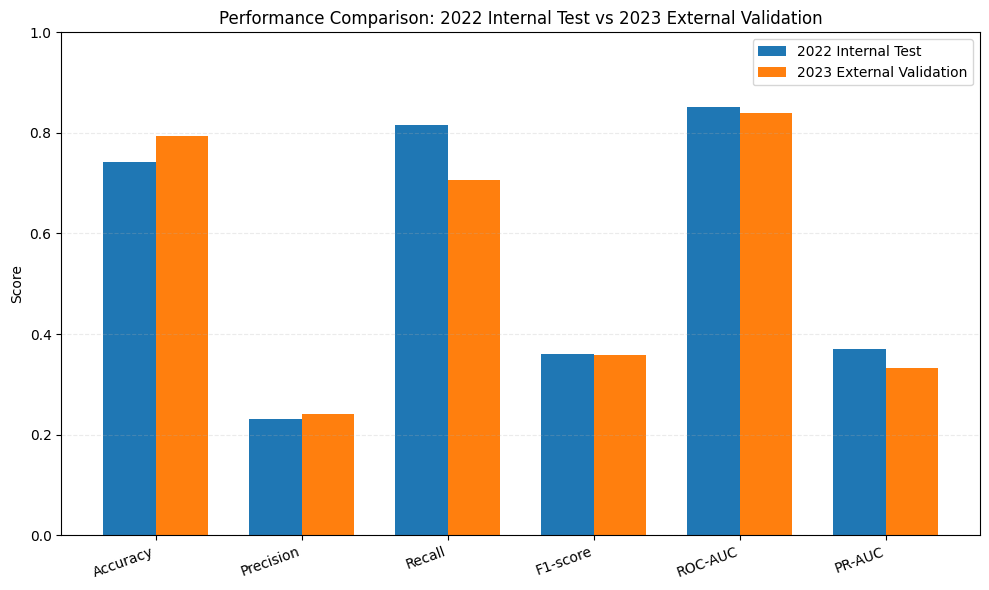


✓ Figure saved:
/content/drive/MyDrive/CVD EX/external_validation_2023/figure_2022_vs_2023_performance_comparison.png
/content/drive/MyDrive/CVD EX/external_validation_2023/figure_2022_vs_2023_performance_comparison.pdf

✓ STEP 2 COMPLETED SUCCESSFULLY
✓ Existing 2023 metrics reused
✓ Existing 2022 final metrics used
✓ No model retraining
✓ No prediction recalculation
✓ No threshold optimization
✓ Frozen final threshold: 0.36458617702918966
✓ Comparison CSV created
✓ Publication table created
✓ PNG figure created at 300 DPI
✓ PDF figure created
✓ Outputs written ONLY to:
/content/drive/MyDrive/CVD EX/external_validation_2023


In [ ]:
# ================================================================
# STEP 2 — 2022 vs 2023 EXTERNAL VALIDATION COMPARISON
# FIXED VERSION
#
# No retraining
# No prediction
# No threshold optimization
# Uses existing 2023 metrics only
# ================================================================

import os
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# ================================================================
# 0. SAFETY
# ================================================================

EXTERNAL_BASE = '/content/drive/MyDrive/CVD EX/external_validation_2023'

assert '/CVD EX/' in EXTERNAL_BASE
assert not EXTERNAL_BASE.rstrip('/').endswith('/CVD')

os.makedirs(EXTERNAL_BASE, exist_ok=True)

print("=" * 75)
print("STEP 2 — 2022 vs 2023 EXTERNAL VALIDATION COMPARISON")
print("=" * 75)
print("Output folder:", EXTERNAL_BASE)

# ================================================================
# 1. LOAD EXISTING 2023 METRICS
# ================================================================

METRICS_2023 = os.path.join(
    EXTERNAL_BASE,
    'external_validation_2023_metrics.csv'
)

if not os.path.exists(METRICS_2023):
    raise FileNotFoundError(
        f"\n2023 metrics file not found:\n{METRICS_2023}"
    )

metrics_2023_raw = pd.read_csv(METRICS_2023)

print("\n✓ 2023 metrics file found")
print("Shape:", metrics_2023_raw.shape)
print("Columns:", metrics_2023_raw.columns.tolist())

# ================================================================
# 2. VERIFY REQUIRED COLUMNS
# ================================================================

required_2023_cols = [
    'Model',
    'Threshold',
    'Accuracy',
    'Precision',
    'Recall_Sensitivity',
    'Specificity',
    'F1',
    'ROC_AUC',
    'PR_AUC'
]

missing_cols = [
    c for c in required_2023_cols
    if c not in metrics_2023_raw.columns
]

if missing_cols:
    raise ValueError(
        "Required columns missing from 2023 metrics file:\n"
        + str(missing_cols)
    )

print("✓ All required 2023 metric columns present")

# ================================================================
# 3. SHOW ACTUAL MODEL NAMES
# ================================================================

print("\nActual Model values in 2023 metrics:")
print(metrics_2023_raw['Model'].tolist())

# ================================================================
# 4. IDENTIFY WEIGHTED ENSEMBLE
#
# The saved CSV has 5 rows:
# 4 base models + 1 ensemble.
#
# Instead of assuming the exact ensemble label,
# identify it as the row that is NOT one of the four
# base learner names.
# ================================================================

BASE_MODEL_NAMES = {
    'random_forest',
    'xgboost',
    'lightgbm',
    'catboost'
}

ensemble_candidates = metrics_2023_raw[
    ~metrics_2023_raw['Model']
    .astype(str)
    .str.lower()
    .isin(BASE_MODEL_NAMES)
].copy()

if len(ensemble_candidates) != 1:

    print("\n⚠ Could not uniquely identify ensemble row.")
    print("Candidate rows:")
    display(ensemble_candidates)

    raise ValueError(
        "\nExpected exactly ONE ensemble row, "
        f"but found {len(ensemble_candidates)}."
    )

ens23 = ensemble_candidates.iloc[0]

ensemble_name_2023 = str(ens23['Model'])

print("\n✓ Ensemble row identified:")
print("  Model:", ensemble_name_2023)

# ================================================================
# 5. EXACT 2022 FINAL TEST METRICS
#
# These values are from the actual final training output.
#
# Final model:
# Weighted Ensemble
# F1-constrained threshold
# Threshold = 0.36458617702918966
# ================================================================

metrics_2022 = {
    'Dataset': '2022 Internal Test',

    'Threshold': 0.36458617702918966,

    'Accuracy': 0.741969,

    'Precision': 0.231769,

    'Recall_Sensitivity': 0.816352,

    'Specificity': np.nan,

    'F1': 0.361037,

    'ROC_AUC': 0.851792,

    'PR_AUC': 0.369912
}

# ================================================================
# 6. EXTRACT 2023 FINAL ENSEMBLE METRICS
# ================================================================

metrics_2023 = {
    'Dataset': '2023 External Validation',

    'Threshold': float(ens23['Threshold']),

    'Accuracy': float(ens23['Accuracy']),

    'Precision': float(ens23['Precision']),

    'Recall_Sensitivity': float(
        ens23['Recall_Sensitivity']
    ),

    'Specificity': float(
        ens23['Specificity']
    ),

    'F1': float(ens23['F1']),

    'ROC_AUC': float(ens23['ROC_AUC']),

    'PR_AUC': float(ens23['PR_AUC'])
}

# ================================================================
# 7. BUILD MAIN COMPARISON TABLE
# ================================================================

metric_cols = [
    'Threshold',
    'Accuracy',
    'Precision',
    'Recall_Sensitivity',
    'Specificity',
    'F1',
    'ROC_AUC',
    'PR_AUC'
]

comparison = pd.DataFrame([
    metrics_2022,
    metrics_2023
])

# ================================================================
# 8. CALCULATE ABSOLUTE CHANGE
#
# 2023 External Validation − 2022 Internal Test
# ================================================================

change_row = {
    'Dataset': 'Change (2023 − 2022)'
}

for col in metric_cols:

    v22 = metrics_2022[col]
    v23 = metrics_2023[col]

    if pd.isna(v22) or pd.isna(v23):
        change_row[col] = np.nan
    else:
        change_row[col] = v23 - v22

# ================================================================
# 9. CALCULATE PERCENTAGE CHANGE
# ================================================================

percent_change_row = {
    'Dataset': 'Percentage Change (%)'
}

for col in metric_cols:

    v22 = metrics_2022[col]
    v23 = metrics_2023[col]

    if pd.isna(v22) or pd.isna(v23) or v22 == 0:
        percent_change_row[col] = np.nan
    else:
        percent_change_row[col] = (
            (v23 - v22) / abs(v22)
        ) * 100

# ================================================================
# 10. FULL COMPARISON TABLE
# ================================================================

comparison_full = pd.concat(
    [
        comparison,
        pd.DataFrame([change_row]),
        pd.DataFrame([percent_change_row])
    ],
    ignore_index=True
)

# ================================================================
# 11. SAVE FULL COMPARISON CSV
# ================================================================

COMPARISON_CSV = os.path.join(
    EXTERNAL_BASE,
    'table_2022_vs_2023_external_validation.csv'
)

comparison_full.to_csv(
    COMPARISON_CSV,
    index=False
)

print("\n" + "=" * 75)
print("2022 vs 2023 COMPARISON")
print("=" * 75)

display(
    comparison_full.style.format(
        {
            'Threshold': '{:.6f}',
            'Accuracy': '{:.6f}',
            'Precision': '{:.6f}',
            'Recall_Sensitivity': '{:.6f}',
            'Specificity': '{:.6f}',
            'F1': '{:.6f}',
            'ROC_AUC': '{:.6f}',
            'PR_AUC': '{:.6f}'
        },
        na_rep='—'
    )
)

print("\n✓ Full comparison CSV saved:")
print(COMPARISON_CSV)

# ================================================================
# 12. PUBLICATION-FRIENDLY TABLE
# ================================================================

publication_table = pd.DataFrame({
    'Metric': [
        'Threshold',
        'Accuracy',
        'Precision',
        'Recall / Sensitivity',
        'Specificity',
        'F1-score',
        'ROC-AUC',
        'PR-AUC'
    ],

    '2022 Internal Test': [
        metrics_2022['Threshold'],
        metrics_2022['Accuracy'],
        metrics_2022['Precision'],
        metrics_2022['Recall_Sensitivity'],
        metrics_2022['Specificity'],
        metrics_2022['F1'],
        metrics_2022['ROC_AUC'],
        metrics_2022['PR_AUC']
    ],

    '2023 External Validation': [
        metrics_2023['Threshold'],
        metrics_2023['Accuracy'],
        metrics_2023['Precision'],
        metrics_2023['Recall_Sensitivity'],
        metrics_2023['Specificity'],
        metrics_2023['F1'],
        metrics_2023['ROC_AUC'],
        metrics_2023['PR_AUC']
    ]
})

PUBLICATION_CSV = os.path.join(
    EXTERNAL_BASE,
    'table_2022_vs_2023_publication.csv'
)

publication_table.to_csv(
    PUBLICATION_CSV,
    index=False
)

print("\n✓ Publication table saved:")
print(PUBLICATION_CSV)

display(
    publication_table.style.format(
        {
            '2022 Internal Test': '{:.6f}',
            '2023 External Validation': '{:.6f}'
        },
        na_rep='—'
    )
)

# ================================================================
# 13. FIGURE — 2022 vs 2023 PERFORMANCE
#
# PNG = 300 DPI
# PDF = vector format for Word/manuscript
# ================================================================

plot_metrics = [
    'Accuracy',
    'Precision',
    'Recall_Sensitivity',
    'F1',
    'ROC_AUC',
    'PR_AUC'
]

plot_labels = [
    'Accuracy',
    'Precision',
    'Recall',
    'F1-score',
    'ROC-AUC',
    'PR-AUC'
]

values_2022 = [
    metrics_2022[m]
    for m in plot_metrics
]

values_2023 = [
    metrics_2023[m]
    for m in plot_metrics
]

x = np.arange(len(plot_labels))
width = 0.36

fig, ax = plt.subplots(figsize=(10, 6))

ax.bar(
    x - width / 2,
    values_2022,
    width,
    label='2022 Internal Test'
)

ax.bar(
    x + width / 2,
    values_2023,
    width,
    label='2023 External Validation'
)

ax.set_ylabel('Score')

ax.set_title(
    'Performance Comparison: 2022 Internal Test vs 2023 External Validation'
)

ax.set_xticks(x)
ax.set_xticklabels(
    plot_labels,
    rotation=20,
    ha='right'
)

ax.set_ylim(0, 1.0)

ax.legend()

ax.grid(
    axis='y',
    linestyle='--',
    alpha=0.25
)

plt.tight_layout()

FIG_PNG = os.path.join(
    EXTERNAL_BASE,
    'figure_2022_vs_2023_performance_comparison.png'
)

FIG_PDF = os.path.join(
    EXTERNAL_BASE,
    'figure_2022_vs_2023_performance_comparison.pdf'
)

fig.savefig(
    FIG_PNG,
    dpi=300,
    bbox_inches='tight'
)

fig.savefig(
    FIG_PDF,
    bbox_inches='tight'
)

plt.show()
plt.close(fig)

print("\n✓ Figure saved:")
print(FIG_PNG)
print(FIG_PDF)

# ================================================================
# 14. FINAL SAFETY / COMPLETION CHECK
# ================================================================

assert os.path.exists(COMPARISON_CSV)
assert os.path.exists(PUBLICATION_CSV)
assert os.path.exists(FIG_PNG)
assert os.path.exists(FIG_PDF)

print("\n" + "=" * 75)
print("✓ STEP 2 COMPLETED SUCCESSFULLY")
print("=" * 75)

print("✓ Existing 2023 metrics reused")
print("✓ Existing 2022 final metrics used")
print("✓ No model retraining")
print("✓ No prediction recalculation")
print("✓ No threshold optimization")
print("✓ Frozen final threshold:", metrics_2022['Threshold'])
print("✓ Comparison CSV created")
print("✓ Publication table created")
print("✓ PNG figure created at 300 DPI")
print("✓ PDF figure created")
print("✓ Outputs written ONLY to:")
print(EXTERNAL_BASE)
print("=" * 75)

STEP 3 — 2023 EXTERNAL VALIDATION ROC CURVES

Prediction file:
/content/drive/MyDrive/CVD EX/external_validation_2023/external_validation_2023_predictions.csv

Number of external records: 402,225

True-label column:
  HeartDisease_Actual

Class distribution:
  Negative (0): 369,475
  Positive (1): 32,750
  Prevalence:    0.081422 (8.1422%)

2023 EXTERNAL VALIDATION — ROC-AUC
Random Forest       : ROC-AUC = 0.835533
XGBoost             : ROC-AUC = 0.839902
LightGBM            : ROC-AUC = 0.839481
CatBoost            : ROC-AUC = 0.840134
Weighted Ensemble   : ROC-AUC = 0.840520


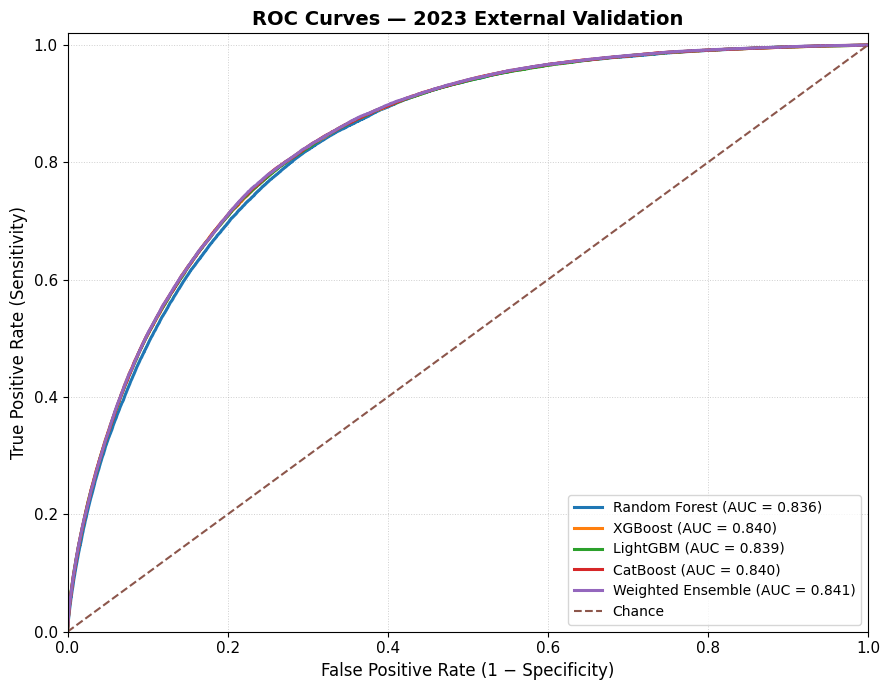


ROC ANALYSIS COMPLETED SUCCESSFULLY

Models included:
  Random Forest        → RF_Probability
  XGBoost              → XGB_Probability
  LightGBM             → LGBM_Probability
  CatBoost             → CatBoost_Probability
  Weighted Ensemble    → Ensemble_Probability

Saved files:

PNG (300 DPI):
/content/drive/MyDrive/CVD EX/external_validation_2023/figure_2023_external_validation_ROC.png

PDF:
/content/drive/MyDrive/CVD EX/external_validation_2023/figure_2023_external_validation_ROC.pdf

Validation integrity:
  ✓ Existing 2023 predictions used
  ✓ No model retraining
  ✓ No model refitting
  ✓ No new predictions generated
  ✓ No 2023 threshold optimization
  ✓ ROC calculated from full probability range
  ✓ 4 base models + Weighted Ensemble


In [ ]:
# ============================================================
# STEP 3 — 2023 EXTERNAL VALIDATION: ROC CURVES
# 4 BASE MODELS + WEIGHTED ENSEMBLE
# Uses ONLY existing prediction CSV
# ============================================================

import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.metrics import roc_curve, roc_auc_score

# ------------------------------------------------------------
# 1. PATHS
# ------------------------------------------------------------
EXTERNAL_DIR = "/content/drive/MyDrive/CVD EX/external_validation_2023"

PREDICTION_FILE = os.path.join(
    EXTERNAL_DIR,
    "external_validation_2023_predictions.csv"
)

ROC_PNG = os.path.join(
    EXTERNAL_DIR,
    "figure_2023_external_validation_ROC.png"
)

ROC_PDF = os.path.join(
    EXTERNAL_DIR,
    "figure_2023_external_validation_ROC.pdf"
)

# ------------------------------------------------------------
# 2. LOAD EXISTING 2023 PREDICTIONS
# ------------------------------------------------------------
if not os.path.exists(PREDICTION_FILE):
    raise FileNotFoundError(
        f"Prediction file not found:\n{PREDICTION_FILE}"
    )

pred_df = pd.read_csv(PREDICTION_FILE)

print("=" * 70)
print("STEP 3 — 2023 EXTERNAL VALIDATION ROC CURVES")
print("=" * 70)

print("\nPrediction file:")
print(PREDICTION_FILE)

print(f"\nNumber of external records: {len(pred_df):,}")

# ------------------------------------------------------------
# 3. EXACT COLUMNS FROM EXISTING CSV
# ------------------------------------------------------------
target_col = "HeartDisease_Actual"

prob_cols = {
    "Random Forest": "RF_Probability",
    "XGBoost": "XGB_Probability",
    "LightGBM": "LGBM_Probability",
    "CatBoost": "CatBoost_Probability",
    "Weighted Ensemble": "Ensemble_Probability"
}

required_cols = [target_col] + list(prob_cols.values())

missing_cols = [
    col for col in required_cols
    if col not in pred_df.columns
]

if missing_cols:
    raise ValueError(
        "The following required columns are missing:\n"
        f"{missing_cols}\n\n"
        f"Available columns:\n{pred_df.columns.tolist()}"
    )

# ------------------------------------------------------------
# 4. TRUE LABELS
# ------------------------------------------------------------
y_true = pd.to_numeric(
    pred_df[target_col],
    errors="coerce"
)

if y_true.isna().any():
    raise ValueError(
        f"Column '{target_col}' contains missing/non-numeric values."
    )

y_true = y_true.astype(int).to_numpy()

# ------------------------------------------------------------
# 5. VERIFY BINARY TARGET
# ------------------------------------------------------------
unique_classes = np.unique(y_true)

if not np.array_equal(unique_classes, [0, 1]):
    raise ValueError(
        f"Unexpected target values found: {unique_classes}"
    )

print("\nTrue-label column:")
print(f"  {target_col}")

print("\nClass distribution:")
print(f"  Negative (0): {(y_true == 0).sum():,}")
print(f"  Positive (1): {(y_true == 1).sum():,}")
print(
    f"  Prevalence:    {y_true.mean():.6f} "
    f"({y_true.mean() * 100:.4f}%)"
)

# ------------------------------------------------------------
# 6. CALCULATE ROC CURVES
# ------------------------------------------------------------
roc_results = {}

for model_name, prob_col in prob_cols.items():

    y_prob = pd.to_numeric(
        pred_df[prob_col],
        errors="coerce"
    )

    if y_prob.isna().any():
        raise ValueError(
            f"Column '{prob_col}' contains "
            "missing/non-numeric probability values."
        )

    y_prob = y_prob.to_numpy(dtype=float)

    # Probability sanity check
    if np.any(y_prob < 0) or np.any(y_prob > 1):
        raise ValueError(
            f"Probability values in '{prob_col}' "
            "are outside the valid [0, 1] range."
        )

    fpr, tpr, thresholds = roc_curve(
        y_true,
        y_prob
    )

    auc_value = roc_auc_score(
        y_true,
        y_prob
    )

    roc_results[model_name] = {
        "fpr": fpr,
        "tpr": tpr,
        "thresholds": thresholds,
        "auc": auc_value
    }

# ------------------------------------------------------------
# 7. DISPLAY ROC-AUC VALUES
# ------------------------------------------------------------
print("\n" + "=" * 70)
print("2023 EXTERNAL VALIDATION — ROC-AUC")
print("=" * 70)

for model_name, result in roc_results.items():
    print(
        f"{model_name:20s}: "
        f"ROC-AUC = {result['auc']:.6f}"
    )

# ------------------------------------------------------------
# 8. CREATE PUBLICATION-QUALITY ROC FIGURE
# ------------------------------------------------------------
plt.figure(figsize=(9, 7))

for model_name, result in roc_results.items():

    plt.plot(
        result["fpr"],
        result["tpr"],
        linewidth=2.2,
        label=(
            f"{model_name} "
            f"(AUC = {result['auc']:.3f})"
        )
    )

# Chance/reference line
plt.plot(
    [0, 1],
    [0, 1],
    linestyle="--",
    linewidth=1.5,
    label="Chance"
)

plt.xlabel(
    "False Positive Rate (1 − Specificity)",
    fontsize=12
)

plt.ylabel(
    "True Positive Rate (Sensitivity)",
    fontsize=12
)

plt.title(
    "ROC Curves — 2023 External Validation",
    fontsize=14,
    fontweight="bold"
)

plt.xlim(0, 1)
plt.ylim(0, 1.02)

plt.xticks(fontsize=11)
plt.yticks(fontsize=11)

plt.legend(
    loc="lower right",
    fontsize=10,
    frameon=True
)

plt.grid(
    True,
    linestyle=":",
    linewidth=0.7,
    alpha=0.6
)

plt.tight_layout()

# ------------------------------------------------------------
# 9. SAVE PNG — 300 DPI
# ------------------------------------------------------------
plt.savefig(
    ROC_PNG,
    dpi=300,
    bbox_inches="tight"
)

# ------------------------------------------------------------
# 10. SAVE PDF
# ------------------------------------------------------------
plt.savefig(
    ROC_PDF,
    bbox_inches="tight"
)

plt.show()
plt.close()

# ------------------------------------------------------------
# 11. FINAL CONFIRMATION
# ------------------------------------------------------------
print("\n" + "=" * 70)
print("ROC ANALYSIS COMPLETED SUCCESSFULLY")
print("=" * 70)

print("\nModels included:")
for model_name, prob_col in prob_cols.items():
    print(f"  {model_name:20s} → {prob_col}")

print("\nSaved files:")

print(f"\nPNG (300 DPI):")
print(ROC_PNG)

print(f"\nPDF:")
print(ROC_PDF)

print("\nValidation integrity:")
print("  ✓ Existing 2023 predictions used")
print("  ✓ No model retraining")
print("  ✓ No model refitting")
print("  ✓ No new predictions generated")
print("  ✓ No 2023 threshold optimization")
print("  ✓ ROC calculated from full probability range")
print("  ✓ 4 base models + Weighted Ensemble")
print("=" * 70)

STEP 4 — 2023 EXTERNAL VALIDATION PRECISION-RECALL CURVES

Prediction file:
/content/drive/MyDrive/CVD EX/external_validation_2023/external_validation_2023_predictions.csv

Number of external records: 402,225

True-label column:
  HeartDisease_Actual

Class distribution:
  Negative (0): 369,475
  Positive (1): 32,750
  Prevalence:    0.081422 (8.1422%)

2023 EXTERNAL VALIDATION — PR-AUC
Random Forest       : PR-AUC = 0.315164
XGBoost             : PR-AUC = 0.331950
LightGBM            : PR-AUC = 0.331501
CatBoost            : PR-AUC = 0.330191
Weighted Ensemble   : PR-AUC = 0.331642

PR baseline (positive-class prevalence):
  0.081422 (8.1422%)


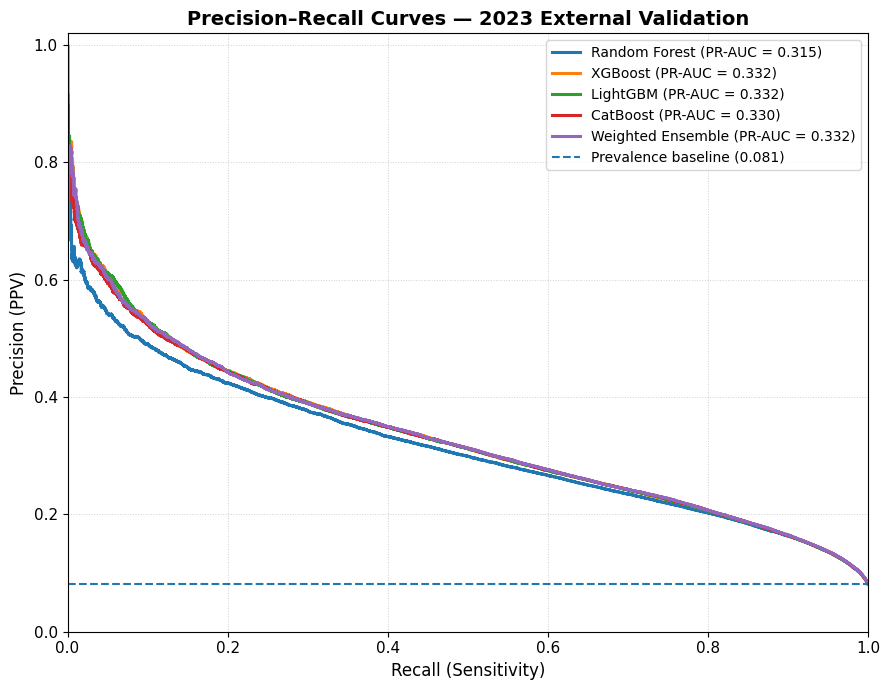


PRECISION-RECALL ANALYSIS COMPLETED SUCCESSFULLY

Models included:
  Random Forest        → RF_Probability
  XGBoost              → XGB_Probability
  LightGBM             → LGBM_Probability
  CatBoost             → CatBoost_Probability
  Weighted Ensemble    → Ensemble_Probability

Saved files:

PNG (300 DPI):
/content/drive/MyDrive/CVD EX/external_validation_2023/figure_2023_external_validation_PR.png

PDF:
/content/drive/MyDrive/CVD EX/external_validation_2023/figure_2023_external_validation_PR.pdf

Validation integrity:
  ✓ Existing 2023 predictions used
  ✓ No model retraining
  ✓ No model refitting
  ✓ No new predictions generated
  ✓ No 2023 threshold optimization
  ✓ PR curves calculated from probability scores
  ✓ Prevalence baseline included
  ✓ 4 base models + Weighted Ensemble


In [ ]:
# ============================================================
# STEP 4 — 2023 EXTERNAL VALIDATION: PRECISION-RECALL CURVES
# 4 BASE MODELS + WEIGHTED ENSEMBLE
# Uses ONLY existing prediction CSV
# ============================================================

import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.metrics import (
    precision_recall_curve,
    average_precision_score
)

# ------------------------------------------------------------
# 1. PATHS
# ------------------------------------------------------------
EXTERNAL_DIR = "/content/drive/MyDrive/CVD EX/external_validation_2023"

PREDICTION_FILE = os.path.join(
    EXTERNAL_DIR,
    "external_validation_2023_predictions.csv"
)

PR_PNG = os.path.join(
    EXTERNAL_DIR,
    "figure_2023_external_validation_PR.png"
)

PR_PDF = os.path.join(
    EXTERNAL_DIR,
    "figure_2023_external_validation_PR.pdf"
)

# ------------------------------------------------------------
# 2. LOAD EXISTING 2023 PREDICTIONS ONLY
# ------------------------------------------------------------
if not os.path.exists(PREDICTION_FILE):
    raise FileNotFoundError(
        f"Prediction file not found:\n{PREDICTION_FILE}"
    )

pred_df = pd.read_csv(PREDICTION_FILE)

print("=" * 70)
print("STEP 4 — 2023 EXTERNAL VALIDATION PRECISION-RECALL CURVES")
print("=" * 70)

print("\nPrediction file:")
print(PREDICTION_FILE)

print(f"\nNumber of external records: {len(pred_df):,}")

# ------------------------------------------------------------
# 3. EXACT COLUMNS FROM EXISTING CSV
# ------------------------------------------------------------
target_col = "HeartDisease_Actual"

prob_cols = {
    "Random Forest": "RF_Probability",
    "XGBoost": "XGB_Probability",
    "LightGBM": "LGBM_Probability",
    "CatBoost": "CatBoost_Probability",
    "Weighted Ensemble": "Ensemble_Probability"
}

required_cols = [target_col] + list(prob_cols.values())

missing_cols = [
    col for col in required_cols
    if col not in pred_df.columns
]

if missing_cols:
    raise ValueError(
        "The following required columns are missing:\n"
        f"{missing_cols}\n\n"
        f"Available columns:\n{pred_df.columns.tolist()}"
    )

# ------------------------------------------------------------
# 4. TRUE LABELS
# ------------------------------------------------------------
y_true = pd.to_numeric(
    pred_df[target_col],
    errors="coerce"
)

if y_true.isna().any():
    raise ValueError(
        f"Column '{target_col}' contains missing/non-numeric values."
    )

y_true = y_true.astype(int).to_numpy()

# ------------------------------------------------------------
# 5. VERIFY BINARY TARGET
# ------------------------------------------------------------
unique_classes = np.unique(y_true)

if not np.array_equal(unique_classes, [0, 1]):
    raise ValueError(
        f"Unexpected target values found: {unique_classes}"
    )

print("\nTrue-label column:")
print(f"  {target_col}")

print("\nClass distribution:")
print(f"  Negative (0): {(y_true == 0).sum():,}")
print(f"  Positive (1): {(y_true == 1).sum():,}")
print(
    f"  Prevalence:    {y_true.mean():.6f} "
    f"({y_true.mean() * 100:.4f}%)"
)

# ------------------------------------------------------------
# 6. CALCULATE PRECISION-RECALL CURVES
# ------------------------------------------------------------
pr_results = {}

for model_name, prob_col in prob_cols.items():

    y_prob = pd.to_numeric(
        pred_df[prob_col],
        errors="coerce"
    )

    if y_prob.isna().any():
        raise ValueError(
            f"Column '{prob_col}' contains "
            "missing/non-numeric probability values."
        )

    y_prob = y_prob.to_numpy(dtype=float)

    # Probability sanity check
    if np.any(y_prob < 0) or np.any(y_prob > 1):
        raise ValueError(
            f"Probability values in '{prob_col}' "
            "are outside the valid [0, 1] range."
        )

    precision, recall, thresholds = precision_recall_curve(
        y_true,
        y_prob
    )

    pr_auc = average_precision_score(
        y_true,
        y_prob
    )

    pr_results[model_name] = {
        "precision": precision,
        "recall": recall,
        "thresholds": thresholds,
        "pr_auc": pr_auc
    }

# ------------------------------------------------------------
# 7. DISPLAY PR-AUC VALUES
# ------------------------------------------------------------
print("\n" + "=" * 70)
print("2023 EXTERNAL VALIDATION — PR-AUC")
print("=" * 70)

for model_name, result in pr_results.items():
    print(
        f"{model_name:20s}: "
        f"PR-AUC = {result['pr_auc']:.6f}"
    )

# ------------------------------------------------------------
# 8. BASELINE = PREVALENCE
# ------------------------------------------------------------
prevalence = y_true.mean()

print("\nPR baseline (positive-class prevalence):")
print(f"  {prevalence:.6f} ({prevalence * 100:.4f}%)")

# ------------------------------------------------------------
# 9. CREATE PUBLICATION-QUALITY PR FIGURE
# ------------------------------------------------------------
plt.figure(figsize=(9, 7))

for model_name, result in pr_results.items():

    plt.plot(
        result["recall"],
        result["precision"],
        linewidth=2.2,
        label=(
            f"{model_name} "
            f"(PR-AUC = {result['pr_auc']:.3f})"
        )
    )

# Prevalence baseline
plt.axhline(
    y=prevalence,
    linestyle="--",
    linewidth=1.5,
    label=f"Prevalence baseline ({prevalence:.3f})"
)

plt.xlabel(
    "Recall (Sensitivity)",
    fontsize=12
)

plt.ylabel(
    "Precision (PPV)",
    fontsize=12
)

plt.title(
    "Precision–Recall Curves — 2023 External Validation",
    fontsize=14,
    fontweight="bold"
)

plt.xlim(0, 1)
plt.ylim(0, 1.02)

plt.xticks(fontsize=11)
plt.yticks(fontsize=11)

plt.legend(
    loc="upper right",
    fontsize=10,
    frameon=True
)

plt.grid(
    True,
    linestyle=":",
    linewidth=0.7,
    alpha=0.6
)

plt.tight_layout()

# ------------------------------------------------------------
# 10. SAVE PNG — 300 DPI
# ------------------------------------------------------------
plt.savefig(
    PR_PNG,
    dpi=300,
    bbox_inches="tight"
)

# ------------------------------------------------------------
# 11. SAVE PDF
# ------------------------------------------------------------
plt.savefig(
    PR_PDF,
    bbox_inches="tight"
)

plt.show()
plt.close()

# ------------------------------------------------------------
# 12. FINAL CONFIRMATION
# ------------------------------------------------------------
print("\n" + "=" * 70)
print("PRECISION-RECALL ANALYSIS COMPLETED SUCCESSFULLY")
print("=" * 70)

print("\nModels included:")
for model_name, prob_col in prob_cols.items():
    print(f"  {model_name:20s} → {prob_col}")

print("\nSaved files:")

print("\nPNG (300 DPI):")
print(PR_PNG)

print("\nPDF:")
print(PR_PDF)

print("\nValidation integrity:")
print("  ✓ Existing 2023 predictions used")
print("  ✓ No model retraining")
print("  ✓ No model refitting")
print("  ✓ No new predictions generated")
print("  ✓ No 2023 threshold optimization")
print("  ✓ PR curves calculated from probability scores")
print("  ✓ Prevalence baseline included")
print("  ✓ 4 base models + Weighted Ensemble")
print("=" * 70)

STEP 5 — 2023 EXTERNAL VALIDATION CALIBRATION ANALYSIS

Prediction file:
/content/drive/MyDrive/CVD EX/external_validation_2023/external_validation_2023_predictions.csv

Number of external records: 402,225

Columns used:
  Actual outcome      → HeartDisease_Actual
  Ensemble probability → Ensemble_Probability

Class distribution:
  Negative (0): 369,475
  Positive (1): 32,750
  Prevalence:    0.081422 (8.1422%)

Ensemble probability range:
  Minimum: 0.015944
  Maximum: 0.790657
  Mean:    0.221542

BRIER SCORE
Brier Score = 0.090420

CALIBRATION TABLE
Calibration_Bin     N  Mean_Predicted_Probability  Observed_Risk  Absolute_Calibration_Error
              1 40223                    0.030193       0.002784                    0.027409
              2 40222                    0.042901       0.004873                    0.038028
              3 40223                    0.061319       0.009447                    0.051871
              4 40222                    0.092889       0.015340     

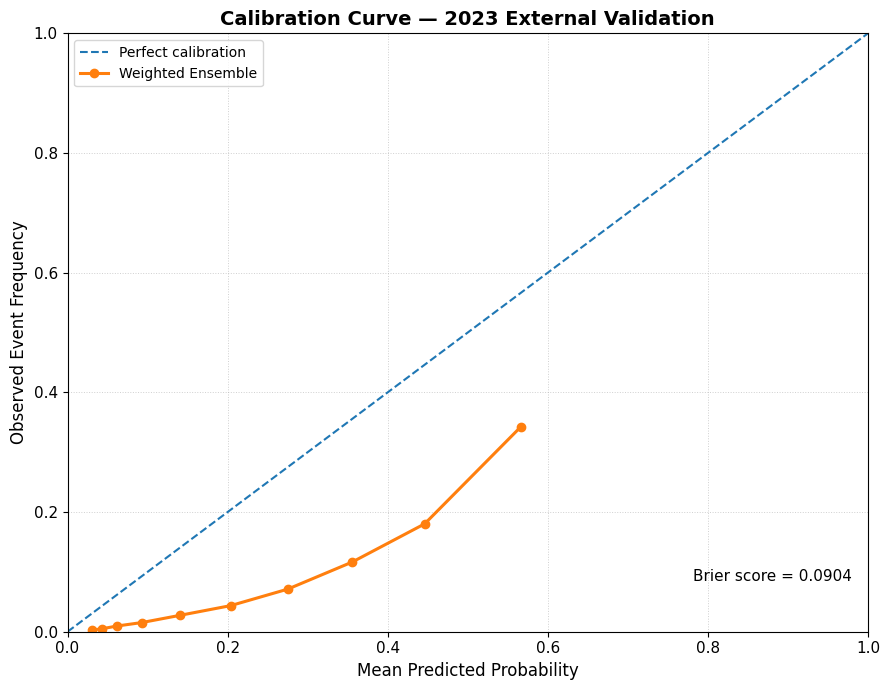


CALIBRATION ANALYSIS COMPLETED SUCCESSFULLY

Brier Score:
  0.090420

Saved files:

Calibration table:
/content/drive/MyDrive/CVD EX/external_validation_2023/table_2023_external_validation_Calibration.csv

PNG (300 DPI):
/content/drive/MyDrive/CVD EX/external_validation_2023/figure_2023_external_validation_Calibration.png

PDF:
/content/drive/MyDrive/CVD EX/external_validation_2023/figure_2023_external_validation_Calibration.pdf

Validation integrity:
  ✓ Existing 2023 predictions used
  ✓ Existing Ensemble_Probability used
  ✓ No model retraining
  ✓ No model refitting
  ✓ No new predictions generated
  ✓ No 2023 threshold optimization
  ✓ Calibration evaluated on external 2023 cohort
  ✓ Brier score calculated
  ✓ Calibration curve generated
  ✓ Calibration table saved


In [ ]:
# ============================================================
# STEP 5 — 2023 EXTERNAL VALIDATION: CALIBRATION ANALYSIS
# WEIGHTED ENSEMBLE
# Uses ONLY existing prediction CSV
# ============================================================

import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.metrics import brier_score_loss
from sklearn.calibration import calibration_curve

# ------------------------------------------------------------
# 1. PATHS
# ------------------------------------------------------------
EXTERNAL_DIR = "/content/drive/MyDrive/CVD EX/external_validation_2023"

PREDICTION_FILE = os.path.join(
    EXTERNAL_DIR,
    "external_validation_2023_predictions.csv"
)

CALIBRATION_PNG = os.path.join(
    EXTERNAL_DIR,
    "figure_2023_external_validation_Calibration.png"
)

CALIBRATION_PDF = os.path.join(
    EXTERNAL_DIR,
    "figure_2023_external_validation_Calibration.pdf"
)

CALIBRATION_CSV = os.path.join(
    EXTERNAL_DIR,
    "table_2023_external_validation_Calibration.csv"
)

# ------------------------------------------------------------
# 2. LOAD EXISTING 2023 PREDICTIONS ONLY
# ------------------------------------------------------------
if not os.path.exists(PREDICTION_FILE):
    raise FileNotFoundError(
        f"Prediction file not found:\n{PREDICTION_FILE}"
    )

pred_df = pd.read_csv(PREDICTION_FILE)

print("=" * 70)
print("STEP 5 — 2023 EXTERNAL VALIDATION CALIBRATION ANALYSIS")
print("=" * 70)

print("\nPrediction file:")
print(PREDICTION_FILE)

print(f"\nNumber of external records: {len(pred_df):,}")

# ------------------------------------------------------------
# 3. EXACT COLUMNS FROM EXISTING CSV
# ------------------------------------------------------------
TARGET_COL = "HeartDisease_Actual"
ENSEMBLE_PROB_COL = "Ensemble_Probability"

required_cols = [
    TARGET_COL,
    ENSEMBLE_PROB_COL
]

missing_cols = [
    col for col in required_cols
    if col not in pred_df.columns
]

if missing_cols:
    raise ValueError(
        "Required columns are missing:\n"
        f"{missing_cols}\n\n"
        f"Available columns:\n{pred_df.columns.tolist()}"
    )

# ------------------------------------------------------------
# 4. EXTRACT TRUE LABELS AND ENSEMBLE PROBABILITIES
# ------------------------------------------------------------
y_true = pd.to_numeric(
    pred_df[TARGET_COL],
    errors="coerce"
)

y_prob = pd.to_numeric(
    pred_df[ENSEMBLE_PROB_COL],
    errors="coerce"
)

if y_true.isna().any():
    raise ValueError(
        f"'{TARGET_COL}' contains missing/non-numeric values."
    )

if y_prob.isna().any():
    raise ValueError(
        f"'{ENSEMBLE_PROB_COL}' contains missing/non-numeric values."
    )

y_true = y_true.astype(int).to_numpy()
y_prob = y_prob.astype(float).to_numpy()

# ------------------------------------------------------------
# 5. DATA VALIDATION
# ------------------------------------------------------------
if not np.array_equal(np.unique(y_true), [0, 1]):
    raise ValueError(
        f"Unexpected target values: {np.unique(y_true)}"
    )

if np.any(y_prob < 0) or np.any(y_prob > 1):
    raise ValueError(
        "Ensemble probabilities contain values outside [0, 1]."
    )

print("\nColumns used:")
print(f"  Actual outcome      → {TARGET_COL}")
print(f"  Ensemble probability → {ENSEMBLE_PROB_COL}")

print("\nClass distribution:")
print(f"  Negative (0): {(y_true == 0).sum():,}")
print(f"  Positive (1): {(y_true == 1).sum():,}")
print(
    f"  Prevalence:    {y_true.mean():.6f} "
    f"({y_true.mean() * 100:.4f}%)"
)

print("\nEnsemble probability range:")
print(f"  Minimum: {y_prob.min():.6f}")
print(f"  Maximum: {y_prob.max():.6f}")
print(f"  Mean:    {y_prob.mean():.6f}")

# ------------------------------------------------------------
# 6. BRIER SCORE
# ------------------------------------------------------------
brier_score = brier_score_loss(
    y_true,
    y_prob
)

print("\n" + "=" * 70)
print("BRIER SCORE")
print("=" * 70)

print(f"Brier Score = {brier_score:.6f}")

# ------------------------------------------------------------
# 7. CALIBRATION CURVE
# ------------------------------------------------------------
n_bins = 10

fraction_of_positives, mean_predicted_value = calibration_curve(
    y_true,
    y_prob,
    n_bins=n_bins,
    strategy="quantile"
)

# ------------------------------------------------------------
# 8. CREATE CALIBRATION TABLE
# ------------------------------------------------------------
# Quantile-based bins ensure observations are reasonably
# distributed across bins.

bin_edges = np.quantile(
    y_prob,
    np.linspace(0, 1, n_bins + 1)
)

# Remove duplicate edges if probability values are tied
bin_edges = np.unique(bin_edges)

# pd.cut requires unique bin boundaries
if len(bin_edges) < 3:
    raise ValueError(
        "Not enough unique probability values to construct "
        "calibration bins."
    )

bin_labels = range(1, len(bin_edges))

calibration_bin = pd.cut(
    y_prob,
    bins=bin_edges,
    labels=bin_labels,
    include_lowest=True,
    duplicates="drop"
)

calibration_df = pd.DataFrame({
    "Calibration_Bin": calibration_bin,
    "Observed_Outcome": y_true,
    "Predicted_Probability": y_prob
})

calibration_table = (
    calibration_df
    .groupby(
        "Calibration_Bin",
        observed=True
    )
    .agg(
        N=("Observed_Outcome", "size"),
        Mean_Predicted_Probability=(
            "Predicted_Probability",
            "mean"
        ),
        Observed_Risk=(
            "Observed_Outcome",
            "mean"
        )
    )
    .reset_index()
)

calibration_table["Absolute_Calibration_Error"] = (
    calibration_table["Mean_Predicted_Probability"]
    - calibration_table["Observed_Risk"]
).abs()

# ------------------------------------------------------------
# 9. DISPLAY CALIBRATION TABLE
# ------------------------------------------------------------
print("\n" + "=" * 70)
print("CALIBRATION TABLE")
print("=" * 70)

print(
    calibration_table.to_string(
        index=False,
        float_format=lambda x: f"{x:.6f}"
    )
)

# ------------------------------------------------------------
# 10. SAVE CALIBRATION TABLE
# ------------------------------------------------------------
calibration_table.to_csv(
    CALIBRATION_CSV,
    index=False
)

# ------------------------------------------------------------
# 11. CREATE PUBLICATION-QUALITY CALIBRATION FIGURE
# ------------------------------------------------------------
plt.figure(figsize=(9, 7))

# Perfect calibration reference
plt.plot(
    [0, 1],
    [0, 1],
    linestyle="--",
    linewidth=1.5,
    label="Perfect calibration"
)

# Ensemble calibration
plt.plot(
    mean_predicted_value,
    fraction_of_positives,
    marker="o",
    markersize=6,
    linewidth=2.2,
    label="Weighted Ensemble"
)

plt.xlabel(
    "Mean Predicted Probability",
    fontsize=12
)

plt.ylabel(
    "Observed Event Frequency",
    fontsize=12
)

plt.title(
    "Calibration Curve — 2023 External Validation",
    fontsize=14,
    fontweight="bold"
)

plt.xlim(0, 1)
plt.ylim(0, 1)

plt.xticks(fontsize=11)
plt.yticks(fontsize=11)

plt.legend(
    loc="upper left",
    fontsize=10,
    frameon=True
)

plt.grid(
    True,
    linestyle=":",
    linewidth=0.7,
    alpha=0.6
)

# Brier score annotation
plt.text(
    0.98,
    0.08,
    f"Brier score = {brier_score:.4f}",
    ha="right",
    va="bottom",
    fontsize=11
)

plt.tight_layout()

# ------------------------------------------------------------
# 12. SAVE PNG — 300 DPI
# ------------------------------------------------------------
plt.savefig(
    CALIBRATION_PNG,
    dpi=300,
    bbox_inches="tight"
)

# ------------------------------------------------------------
# 13. SAVE PDF
# ------------------------------------------------------------
plt.savefig(
    CALIBRATION_PDF,
    bbox_inches="tight"
)

plt.show()
plt.close()

# ------------------------------------------------------------
# 14. FINAL CONFIRMATION
# ------------------------------------------------------------
print("\n" + "=" * 70)
print("CALIBRATION ANALYSIS COMPLETED SUCCESSFULLY")
print("=" * 70)

print("\nBrier Score:")
print(f"  {brier_score:.6f}")

print("\nSaved files:")

print("\nCalibration table:")
print(CALIBRATION_CSV)

print("\nPNG (300 DPI):")
print(CALIBRATION_PNG)

print("\nPDF:")
print(CALIBRATION_PDF)

print("\nValidation integrity:")
print("  ✓ Existing 2023 predictions used")
print("  ✓ Existing Ensemble_Probability used")
print("  ✓ No model retraining")
print("  ✓ No model refitting")
print("  ✓ No new predictions generated")
print("  ✓ No 2023 threshold optimization")
print("  ✓ Calibration evaluated on external 2023 cohort")
print("  ✓ Brier score calculated")
print("  ✓ Calibration curve generated")
print("  ✓ Calibration table saved")
print("=" * 70)

In [ ]:
# ============================================================
# STEP 6 — FINAL 2023 EXTERNAL VALIDATION SUMMARY
# CardioInsight / Weighted Ensemble
# Uses ONLY existing external-validation outputs
# ============================================================

import os
import numpy as np
import pandas as pd
from sklearn.metrics import brier_score_loss

# ------------------------------------------------------------
# 1. PATHS
# ------------------------------------------------------------
EXTERNAL_DIR = "/content/drive/MyDrive/CVD EX/external_validation_2023"

METRICS_FILE = os.path.join(
    EXTERNAL_DIR,
    "external_validation_2023_metrics.csv"
)

PREDICTION_FILE = os.path.join(
    EXTERNAL_DIR,
    "external_validation_2023_predictions.csv"
)

SUMMARY_CSV = os.path.join(
    EXTERNAL_DIR,
    "final_2023_external_validation_summary.csv"
)

# ------------------------------------------------------------
# 2. CHECK FILES
# ------------------------------------------------------------
for file_path in [METRICS_FILE, PREDICTION_FILE]:

    if not os.path.exists(file_path):
        raise FileNotFoundError(
            f"Required file not found:\n{file_path}"
        )

# ------------------------------------------------------------
# 3. LOAD EXISTING FILES ONLY
# ------------------------------------------------------------
metrics_df = pd.read_csv(METRICS_FILE)
pred_df = pd.read_csv(PREDICTION_FILE)

print("=" * 70)
print("STEP 6 — FINAL 2023 EXTERNAL VALIDATION SUMMARY")
print("=" * 70)

print("\nMetrics file:")
print(METRICS_FILE)

print("\nPrediction file:")
print(PREDICTION_FILE)

print(f"\nExternal validation records: {len(pred_df):,}")

# ------------------------------------------------------------
# 4. EXACT COLUMNS REQUIRED
# ------------------------------------------------------------
TARGET_COL = "HeartDisease_Actual"
ENSEMBLE_PROB_COL = "Ensemble_Probability"

required_prediction_cols = [
    TARGET_COL,
    ENSEMBLE_PROB_COL
]

missing_prediction_cols = [
    c for c in required_prediction_cols
    if c not in pred_df.columns
]

if missing_prediction_cols:
    raise ValueError(
        "Missing required prediction columns:\n"
        f"{missing_prediction_cols}\n\n"
        f"Available columns:\n{pred_df.columns.tolist()}"
    )

# ------------------------------------------------------------
# 5. EXTRACT ACTUAL LABELS AND PROBABILITIES
# ------------------------------------------------------------
y_true = pd.to_numeric(
    pred_df[TARGET_COL],
    errors="coerce"
)

y_prob = pd.to_numeric(
    pred_df[ENSEMBLE_PROB_COL],
    errors="coerce"
)

if y_true.isna().any():
    raise ValueError(
        f"'{TARGET_COL}' contains missing/non-numeric values."
    )

if y_prob.isna().any():
    raise ValueError(
        f"'{ENSEMBLE_PROB_COL}' contains missing/non-numeric values."
    )

y_true = y_true.astype(int).to_numpy()
y_prob = y_prob.astype(float).to_numpy()

# ------------------------------------------------------------
# 6. DATA VALIDATION
# ------------------------------------------------------------
if not np.array_equal(np.unique(y_true), [0, 1]):
    raise ValueError(
        f"Unexpected target values: {np.unique(y_true)}"
    )

if np.any(y_prob < 0) or np.any(y_prob > 1):
    raise ValueError(
        "Ensemble probabilities contain values outside [0, 1]."
    )

N = len(y_true)

n_negative = int((y_true == 0).sum())
n_positive = int((y_true == 1).sum())

prevalence = float(y_true.mean())

# ------------------------------------------------------------
# 7. LOAD WEIGHTED ENSEMBLE METRICS
# ------------------------------------------------------------
required_metric_cols = [
    "Model",
    "Threshold",
    "Accuracy",
    "Precision",
    "Recall_Sensitivity",
    "Specificity",
    "F1",
    "ROC_AUC",
    "PR_AUC"
]

missing_metric_cols = [
    c for c in required_metric_cols
    if c not in metrics_df.columns
]

if missing_metric_cols:
    raise ValueError(
        "Missing required columns in metrics file:\n"
        f"{missing_metric_cols}\n\n"
        f"Available columns:\n{metrics_df.columns.tolist()}"
    )

# Find Weighted Ensemble row
ensemble_rows = metrics_df[
    metrics_df["Model"].astype(str).str.lower()
    .isin([
        "weighted_ensemble",
        "weighted ensemble",
        "ensemble"
    ])
]

if ensemble_rows.empty:
    raise ValueError(
        "Weighted Ensemble row was not found in "
        "external_validation_2023_metrics.csv.\n\n"
        f"Models found:\n{metrics_df['Model'].tolist()}"
    )

ensemble_metrics = ensemble_rows.iloc[0]

# ------------------------------------------------------------
# 8. FROZEN THRESHOLD
# ------------------------------------------------------------
final_threshold = float(
    ensemble_metrics["Threshold"]
)

# ------------------------------------------------------------
# 9. BRIER SCORE
# ------------------------------------------------------------
brier_score = brier_score_loss(
    y_true,
    y_prob
)

# ------------------------------------------------------------
# 10. BUILD FINAL SUMMARY
# ------------------------------------------------------------
summary_df = pd.DataFrame([{
    "Dataset": "2023 External Validation",

    "N": N,

    "Negative_N": n_negative,

    "Positive_N": n_positive,

    "Prevalence": prevalence,

    "Prevalence_Percent": prevalence * 100,

    "Frozen_Threshold": final_threshold,

    "Accuracy": float(
        ensemble_metrics["Accuracy"]
    ),

    "Sensitivity_Recall": float(
        ensemble_metrics["Recall_Sensitivity"]
    ),

    "Specificity": float(
        ensemble_metrics["Specificity"]
    ),

    "PPV_Precision": float(
        ensemble_metrics["Precision"]
    ),

    "F1": float(
        ensemble_metrics["F1"]
    ),

    "ROC_AUC": float(
        ensemble_metrics["ROC_AUC"]
    ),

    "PR_AUC": float(
        ensemble_metrics["PR_AUC"]
    ),

    "Brier_Score": brier_score
}])

# ------------------------------------------------------------
# 11. DISPLAY FINAL SUMMARY
# ------------------------------------------------------------
print("\n" + "=" * 70)
print("FINAL EXTERNAL VALIDATION SUMMARY")
print("=" * 70)

display(
    summary_df.style.format({
        "N": "{:,.0f}",
        "Negative_N": "{:,.0f}",
        "Positive_N": "{:,.0f}",
        "Prevalence": "{:.6f}",
        "Prevalence_Percent": "{:.4f}%",
        "Frozen_Threshold": "{:.6f}",
        "Accuracy": "{:.6f}",
        "Sensitivity_Recall": "{:.6f}",
        "Specificity": "{:.6f}",
        "PPV_Precision": "{:.6f}",
        "F1": "{:.6f}",
        "ROC_AUC": "{:.6f}",
        "PR_AUC": "{:.6f}",
        "Brier_Score": "{:.6f}"
    })
)

# ------------------------------------------------------------
# 12. PRINT PUBLICATION-FRIENDLY VALUES
# ------------------------------------------------------------
print("\nPublication-ready values:")
print(f"  N                  = {N:,}")
print(f"  Prevalence         = {prevalence:.4f} ({prevalence*100:.2f}%)")
print(f"  Threshold          = {final_threshold:.6f}")
print(f"  Accuracy           = {ensemble_metrics['Accuracy']:.6f}")
print(f"  Sensitivity        = {ensemble_metrics['Recall_Sensitivity']:.6f}")
print(f"  Specificity        = {ensemble_metrics['Specificity']:.6f}")
print(f"  PPV                = {ensemble_metrics['Precision']:.6f}")
print(f"  F1                 = {ensemble_metrics['F1']:.6f}")
print(f"  ROC-AUC            = {ensemble_metrics['ROC_AUC']:.6f}")
print(f"  PR-AUC             = {ensemble_metrics['PR_AUC']:.6f}")
print(f"  Brier Score        = {brier_score:.6f}")

# ------------------------------------------------------------
# 13. SAVE FINAL SUMMARY
# ------------------------------------------------------------
summary_df.to_csv(
    SUMMARY_CSV,
    index=False
)

# ------------------------------------------------------------
# 14. FINAL CONFIRMATION
# ------------------------------------------------------------
print("\n" + "=" * 70)
print("FINAL EXTERNAL VALIDATION SUMMARY SAVED")
print("=" * 70)

print("\nSaved file:")
print(SUMMARY_CSV)

print("\nValidation integrity:")
print("  ✓ Existing 2023 metrics used")
print("  ✓ Existing 2023 probabilities used")
print("  ✓ Weighted Ensemble evaluated")
print("  ✓ Frozen 2022 threshold retained")
print("  ✓ No model retraining")
print("  ✓ No model refitting")
print("  ✓ No new predictions generated")
print("  ✓ No 2023 threshold optimization")
print("  ✓ Brier score calculated from existing probabilities")
print("=" * 70)

STEP 6 — FINAL 2023 EXTERNAL VALIDATION SUMMARY

Metrics file:
/content/drive/MyDrive/CVD EX/external_validation_2023/external_validation_2023_metrics.csv

Prediction file:
/content/drive/MyDrive/CVD EX/external_validation_2023/external_validation_2023_predictions.csv

External validation records: 402,225

FINAL EXTERNAL VALIDATION SUMMARY


,Dataset,N,Negative_N,Positive_N,Prevalence,Prevalence_Percent,Frozen_Threshold,Accuracy,Sensitivity_Recall,Specificity,PPV_Precision,F1,ROC_AUC,PR_AUC,Brier_Score
0,2023 External Validation,"402,225","369,475","32,750",0.081422,8.1422%,0.364586,0.794575,0.706107,0.802417,0.240567,0.358869,0.840520,0.331642,0.090420



Publication-ready values:
  N                  = 402,225
  Prevalence         = 0.0814 (8.14%)
  Threshold          = 0.364586
  Accuracy           = 0.794575
  Sensitivity        = 0.706107
  Specificity        = 0.802417
  PPV                = 0.240567
  F1                 = 0.358869
  ROC-AUC            = 0.840520
  PR-AUC             = 0.331642
  Brier Score        = 0.090420

FINAL EXTERNAL VALIDATION SUMMARY SAVED

Saved file:
/content/drive/MyDrive/CVD EX/external_validation_2023/final_2023_external_validation_summary.csv

Validation integrity:
  ✓ Existing 2023 metrics used
  ✓ Existing 2023 probabilities used
  ✓ Weighted Ensemble evaluated
  ✓ Frozen 2022 threshold retained
  ✓ No model retraining
  ✓ No model refitting
  ✓ No new predictions generated
  ✓ No 2023 threshold optimization
  ✓ Brier score calculated from existing probabilities


In [ ]:
import pandas as pd

path = "/content/drive/MyDrive/CVD/figures/table9_individual_vs_ensemble/table9_individual_vs_ensemble.csv"

df = pd.read_csv(path)

print("=" * 80)
print("TABLE 9 — ACTUAL CONTENT")
print("=" * 80)

print("\nShape:", df.shape)

print("\nColumns:")
print(df.columns.tolist())

print("\nIndex:")
print(df.index.tolist())

print("\nFull table:")
display(df)

TABLE 9 — ACTUAL CONTENT

Shape: (5, 8)

Columns:
['Threshold_Strategy', 'Threshold', 'Accuracy', 'Precision', 'Recall', 'F1', 'ROC_AUC', 'PR_AUC']

Index:
[0, 1, 2, 3, 4]

Full table:


,Threshold_Strategy,Threshold,Accuracy,Precision,Recall,F1,ROC_AUC,PR_AUC
0,Weighted Ensemble,0.364586,0.741969,0.231769,0.816352,0.361037,0.851792,0.369912
1,random_forest,0.466209,0.738060,0.227695,0.808302,0.355302,0.846468,0.356635
2,xgboost,0.009793,0.742238,0.231853,0.815597,0.361065,0.851655,0.368602
3,lightgbm,0.502443,0.741924,0.231659,0.815849,0.360855,0.851842,0.368382
4,catboost,0.500565,0.740823,0.231234,0.818365,0.360583,0.851698,0.368662


STEP 6B — FINAL 2022 vs 2023 MODEL PERFORMANCE COMPARISON

✓ 2022 Table 9 found:
/content/drive/MyDrive/CVD/figures/table9_individual_vs_ensemble/table9_individual_vs_ensemble.csv

✓ 2023 external metrics found:
/content/drive/MyDrive/CVD EX/external_validation_2023/external_validation_2023_metrics.csv

✓ saved ensemble weights found:
/content/drive/MyDrive/CVD/models/ensemble/ensemble_weights.pkl

REAL SAVED ENSEMBLE WEIGHTS
random_forest       : 0.212320623
xgboost             : 0.266309892
lightgbm            : 0.254813106
catboost            : 0.266556379
--------------------------------------------------------------------------------
Weight sum: 1.000000000000

2022 TABLE 9 DATA CHECK
2022 columns:
['Threshold_Strategy', 'Threshold', 'Accuracy', 'Precision', 'Recall', 'F1', 'ROC_AUC', 'PR_AUC']

2022 rows:


,Threshold_Strategy,Threshold,Accuracy,Precision,Recall,F1,ROC_AUC,PR_AUC
0,Weighted Ensemble,0.364586,0.741969,0.231769,0.816352,0.361037,0.851792,0.369912
1,random_forest,0.466209,0.738060,0.227695,0.808302,0.355302,0.846468,0.356635
2,xgboost,0.009793,0.742238,0.231853,0.815597,0.361065,0.851655,0.368602
3,lightgbm,0.502443,0.741924,0.231659,0.815849,0.360855,0.851842,0.368382
4,catboost,0.500565,0.740823,0.231234,0.818365,0.360583,0.851698,0.368662



2023 EXTERNAL VALIDATION DATA CHECK
2023 columns:
['Model', 'Threshold', 'Accuracy', 'Precision', 'Recall_Sensitivity', 'Specificity', 'F1', 'ROC_AUC', 'PR_AUC', 'TN', 'FP', 'FN', 'TP']


,Model,Threshold,Accuracy,Precision,Recall_Sensitivity,Specificity,F1,ROC_AUC,PR_AUC,TN,FP,FN,TP
0,random_forest,0.364586,0.709782,0.195173,0.820947,0.699928,0.315369,0.835533,0.315164,258606,110869,5864,26886
1,xgboost,0.364586,0.918580,1.000000,0.000031,1.000000,0.000061,0.839902,0.331950,369475,0,32749,1
2,lightgbm,0.364586,0.696155,0.190445,0.840305,0.683378,0.310515,0.839481,0.331501,252491,116984,5230,27520
3,catboost,0.364586,0.691802,0.188858,0.845282,0.678197,0.308736,0.840134,0.330191,250577,118898,5067,27683
4,Weighted_Ensemble,0.364586,0.794575,0.240567,0.706107,0.802417,0.358869,0.840520,0.331642,296473,73002,9625,23125



2022 models found:
['Weighted Ensemble', 'Random Forest', 'XGBoost', 'LightGBM', 'CatBoost']

2023 models found:
['Random Forest', 'XGBoost', 'LightGBM', 'CatBoost', 'Weighted Ensemble']

FINAL 2022 vs 2023 MODEL PERFORMANCE COMPARISON


,Model,Dataset,Ensemble_Weight,Accuracy,Precision,Recall_Sensitivity,F1,ROC_AUC,PR_AUC
0,Random Forest,2022 Internal Test,0.212321,0.738060,0.227695,0.808302,0.355302,0.846468,0.356635
1,Random Forest,2023 External Validation,0.212321,0.709782,0.195173,0.820947,0.315369,0.835533,0.315164
2,XGBoost,2022 Internal Test,0.266310,0.742238,0.231853,0.815597,0.361065,0.851655,0.368602
3,XGBoost,2023 External Validation,0.266310,0.918580,1.000000,0.000031,0.000061,0.839902,0.331950
4,LightGBM,2022 Internal Test,0.254813,0.741924,0.231659,0.815849,0.360855,0.851842,0.368382
5,LightGBM,2023 External Validation,0.254813,0.696155,0.190445,0.840305,0.310515,0.839481,0.331501
6,CatBoost,2022 Internal Test,0.266556,0.740823,0.231234,0.818365,0.360583,0.851698,0.368662
7,CatBoost,2023 External Validation,0.266556,0.691802,0.188858,0.845282,0.308736,0.840134,0.330191
8,Weighted Ensemble,2022 Internal Test,—,0.741969,0.231769,0.816352,0.361037,0.851792,0.369912
9,Weighted Ensemble,2023 External Validation,—,0.794575,0.240567,0.706107,0.358869,0.840520,0.331642



WEIGHTED ENSEMBLE — 2022 vs 2023


,Model,Dataset,Ensemble_Weight,Accuracy,Precision,Recall_Sensitivity,F1,ROC_AUC,PR_AUC
8,Weighted Ensemble,2022 Internal Test,—,0.741969,0.231769,0.816352,0.361037,0.851792,0.369912
9,Weighted Ensemble,2023 External Validation,—,0.794575,0.240567,0.706107,0.358869,0.840520,0.331642


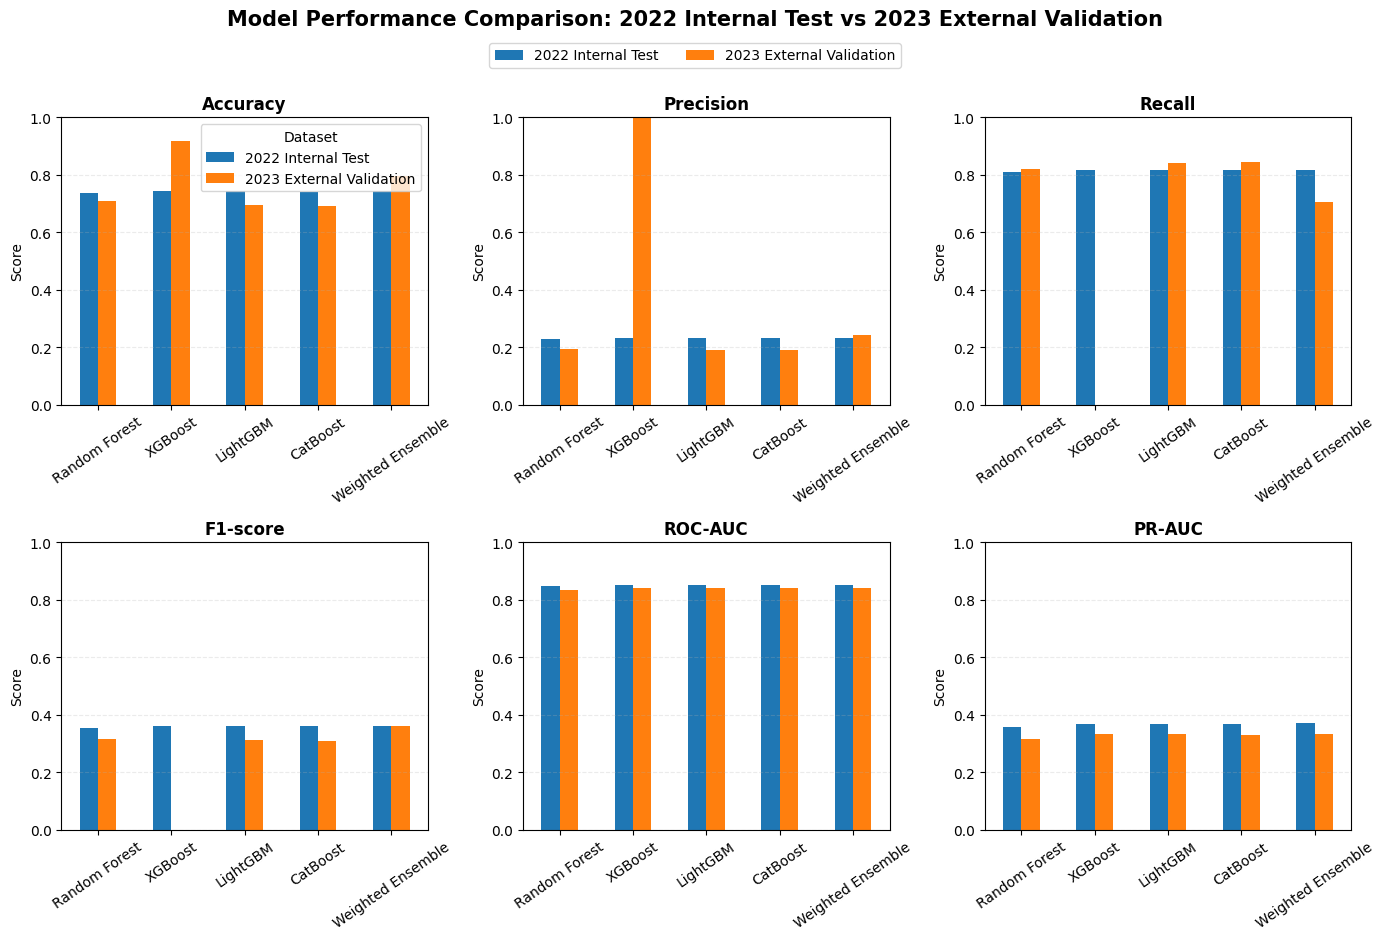


✓ STEP 6B COMPLETED SUCCESSFULLY

REAL DATA SOURCES USED:

✓ 2022 Table 9:
/content/drive/MyDrive/CVD/figures/table9_individual_vs_ensemble/table9_individual_vs_ensemble.csv

✓ 2023 external validation:
/content/drive/MyDrive/CVD EX/external_validation_2023/external_validation_2023_metrics.csv

✓ REAL saved ensemble weights:
/content/drive/MyDrive/CVD/models/ensemble/ensemble_weights.pkl

✓ No performance values were hard-coded.
✓ No ensemble weights were hard-coded.
✓ No model retraining.
✓ No model refitting.
✓ No new prediction.
✓ No threshold optimization.

OUTPUT FILES:

Full comparison CSV:
/content/drive/MyDrive/CVD EX/external_validation_2023/table_2022_vs_2023_model_comparison.csv

Publication comparison CSV:
/content/drive/MyDrive/CVD EX/external_validation_2023/table_2022_vs_2023_model_comparison_publication.csv

PNG — 300 DPI:
/content/drive/MyDrive/CVD EX/external_validation_2023/figure_2022_vs_2023_model_performance_comparison.png

PDF:
/content/drive/MyDrive/CVD EX/exte

In [ ]:
# ================================================================
# STEP 6B — FINAL 2022 vs 2023 MODEL PERFORMANCE COMPARISON
# ================================================================
#
# 2022 = REAL TABLE 9
# 2023 = REAL EXTERNAL VALIDATION METRICS
# Ensemble weights = REAL saved ensemble_weights.pkl
#
# NO retraining
# NO refitting
# NO new prediction
# NO threshold optimization
# NO hard-coded performance values
# ================================================================

import os
import joblib
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# ================================================================
# 0. PATHS
# ================================================================

CVD_BASE = "/content/drive/MyDrive/CVD"

EXTERNAL_BASE = (
    "/content/drive/MyDrive/CVD EX/"
    "external_validation_2023"
)

# ------------------------------------------------
# REAL 2022 TABLE 9
# ------------------------------------------------
METRICS_2022_FILE = os.path.join(
    CVD_BASE,
    "figures",
    "table9_individual_vs_ensemble",
    "table9_individual_vs_ensemble.csv"
)

# ------------------------------------------------
# REAL 2023 EXTERNAL VALIDATION METRICS
# ------------------------------------------------
METRICS_2023_FILE = os.path.join(
    EXTERNAL_BASE,
    "external_validation_2023_metrics.csv"
)

# ------------------------------------------------
# REAL SAVED ENSEMBLE WEIGHTS
# ------------------------------------------------
WEIGHTS_FILE = os.path.join(
    CVD_BASE,
    "models",
    "ensemble",
    "ensemble_weights.pkl"
)

# ------------------------------------------------
# OUTPUTS
# ------------------------------------------------
COMPARISON_CSV = os.path.join(
    EXTERNAL_BASE,
    "table_2022_vs_2023_model_comparison.csv"
)

PUBLICATION_CSV = os.path.join(
    EXTERNAL_BASE,
    "table_2022_vs_2023_model_comparison_publication.csv"
)

COMPARISON_PNG = os.path.join(
    EXTERNAL_BASE,
    "figure_2022_vs_2023_model_performance_comparison.png"
)

COMPARISON_PDF = os.path.join(
    EXTERNAL_BASE,
    "figure_2022_vs_2023_model_performance_comparison.pdf"
)


# ================================================================
# 1. SAFETY CHECKS
# ================================================================

print("=" * 80)
print("STEP 6B — FINAL 2022 vs 2023 MODEL PERFORMANCE COMPARISON")
print("=" * 80)

required_files = {
    "2022 Table 9": METRICS_2022_FILE,
    "2023 external metrics": METRICS_2023_FILE,
    "saved ensemble weights": WEIGHTS_FILE
}

for name, path in required_files.items():

    if not os.path.exists(path):
        raise FileNotFoundError(
            f"\n{name} file not found:\n{path}"
        )

    print(f"\n✓ {name} found:")
    print(path)


# ================================================================
# 2. LOAD REAL EXISTING RESULTS
# ================================================================

df_2022 = pd.read_csv(METRICS_2022_FILE)

df_2023 = pd.read_csv(METRICS_2023_FILE)

ensemble_weights = joblib.load(WEIGHTS_FILE)


# ================================================================
# 3. DISPLAY REAL SAVED WEIGHTS
# ================================================================

print("\n" + "=" * 80)
print("REAL SAVED ENSEMBLE WEIGHTS")
print("=" * 80)

for model, weight in ensemble_weights.items():

    print(
        f"{model:20s}: {float(weight):.9f}"
    )

weight_sum = sum(
    float(v) for v in ensemble_weights.values()
)

print("-" * 80)
print(f"Weight sum: {weight_sum:.12f}")


# ================================================================
# 4. VERIFY SAVED WEIGHTS
# ================================================================

expected_weight_models = [
    "random_forest",
    "xgboost",
    "lightgbm",
    "catboost"
]

if set(ensemble_weights.keys()) != set(
    expected_weight_models
):

    raise ValueError(
        "Saved ensemble weights do not contain "
        "the expected four base models.\n"
        f"Found: {list(ensemble_weights.keys())}"
    )

if not np.isclose(
    weight_sum,
    1.0,
    atol=1e-8
):

    raise ValueError(
        f"Ensemble weights do not sum to 1.\n"
        f"Sum = {weight_sum}"
    )


# ================================================================
# 5. 2022 TABLE 9 — USE Threshold_Strategy AS MODEL
# ================================================================

print("\n" + "=" * 80)
print("2022 TABLE 9 DATA CHECK")
print("=" * 80)

print("2022 columns:")
print(df_2022.columns.tolist())

print("\n2022 rows:")
display(df_2022)


# IMPORTANT:
# Table 9 stores model names in Threshold_Strategy

if "Threshold_Strategy" not in df_2022.columns:

    raise ValueError(
        "Threshold_Strategy column not found "
        "in the REAL 2022 Table 9."
    )

df_2022["Model"] = (
    df_2022["Threshold_Strategy"]
    .astype(str)
    .str.strip()
    .str.lower()
)


# ================================================================
# 6. NORMALIZE 2022 MODEL NAMES
# ================================================================

model_map = {

    "random_forest":
        "Random Forest",

    "random forest":
        "Random Forest",

    "xgboost":
        "XGBoost",

    "xgboostclassifier":
        "XGBoost",

    "lightgbm":
        "LightGBM",

    "lightgbmclassifier":
        "LightGBM",

    "catboost":
        "CatBoost",

    "catboostclassifier":
        "CatBoost",

    "weighted_ensemble":
        "Weighted Ensemble",

    "weighted ensemble":
        "Weighted Ensemble",

    "ensemble":
        "Weighted Ensemble"
}

df_2022["Model"] = (
    df_2022["Model"]
    .replace(model_map)
)


# ================================================================
# 7. 2023 DATA CHECK
# ================================================================

print("\n" + "=" * 80)
print("2023 EXTERNAL VALIDATION DATA CHECK")
print("=" * 80)

print("2023 columns:")
print(df_2023.columns.tolist())

display(df_2023)


# 2023 metrics file should contain Model
if "Model" not in df_2023.columns:

    raise ValueError(
        "Model column not found in the REAL "
        "2023 external validation metrics file."
    )

df_2023["Model"] = (
    df_2023["Model"]
    .astype(str)
    .str.strip()
    .str.lower()
    .replace(model_map)
)


# ================================================================
# 8. EXPECTED MODELS
# ================================================================

expected_models = [
    "Random Forest",
    "XGBoost",
    "LightGBM",
    "CatBoost",
    "Weighted Ensemble"
]

print("\n2022 models found:")
print(df_2022["Model"].tolist())

print("\n2023 models found:")
print(df_2023["Model"].tolist())


# ------------------------------------------------
# Check missing models
# ------------------------------------------------

missing_2022 = [
    m for m in expected_models
    if m not in df_2022["Model"].values
]

missing_2023 = [
    m for m in expected_models
    if m not in df_2023["Model"].values
]

if missing_2022:

    raise ValueError(
        f"Missing models in 2022 Table 9: "
        f"{missing_2022}"
    )

if missing_2023:

    raise ValueError(
        f"Missing models in 2023 external results: "
        f"{missing_2023}"
    )


# ================================================================
# 9. NORMALIZE METRIC COLUMN NAMES
# ================================================================

# ------------------------------------------------
# 2022
# ------------------------------------------------

if "Recall_Sensitivity" not in df_2022.columns:

    if "Recall" in df_2022.columns:

        df_2022["Recall_Sensitivity"] = (
            df_2022["Recall"]
        )

    else:

        raise ValueError(
            "Recall column not found in 2022 Table 9."
        )


# ------------------------------------------------
# 2023
# ------------------------------------------------

if "Recall_Sensitivity" not in df_2023.columns:

    if "Recall" in df_2023.columns:

        df_2023["Recall_Sensitivity"] = (
            df_2023["Recall"]
        )

    else:

        raise ValueError(
            "Recall column not found in 2023 metrics."
        )


# ================================================================
# 10. REQUIRED PERFORMANCE METRICS
# ================================================================

performance_metrics = [

    "Accuracy",
    "Precision",
    "Recall_Sensitivity",
    "F1",
    "ROC_AUC",
    "PR_AUC"
]

required_columns = [
    "Model"
] + performance_metrics


missing_2022_columns = [
    c for c in required_columns
    if c not in df_2022.columns
]

missing_2023_columns = [
    c for c in required_columns
    if c not in df_2023.columns
]


if missing_2022_columns:

    raise ValueError(
        "Missing columns in REAL 2022 Table 9:\n"
        f"{missing_2022_columns}"
    )


if missing_2023_columns:

    raise ValueError(
        "Missing columns in REAL 2023 external metrics:\n"
        f"{missing_2023_columns}"
    )


# ================================================================
# 11. SELECT REAL PERFORMANCE VALUES
# ================================================================

df22 = df_2022[
    required_columns
].copy()

df23 = df_2023[
    required_columns
].copy()


# ================================================================
# 12. DATASET LABELS
# ================================================================

df22["Dataset"] = "2022 Internal Test"

df23["Dataset"] = "2023 External Validation"


# ================================================================
# 13. ADD REAL SAVED ENSEMBLE WEIGHTS
# ================================================================

weight_map_display = {

    "Random Forest":
        float(ensemble_weights["random_forest"]),

    "XGBoost":
        float(ensemble_weights["xgboost"]),

    "LightGBM":
        float(ensemble_weights["lightgbm"]),

    "CatBoost":
        float(ensemble_weights["catboost"]),

    "Weighted Ensemble":
        np.nan
}


df22["Ensemble_Weight"] = (
    df22["Model"]
    .map(weight_map_display)
)

df23["Ensemble_Weight"] = (
    df23["Model"]
    .map(weight_map_display)
)


# ================================================================
# 14. COMBINE 2022 + 2023
# ================================================================

comparison = pd.concat(
    [
        df22,
        df23
    ],
    ignore_index=True
)


# ================================================================
# 15. ORDER MODELS / DATASETS
# ================================================================

comparison["Model"] = pd.Categorical(
    comparison["Model"],
    categories=expected_models,
    ordered=True
)

comparison["Dataset"] = pd.Categorical(
    comparison["Dataset"],
    categories=[
        "2022 Internal Test",
        "2023 External Validation"
    ],
    ordered=True
)

comparison = (
    comparison
    .sort_values(
        ["Model", "Dataset"]
    )
    .reset_index(drop=True)
)


# ================================================================
# 16. FINAL COLUMN ORDER
# ================================================================

comparison = comparison[
    [
        "Model",
        "Dataset",
        "Ensemble_Weight",
        "Accuracy",
        "Precision",
        "Recall_Sensitivity",
        "F1",
        "ROC_AUC",
        "PR_AUC"
    ]
]


# ================================================================
# 17. SAVE FULL COMPARISON TABLE
# ================================================================

comparison.to_csv(
    COMPARISON_CSV,
    index=False
)


# ================================================================
# 18. PUBLICATION TABLE
# ================================================================

publication_table = comparison.copy()

publication_table["Ensemble_Weight"] = (
    publication_table["Ensemble_Weight"]
    .round(6)
)

for col in performance_metrics:

    publication_table[col] = (
        pd.to_numeric(
            publication_table[col],
            errors="coerce"
        )
        .round(6)
    )


publication_table.to_csv(
    PUBLICATION_CSV,
    index=False
)


# ================================================================
# 19. DISPLAY FINAL COMPARISON
# ================================================================

print("\n" + "=" * 80)
print("FINAL 2022 vs 2023 MODEL PERFORMANCE COMPARISON")
print("=" * 80)

display(
    comparison.style.format(
        {
            "Ensemble_Weight": "{:.6f}",
            "Accuracy": "{:.6f}",
            "Precision": "{:.6f}",
            "Recall_Sensitivity": "{:.6f}",
            "F1": "{:.6f}",
            "ROC_AUC": "{:.6f}",
            "PR_AUC": "{:.6f}"
        },
        na_rep="—"
    )
)


# ================================================================
# 20. WEIGHTED ENSEMBLE ONLY
# ================================================================

ensemble_comparison = comparison[
    comparison["Model"]
    == "Weighted Ensemble"
].copy()

print("\n" + "=" * 80)
print("WEIGHTED ENSEMBLE — 2022 vs 2023")
print("=" * 80)

display(
    ensemble_comparison.style.format(
        {
            "Ensemble_Weight": "{:.6f}",
            "Accuracy": "{:.6f}",
            "Precision": "{:.6f}",
            "Recall_Sensitivity": "{:.6f}",
            "F1": "{:.6f}",
            "ROC_AUC": "{:.6f}",
            "PR_AUC": "{:.6f}"
        },
        na_rep="—"
    )
)


# ================================================================
# 21. MODEL-WISE 2022 vs 2023 FIGURE
# ================================================================

plot_metrics = [
    "Accuracy",
    "Precision",
    "Recall_Sensitivity",
    "F1",
    "ROC_AUC",
    "PR_AUC"
]

plot_labels = [
    "Accuracy",
    "Precision",
    "Recall",
    "F1-score",
    "ROC-AUC",
    "PR-AUC"
]


fig, axes = plt.subplots(
    2,
    3,
    figsize=(14, 9)
)

axes = axes.flatten()


for i, (metric, label) in enumerate(
    zip(plot_metrics, plot_labels)
):

    ax = axes[i]

    plot_df = comparison.pivot(
        index="Model",
        columns="Dataset",
        values=metric
    )

    plot_df = plot_df.reindex(
        expected_models
    )

    plot_df.plot(
        kind="bar",
        ax=ax
    )

    ax.set_title(
        label,
        fontsize=12,
        fontweight="bold"
    )

    ax.set_ylabel(
        "Score",
        fontsize=10
    )

    ax.set_xlabel("")

    ax.set_ylim(
        0,
        1
    )

    ax.tick_params(
        axis="x",
        rotation=35
    )

    ax.grid(
        axis="y",
        linestyle="--",
        alpha=0.25
    )

    if i != 0 and ax.legend_ is not None:

        ax.legend_.remove()


# ------------------------------------------------
# Common legend
# ------------------------------------------------

handles, labels = (
    axes[0]
    .get_legend_handles_labels()
)

fig.legend(
    handles,
    labels,
    loc="upper center",
    ncol=2,
    bbox_to_anchor=(0.5, 1.01)
)


fig.suptitle(
    "Model Performance Comparison: "
    "2022 Internal Test vs 2023 External Validation",
    fontsize=15,
    fontweight="bold",
    y=1.04
)

plt.tight_layout()


# ================================================================
# 22. SAVE FIGURES
# ================================================================

fig.savefig(
    COMPARISON_PNG,
    dpi=300,
    bbox_inches="tight"
)

fig.savefig(
    COMPARISON_PDF,
    bbox_inches="tight"
)

plt.show()

plt.close(fig)


# ================================================================
# 23. FINAL ASSERTIONS
# ================================================================

assert os.path.exists(COMPARISON_CSV)

assert os.path.exists(PUBLICATION_CSV)

assert os.path.exists(COMPARISON_PNG)

assert os.path.exists(COMPARISON_PDF)


# ================================================================
# 24. FINAL CONFIRMATION
# ================================================================

print("\n" + "=" * 80)
print("✓ STEP 6B COMPLETED SUCCESSFULLY")
print("=" * 80)

print("\nREAL DATA SOURCES USED:")

print("\n✓ 2022 Table 9:")
print(METRICS_2022_FILE)

print("\n✓ 2023 external validation:")
print(METRICS_2023_FILE)

print("\n✓ REAL saved ensemble weights:")
print(WEIGHTS_FILE)

print("\n✓ No performance values were hard-coded.")
print("✓ No ensemble weights were hard-coded.")
print("✓ No model retraining.")
print("✓ No model refitting.")
print("✓ No new prediction.")
print("✓ No threshold optimization.")

print("\nOUTPUT FILES:")

print("\nFull comparison CSV:")
print(COMPARISON_CSV)

print("\nPublication comparison CSV:")
print(PUBLICATION_CSV)

print("\nPNG — 300 DPI:")
print(COMPARISON_PNG)

print("\nPDF:")
print(COMPARISON_PDF)

print("\n" + "=" * 80)

In [ ]:
# ================================================================
# STEP 5A — 2022 vs 2023 FEATURE-DISTRIBUTION SHIFT
# DATA LOADING + VERIFICATION
#
# Purpose:
# Compare the 2022 internal test cohort with the 2023 external
# validation cohort using the SAME 47 model input features.
#
# IMPORTANT:
# - No model retraining
# - No prediction
# - No threshold optimization
# - No modification of the trained models
# ================================================================

import os
import joblib
import numpy as np
import pandas as pd

print("=" * 80)
print("STEP 5A — FEATURE DISTRIBUTION SHIFT")
print("=" * 80)

# ------------------------------------------------
# 1. PATHS
# ------------------------------------------------

BASE_2022 = "/content/drive/MyDrive/CVD"
EXTERNAL_BASE = "/content/drive/MyDrive/CVD EX/external_validation_2023"

FE_CHECKPOINT = os.path.join(
    BASE_2022,
    "models",
    "fe_checkpoint.pkl"
)

READY_2023 = os.path.join(
    EXTERNAL_BASE,
    "heart_2023_final_47_features_READY.csv"
)

SHIFT_DIR = os.path.join(
    EXTERNAL_BASE,
    "feature_distribution_shift"
)

os.makedirs(SHIFT_DIR, exist_ok=True)

# ------------------------------------------------
# 2. CHECK FILES
# ------------------------------------------------

if not os.path.exists(FE_CHECKPOINT):
    raise FileNotFoundError(
        f"2022 feature checkpoint not found:\n{FE_CHECKPOINT}"
    )

if not os.path.exists(READY_2023):
    raise FileNotFoundError(
        f"2023 READY file not found:\n{READY_2023}"
    )

# ------------------------------------------------
# 3. LOAD 2022 FEATURE CHECKPOINT
# ------------------------------------------------

print("\nLoading 2022 feature-engineering checkpoint...")

fe_checkpoint = joblib.load(FE_CHECKPOINT)

print("Checkpoint keys:")
print(fe_checkpoint.keys())

# ------------------------------------------------
# 4. GET 2022 INTERNAL TEST DATA
# ------------------------------------------------

if "X_test" not in fe_checkpoint:
    raise KeyError(
        "X_test was not found inside fe_checkpoint.pkl"
    )

X22 = fe_checkpoint["X_test"].copy()

print("\n2022 internal test shape:")
print(X22.shape)

# ------------------------------------------------
# 5. LOAD 2023 READY DATA
# ------------------------------------------------

print("\nLoading 2023 READY dataset...")

df23 = pd.read_csv(
    READY_2023,
    low_memory=False
)

if "HeartDisease" not in df23.columns:
    raise KeyError(
        "HeartDisease target column not found in 2023 READY file."
    )

X23 = df23.drop(
    columns=["HeartDisease"]
).copy()

y23 = df23["HeartDisease"].astype(int).copy()

print("\n2023 external shape:")
print(X23.shape)

# ------------------------------------------------
# 6. VERIFY 47 FEATURES
# ------------------------------------------------

if X22.shape[1] != 47:
    raise ValueError(
        f"2022 X_test has {X22.shape[1]} features; expected 47."
    )

if X23.shape[1] != 47:
    raise ValueError(
        f"2023 X23 has {X23.shape[1]} features; expected 47."
    )

# ------------------------------------------------
# 7. VERIFY SAME FEATURE ORDER
# ------------------------------------------------

features_22 = X22.columns.tolist()
features_23 = X23.columns.tolist()

if features_22 != features_23:

    print("\n2022 features:")
    print(features_22)

    print("\n2023 features:")
    print(features_23)

    raise ValueError(
        "2022 and 2023 feature order does not match."
    )

print("\n✓ Same 47 features confirmed.")

# ------------------------------------------------
# 8. CHECK MISSING VALUES
# ------------------------------------------------

missing_22 = X22.isna().sum().sum()
missing_23 = X23.isna().sum().sum()

print("\nMissing values:")
print("2022:", missing_22)
print("2023:", missing_23)

if missing_22 > 0 or missing_23 > 0:
    print(
        "\n⚠ Missing values exist. "
        "We will inspect them before calculating shifts."
    )

# ------------------------------------------------
# 9. PREVALENCE
# ------------------------------------------------

# 2022 target is retrieved from checkpoint if available
if "y_test" in fe_checkpoint:
    y22 = np.asarray(fe_checkpoint["y_test"]).astype(int)
elif "y_test_original" in fe_checkpoint:
    y22 = np.asarray(fe_checkpoint["y_test_original"]).astype(int)
else:
    y22 = None
    print(
        "\n⚠ y_test was not found in checkpoint."
        "\n2022 prevalence will be taken from the known final test result "
        "only if needed separately."
    )

print("\n" + "=" * 80)
print("DATA SUMMARY")
print("=" * 80)

print("2022 internal test:", X22.shape)

if y22 is not None:
    print(
        f"2022 prevalence: {y22.mean():.6f} "
        f"({y22.mean()*100:.4f}%)"
    )

print("2023 external validation:", X23.shape)
print(
    f"2023 prevalence: {y23.mean():.6f} "
    f"({y23.mean()*100:.4f}%)"
)

print("\n✓ STEP 5A completed.")

STEP 5A — FEATURE DISTRIBUTION SHIFT

Loading 2022 feature-engineering checkpoint...
Checkpoint keys:
dict_keys(['X_train', 'X_val', 'X_test'])

2022 internal test shape:
(44514, 47)

Loading 2023 READY dataset...

2023 external shape:
(402225, 47)

✓ Same 47 features confirmed.

Missing values:
2022: 1372
2023: 0

⚠ Missing values exist. We will inspect them before calculating shifts.

⚠ y_test was not found in checkpoint.
2022 prevalence will be taken from the known final test result only if needed separately.

DATA SUMMARY
2022 internal test: (44514, 47)
2023 external validation: (402225, 47)
2023 prevalence: 0.081422 (8.1422%)

✓ STEP 5A completed.


In [ ]:
from sklearn.metrics import roc_auc_score, average_precision_score, recall_score
EXT = '/content/drive/MyDrive/CVD EX/external_validation_2023'

# (i) 2022 test mein 3 unavailable features neutral karo
neutral = {'SleepHours': X_train['SleepHours'].median(),
           'RemovedTeeth': X_train['RemovedTeeth'].mode()[0],
           'HighRiskLastYear': X_train['HighRiskLastYear'].mode()[0]}
def run(cols):
    Xt, Xl = X_test.copy(), X_test_lgbm.copy()
    for c in cols: Xt[c] = neutral[c]; Xl[c] = neutral[c]
    p = ensemble_predict_proba(Xt, Xl); pr = (p >= f1_threshold).astype(int)
    return dict(neutralised=list(cols) or 'none', ROC=roc_auc_score(y_test,p),
                PR=average_precision_score(y_test,p), Recall=recall_score(y_test,pr), PPR=pr.mean())
print(pd.DataFrame([run([]), *[run([c]) for c in neutral], run(list(neutral))]).round(4).to_string(index=False))

# (ii) diagnostic: 2023 par 2022 jitna alert-rate (performance ke taur par report na karein)
pe_ = pd.read_csv(f'{EXT}/external_validation_2023_predictions.csv')
y_e, p_e = pe_['HeartDisease_Actual'].astype(int).values, pe_['Ensemble_Probability'].values
ppr = (ens_proba_test >= f1_threshold).mean(); tm = np.quantile(p_e, 1 - ppr)
print("2023 recall at 2022-matched alert rate:", recall_score(y_e, (p_e >= tm).astype(int)))

# (iii) feature distribution shift (standardized mean difference)
ext = pd.read_csv(f'{EXT}/heart_2023_final_47_features_READY.csv', low_memory=False)
cols = [c for c in X_test.columns if c in ext.columns]
smd = ((ext[cols].mean()-X_test[cols].mean())/np.sqrt((ext[cols].var()+X_test[cols].var())/2)).rename('SMD')
print(smd.reindex(smd.abs().sort_values(ascending=False).index).head(10).round(3))

NameError: name 'X_train' is not defined

In [ ]:
import os

print("Does /content/drive exist?", os.path.exists("/content/drive"))
print("Is /content/drive a directory?", os.path.isdir("/content/drive"))

if os.path.exists("/content/drive"):
    print("\nContents of /content/drive:")
    print(os.listdir("/content/drive")[:20])

Does /content/drive exist? True
Is /content/drive a directory? True

Contents of /content/drive:
['MyDrive']


In [ ]:

import os
import joblib
import numpy as np

BASE = "/content/drive/MyDrive/CVD"

files_to_inspect = [
    "models/fe_checkpoint.pkl",
    "models/preprocessing_checkpoint.pkl",
    "models/encoding_checkpoint.pkl",
    "models/scaling_checkpoint.pkl",
    "models/ensemble/final_threshold.pkl",
    "models/ensemble/best_threshold.pkl",
    "models/ensemble/stack_f1_threshold.pkl",
    "models/ensemble/ensemble_weights.pkl",
    "models/ensemble/2ensemble_weights.pkl",
]

for rel in files_to_inspect:
    path = os.path.join(BASE, rel)
    print("\n" + "=" * 65)
    print(rel)

    if not os.path.exists(path):
        print("FILE NOT FOUND")
        continue

    try:
        obj = joblib.load(path)
        print("Object type:", type(obj).__name__)

        if isinstance(obj, dict):
            print("Keys:", list(obj.keys()))

            for k, v in obj.items():
                if hasattr(v, "shape"):
                    print(f"  {k}: shape={v.shape}")
                elif isinstance(v, (int, float, str, list, tuple)):
                    print(f"  {k}: {repr(v)[:300]}")
                else:
                    print(f"  {k}: type={type(v).__name__}")

        elif isinstance(obj, np.ndarray):
            print("Value:", repr(obj)[:500])

        else:
            print("Value:", repr(obj)[:500])

    except Exception as e:
        print("Inspection error:", repr(e))



models/fe_checkpoint.pkl
Object type: dict
Keys: ['X_train', 'X_val', 'X_test']
  X_train: shape=(354903, 47)
  X_val: shape=(44513, 47)
  X_test: shape=(44514, 47)

models/preprocessing_checkpoint.pkl
Object type: dict
Keys: ['X_train', 'X_val', 'X_test', 'y_train']
  X_train: shape=(354903, 37)
  X_val: shape=(44513, 37)
  X_test: shape=(44514, 37)
  y_train: shape=(354903,)

models/encoding_checkpoint.pkl
Object type: dict
Keys: ['X_train', 'X_val', 'X_test']
  X_train: shape=(354903, 44)
  X_val: shape=(44513, 44)
  X_test: shape=(44514, 44)

models/scaling_checkpoint.pkl
Object type: dict
Keys: ['X_train', 'X_val', 'X_test']
  X_train: shape=(354903, 44)
  X_val: shape=(44513, 44)
  X_test: shape=(44514, 44)

models/ensemble/final_threshold.pkl
Object type: float
Value: 0.364586

models/ensemble/best_threshold.pkl
Object type: float64
Value: np.float64(0.3316376663571651)

models/ensemble/stack_f1_threshold.pkl
Object type: float64
Value: np.float64(0.48807390866738687)

models/e

In [ ]:

import os
import joblib
import pandas as pd

BASE = "/content/drive/MyDrive/CVD"
EXTERNAL = "/content/drive/MyDrive/CVD EX/external_validation_2023"

# A. Print actual saved ensemble weights
for filename in [
    "models/ensemble/ensemble_weights.pkl",
    "models/ensemble/2ensemble_weights.pkl",
]:
    path = os.path.join(BASE, filename)
    weights = joblib.load(path)
    print("\n", filename)
    for name, value in weights.items():
        print(name, "=", repr(value.item() if hasattr(value, "item") else value))

# B. Find candidate files that may contain test labels/predictions
roots = [BASE, EXTERNAL]
keywords = ("prediction", "test", "label", "target", "prob")

print("\n--- Candidate CSV files ---")
for root_dir in roots:
    for root, dirs, files in os.walk(root_dir):
        dirs[:] = [
            d for d in dirs
            if d.lower() not in {"archive", "raw", "temp", "__pycache__"}
        ]
        for name in files:
            if name.lower().endswith(".csv") and any(
                k in name.lower() for k in keywords
            ):
                path = os.path.join(root, name)
                print("\nFile:", path)
                try:
                    # Read only headers and two rows; don't load full datasets
                    sample = pd.read_csv(path, nrows=2, low_memory=False)
                    print("Columns:", sample.columns.tolist())
                except Exception as e:
                    print("Could not inspect:", str(e))



 models/ensemble/ensemble_weights.pkl
random_forest = 0.21232062304580207
xgboost = 0.2663098920982783
lightgbm = 0.2548131058368417
catboost = 0.2665563790190779

 models/ensemble/2ensemble_weights.pkl
random_forest = 0.24878205578969254
xgboost = 0.2503707744586591
lightgbm = 0.25030150324580813
catboost = 0.25054566650584037

--- Candidate CSV files ---

File: /content/drive/MyDrive/CVD/results/ensemble/newensemble_probability_shap_importance.csv
Columns: ['feature', 'mean_abs_shap']

File: /content/drive/MyDrive/CVD/results/ensemble/final_probability_shap_global_importance.csv
Columns: ['feature', 'mean_abs_shap']

File: /content/drive/MyDrive/CVD/results/ensemble/final_probability_shap_local_cases.csv
Columns: ['case', 'sample_index', 'predicted_probability']

File: /content/drive/MyDrive/CVD/results/ensemble/final_probability_shap_false_negative_contributions.csv
Columns: ['Feature', 'Feature_Value', 'SHAP_Value', 'Abs_SHAP']

File: /content/drive/MyDrive/CVD/results/ensemble/st

In [ ]:

# STEP 5B — FEATURE DISTRIBUTION SHIFT
# Uses the verified 47-feature matrices only.
# No model training, predictions, or threshold tuning.

import os
import numpy as np
import pandas as pd

BASE = "/content/drive/MyDrive/CVD"
EXT = "/content/drive/MyDrive/CVD EX/external_validation_2023"

# Load 2022 internal test features
fe = joblib.load(os.path.join(BASE, "models", "fe_checkpoint.pkl"))
X22 = fe["X_test"].copy()

# Load 2023 external features
df23 = pd.read_csv(
    os.path.join(EXT, "heart_2023_final_47_features_READY.csv"),
    low_memory=False
)
X23 = df23.drop(columns=["HeartDisease"]).copy()

# Strict feature verification
assert X22.shape[1] == 47, f"Unexpected 2022 feature count: {X22.shape[1]}"
assert X23.shape[1] == 47, f"Unexpected 2023 feature count: {X23.shape[1]}"
assert X22.columns.tolist() == X23.columns.tolist(), \
    "Feature names/order differ; align using the verified training schema."

# Ensure the calculation is appropriate for numeric features
non_numeric = [
    c for c in X22.columns
    if not pd.api.types.is_numeric_dtype(X22[c])
    or not pd.api.types.is_numeric_dtype(X23[c])
]
if non_numeric:
    raise ValueError(f"Non-numeric features need separate handling: {non_numeric}")

# Report missingness before comparing distributions
missing = pd.DataFrame({
    "missing_2022": X22.isna().sum(),
    "missing_2023": X23.isna().sum()
})
print("Missingness by feature:")
print(missing[missing.sum(axis=1) > 0].to_string())

# Standardized mean difference
# NaNs are excluded from each feature's mean and variance.
mean22, mean23 = X22.mean(), X23.mean()
var22, var23 = X22.var(ddof=1), X23.var(ddof=1)
pooled_sd = np.sqrt((var22 + var23) / 2)

smd = (mean23 - mean22) / pooled_sd
smd = smd.replace([np.inf, -np.inf], np.nan)

results = pd.DataFrame({
    "mean_2022": mean22,
    "mean_2023": mean23,
    "SMD": smd,
    "abs_SMD": smd.abs()
}).sort_values("abs_SMD", ascending=False)

print("\nTop 10 features by absolute SMD:")
print(results.head(10).round(4).to_string())

out = os.path.join(EXT, "feature_distribution_shift")
os.makedirs(out, exist_ok=True)

results.to_csv(
    os.path.join(out, "feature_smd_all_47.csv"),
    index_label="feature"
)
missing.to_csv(
    os.path.join(out, "feature_missingness.csv"),
    index_label="feature"
)

print("\nSaved results to:", out)


Missingness by feature:
          missing_2022  missing_2023
CovidPos          1372             0

Top 10 features by absolute SMD:
                                                                     mean_2022  mean_2023     SMD  abs_SMD
HadDiabetes_No, pre-diabetes or borderline diabetes                     0.0241     0.8306  2.8149   2.8149
RemovedTeeth                                                            0.6704     0.0000 -1.0708   1.0708
ChestScan                                                               0.3741     0.0228 -0.9813   0.9813
TetanusLast10Tdap_Yes, received tetanus shot but not sure what type     0.2568     0.0084 -0.7873   0.7873
TetanusLast10Tdap_Yes, received Tdap                                    0.2222     0.0075 -0.7152   0.7152
CovidPos                                                                0.2563     0.4653  0.4459   0.4459
TetanusLast10Tdap_Yes, received tetanus shot, but not Tdap              0.0621     0.0020 -0.3468   0.3468
HighRiskLast

In [ ]:

# STEP 5C — INVESTIGATE LARGE SMD VALUES
# Diagnostic only; does not change either dataset.

import os
import pandas as pd
import numpy as np
import joblib

BASE = "/content/drive/MyDrive/CVD"
EXT = "/content/drive/MyDrive/CVD EX/external_validation_2023"

fe = joblib.load(os.path.join(BASE, "models", "fe_checkpoint.pkl"))
X22 = fe["X_test"].copy()

df23 = pd.read_csv(
    os.path.join(EXT, "heart_2023_final_47_features_READY.csv"),
    low_memory=False
)
X23 = df23.drop(columns=["HeartDisease"]).copy()

inspect_features = [
    "HadDiabetes_No, pre-diabetes or borderline diabetes",
    "RemovedTeeth",
    "ChestScan",
    "CovidPos",
    "HighRiskLastYear",
    "FluVaxLast12",
    "PneumoVaxEver",
]

for c in inspect_features:
    if c not in X22.columns or c not in X23.columns:
        print(f"\n{c}: FEATURE MISSING FROM ONE DATASET")
        continue

    a, b = X22[c], X23[c]

    print("\n" + "=" * 75)
    print(c)
    print("2022 dtype:", a.dtype, "| 2023 dtype:", b.dtype)
    print("2022 unique values (first 15):")
    print(a.value_counts(dropna=False).head(15).to_dict())
    print("2023 unique values (first 15):")
    print(b.value_counts(dropna=False).head(15).to_dict())
    print("2022 min/max:", a.min(), a.max())
    print("2023 min/max:", b.min(), b.max())
    print("2022 missing:", a.isna().sum())
    print("2023 missing:", b.isna().sum())



HadDiabetes_No, pre-diabetes or borderline diabetes
2022 dtype: bool | 2023 dtype: bool
2022 unique values (first 15):
{False: 43443, True: 1071}
2023 unique values (first 15):
{True: 334084, False: 68141}
2022 min/max: False True
2023 min/max: False True
2022 missing: 0
2023 missing: 0

RemovedTeeth
2022 dtype: int64 | 2023 dtype: int64
2022 unique values (first 15):
{0: 24546, 1: 12751, 2: 4562, 3: 2655}
2023 unique values (first 15):
{0: 402225}
2022 min/max: 0 3
2023 min/max: 0 0
2022 missing: 0
2023 missing: 0

ChestScan
2022 dtype: int64 | 2023 dtype: int64
2022 unique values (first 15):
{0: 27861, 1: 16653}
2023 unique values (first 15):
{0: 393073, 1: 9152}
2022 min/max: 0 1
2023 min/max: 0 1
2022 missing: 0
2023 missing: 0

CovidPos
2022 dtype: float64 | 2023 dtype: int64
2022 unique values (first 15):
{0.0: 32084, 1.0: 11058, nan: 1372}
2023 unique values (first 15):
{0: 215062, 1: 187163}
2022 min/max: 0.0 1.0
2023 min/max: 0 1
2022 missing: 1372
2023 missing: 0

HighRiskLa

In [ ]:

# ============================================================
# STEP 6A — AUDIT SAVED DATA AND PREDICTION FILES
# Read-only: no training, no threshold tuning, no file changes
# ============================================================

import os
import joblib

BASE = "/content/drive/MyDrive/CVD"
EXT = "/content/drive/MyDrive/CVD EX/external_validation_2023"

checkpoint_path = os.path.join(BASE, "models", "fe_checkpoint.pkl")
fe = joblib.load(checkpoint_path)

print("CHECKPOINT KEYS:")
if isinstance(fe, dict):
    for key, value in fe.items():
        try:
            print(f"{key}: type={type(value).__name__}, "
                  f"shape={value.shape}")
        except AttributeError:
            print(f"{key}: type={type(value).__name__}")
else:
    print("Checkpoint type:", type(fe).__name__)

print("\nRELEVANT FILES:")
for root, dirs, files in os.walk(BASE):
    dirs[:] = [d for d in dirs if d not in
               ["__pycache__", ".ipynb_checkpoints"]]
    for name in files:
        low = name.lower()
        if any(term in low for term in [
            "pred", "prob", "proba", "external",
            "validation", "test", "ensemble", "model"
        ]) and low.endswith((".csv", ".npy", ".npz", ".pkl", ".joblib")):
            print(os.path.join(root, name))

print("\nEXTERNAL VALIDATION FILES:")
for name in os.listdir(EXT):
    print(name)


CHECKPOINT KEYS:
X_train: type=DataFrame, shape=(354903, 47)
X_val: type=DataFrame, shape=(44513, 47)
X_test: type=DataFrame, shape=(44514, 47)

RELEVANT FILES:
/content/drive/MyDrive/CVD/models/random_forest/random_forest_classweight_model.pkl
/content/drive/MyDrive/CVD/models/random_forest/random_forest_ros_model.pkl
/content/drive/MyDrive/CVD/models/xgboost/xgboost_classweight_model.pkl
/content/drive/MyDrive/CVD/models/xgboost/xgboost_ros_model.pkl
/content/drive/MyDrive/CVD/models/lightgbm/lightgbm_classweight_model.pkl
/content/drive/MyDrive/CVD/models/lightgbm/lightgbm_ros_model.pkl
/content/drive/MyDrive/CVD/models/catboost/catboost_classweight_model.pkl
/content/drive/MyDrive/CVD/models/catboost/catboost_ros_model.pkl
/content/drive/MyDrive/CVD/models/ensemble/2ensemble_weights.pkl
/content/drive/MyDrive/CVD/models/ensemble/meta_model.pkl
/content/drive/MyDrive/CVD/models/ensemble/ensemble_weights.pkl
/content/drive/MyDrive/CVD/results/ensemble/ensemble_shap_values.pkl
/conten

In [ ]:

# ============================================================
# STEP 6B — TARGET PREVALENCE AND SAMPLE COUNTS
# ============================================================

import os
import numpy as np
import pandas as pd
import joblib

BASE = "/content/drive/MyDrive/CVD"
EXT = "/content/drive/MyDrive/CVD EX/external_validation_2023"

fe = joblib.load(os.path.join(BASE, "models", "fe_checkpoint.pkl"))
df23 = pd.read_csv(
    os.path.join(EXT, "heart_2023_final_47_features_READY.csv"),
    low_memory=False
)

assert "HeartDisease" in df23.columns, (
    "HeartDisease target missing from external dataset."
)

def prevalence_report(y, year):
    y = pd.Series(y).dropna()
    values = set(pd.unique(y))
    assert values.issubset({0, 1, False, True}), (
        f"{year}: target must be binary 0/1, found {values}"
    )
    y = y.astype(int)
    return {
        "Dataset": year,
        "N": len(y),
        "HeartDisease_1": int(y.sum()),
        "HeartDisease_0": int((y == 0).sum()),
        "Prevalence_percent": 100 * y.mean()
    }

print("2023 TARGET:")
print(df23["HeartDisease"].value_counts(dropna=False))
print("\n2023 prevalence:")
print(pd.DataFrame([
    prevalence_report(df23["HeartDisease"], "2023 external")
]).to_string(index=False))

print("\n2022 TARGET LABEL SEARCH:")
if isinstance(fe, dict):
    candidates = [
        k for k in fe.keys()
        if any(term in k.lower() for term in
               ["y_test", "test_y", "ytest", "target_test"])
    ]
    print("Possible target keys:", candidates)

    for key in candidates:
        obj = fe[key]
        if hasattr(obj, "__len__") and not isinstance(obj, (str, dict)):
            print(f"\nKey: {key}; length: {len(obj)}")
            print(pd.DataFrame([
                prevalence_report(obj, f"2022 {key}")
            ]).to_string(index=False))
else:
    print("Checkpoint is not a dictionary.")

print(
    "\nIf no 2022 target key was found, retrieve the actual saved "
    "y_test from the original train/test split. Do not infer it "
    "from X_test or reconstruct it from predicted probabilities."
)


2023 TARGET:
HeartDisease
0    369475
1     32750
Name: count, dtype: int64

2023 prevalence:
      Dataset      N  HeartDisease_1  HeartDisease_0  Prevalence_percent
2023 external 402225           32750          369475            8.142209

2022 TARGET LABEL SEARCH:
Possible target keys: []

If no 2022 target key was found, retrieve the actual saved y_test from the original train/test split. Do not infer it from X_test or reconstruct it from predicted probabilities.


In [ ]:

# ============================================================
# STEP 6C — BINARY / CATEGORICAL FEATURE SHIFT AUDIT
# ============================================================

import os
import joblib
import numpy as np
import pandas as pd

BASE = "/content/drive/MyDrive/CVD"
EXT = "/content/drive/MyDrive/CVD EX/external_validation_2023"

fe = joblib.load(os.path.join(BASE, "models", "fe_checkpoint.pkl"))
X22 = fe["X_test"].copy()

df23 = pd.read_csv(
    os.path.join(EXT, "heart_2023_final_47_features_READY.csv"),
    low_memory=False
)
X23 = df23.drop(columns=["HeartDisease"]).copy()

assert X22.columns.tolist() == X23.columns.tolist(), (
    "Feature schema mismatch. Stop and resolve before interpreting results."
)

rows = []
for c in X22.columns:
    a, b = X22[c], X23[c]
    ua, ub = set(a.dropna().unique()), set(b.dropna().unique())

    binary = ua.issubset({0, 1, False, True}) and \
             ub.issubset({0, 1, False, True})

    rows.append({
        "feature": c,
        "dtype_2022": str(a.dtype),
        "dtype_2023": str(b.dtype),
        "n_2022": len(a),
        "n_2023": len(b),
        "missing_2022": int(a.isna().sum()),
        "missing_2023": int(b.isna().sum()),
        "unique_2022": int(a.nunique(dropna=True)),
        "unique_2023": int(b.nunique(dropna=True)),
        "constant_2022": a.nunique(dropna=True) <= 1,
        "constant_2023": b.nunique(dropna=True) <= 1,
        "binary_in_both": binary,
        "mean_2022": a.mean(),
        "mean_2023": b.mean(),
        "min_2022": a.min(),
        "max_2022": a.max(),
        "min_2023": b.min(),
        "max_2023": b.max()
    })

audit = pd.DataFrame(rows)

print("CONSTANT FEATURES IN 2023:")
print(audit.loc[audit["constant_2023"],
                ["feature", "unique_2022", "unique_2023",
                 "mean_2022", "mean_2023"]].to_string(index=False))

print("\nFEATURES WITH LARGE MEAN DIFFERENCES:")
audit["absolute_mean_difference"] = (
    audit["mean_2023"] - audit["mean_2022"]
).abs()
print(
    audit.sort_values("absolute_mean_difference", ascending=False)
         .head(15).to_string(index=False)
)

out = os.path.join(EXT, "feature_distribution_shift")
os.makedirs(out, exist_ok=True)
audit.to_csv(os.path.join(out, "feature_encoding_audit.csv"),
             index=False)

print("\nSaved:", os.path.join(out, "feature_encoding_audit.csv"))


CONSTANT FEATURES IN 2023:
         feature  unique_2022  unique_2023  mean_2022  mean_2023
      SleepHours           23            1   0.003262  -0.014446
    RemovedTeeth            4            1   0.670351   0.000000
HighRiskLastYear            2            1   0.038954   0.000000

FEATURES WITH LARGE MEAN DIFFERENCES:
                                                            feature dtype_2022 dtype_2023  n_2022  n_2023  missing_2022  missing_2023  unique_2022  unique_2023  constant_2022  constant_2023  binary_in_both  mean_2022  mean_2023 min_2022 max_2022 min_2023 max_2023  absolute_mean_difference
                HadDiabetes_No, pre-diabetes or borderline diabetes       bool       bool   44514  402225             0             0            2            2          False          False            True   0.024060   0.830590    False     True    False     True                  0.806530
                                                       RemovedTeeth      int64      int64   44

In [ ]:

# ============================================================
# STEP 7 — INSPECT EXISTING EXTERNAL VALIDATION RESULTS
# Read-only: no training, no predictions, no threshold tuning
# ============================================================

import os
import pandas as pd

EXT = "/content/drive/MyDrive/CVD EX/external_validation_2023"

files_to_check = [
    "external_validation_2023_predictions.csv",
    "external_validation_2023_metrics.csv",
    "external_validation_2023_confusion_matrix.csv",
    "external_validation_2023_threshold_metrics.csv",
    "external_validation_2022_vs_2023_comparison.csv",
    "table_2022_vs_2023_publication.csv",
    "table_2022_vs_2023_model_comparison.csv",
    "final_2023_external_validation_summary.csv",
    "2023_mapping_report.csv",
]

for filename in files_to_check:
    path = os.path.join(EXT, filename)

    print("\n" + "=" * 90)
    print("FILE:", filename)

    if not os.path.exists(path):
        print("NOT FOUND")
        continue

    try:
        df = pd.read_csv(path, low_memory=False)
        print("Shape:", df.shape)
        print("Columns:", df.columns.tolist())
        print("\nFirst 5 rows:")
        print(df.head().to_string(index=False))
    except Exception as e:
        print("Could not read:", repr(e))



FILE: external_validation_2023_predictions.csv
Shape: (402225, 7)
Columns: ['HeartDisease_Actual', 'RF_Probability', 'XGB_Probability', 'LGBM_Probability', 'CatBoost_Probability', 'Ensemble_Probability', 'Ensemble_Prediction']

First 5 rows:
 HeartDisease_Actual  RF_Probability  XGB_Probability  LGBM_Probability  CatBoost_Probability  Ensemble_Probability  Ensemble_Prediction
                   0        0.378480         0.007916          0.420715              0.399276              0.296100                    0
                   0        0.316750         0.006606          0.404912              0.436395              0.288513                    0
                   0        0.605526         0.017422          0.681196              0.656015              0.481648                    1
                   0        0.310144         0.005969          0.366833              0.374089              0.260629                    0
                   0        0.655292         0.015838          0.630386 

In [ ]:

# ============================================================
# STEP 9 — RECALL CI + FEATURE MAPPING AUDIT
# Read-only analysis
# ============================================================

import os
import numpy as np
import pandas as pd
from statsmodels.stats.proportion import proportion_confint

EXT = "/content/drive/MyDrive/CVD EX/external_validation_2023"

pred_path = os.path.join(EXT, "external_validation_2023_predictions.csv")
mapping_path = os.path.join(EXT, "2023_mapping_report.csv")

pred = pd.read_csv(pred_path)
y23 = pred["HeartDisease_Actual"].astype(int).to_numpy()
p23 = pred["Ensemble_Probability"].astype(float).to_numpy()
pred23 = pred["Ensemble_Prediction"].astype(int).to_numpy()

tp = int(((y23 == 1) & (pred23 == 1)).sum())
fn = int(((y23 == 1) & (pred23 == 0)).sum())
tn = int(((y23 == 0) & (pred23 == 0)).sum())
fp = int(((y23 == 0) & (pred23 == 1)).sum())

assert tp + fn == int(y23.sum())
assert tp + fn > 0

recall = tp / (tp + fn)
lo, hi = proportion_confint(tp, tp + fn, method="wilson")

print("2023 external validation")
print("N:", len(y23))
print("Positive cases:", int(y23.sum()))
print("Prevalence:", round(y23.mean() * 100, 4), "%")
print(f"Recall: {recall:.6f} ({recall*100:.2f}%)")
print(f"95% Wilson CI: {lo:.6f} to {hi:.6f}")
print(f"95% Wilson CI (%): {lo*100:.2f}% to {hi*100:.2f}%")
print("TP, FN, TN, FP:", tp, fn, tn, fp)

# Compare with the previously reported 2022 recall.
r22_reported = 0.816352
print("\nReported 2022 recall:", round(r22_reported * 100, 4), "%")
print("Recall difference (2023 - 2022):",
      round((recall - r22_reported) * 100, 4),
      "percentage points")
print("Note: this is NOT a full CI/test for the difference because "
      "the 2022 test labels and uncertainty are not yet available.")

# Inspect mapping statuses
mapping = pd.read_csv(mapping_path)
print("\nMAPPING REPORT — STATUS COUNTS")
print(mapping["Status"].value_counts(dropna=False).to_string())

print("\nMAPPING ROWS NOT MARKED FOUND")
print(
    mapping.loc[
        mapping["Status"].astype(str).str.upper().ne("FOUND")
    ].to_string(index=False)
)

print("\nMAPPING REPORT COMPLETE:")
print(mapping.to_string(index=False))


2023 external validation
N: 402225
Positive cases: 32750
Prevalence: 8.1422 %
Recall: 0.706107 (70.61%)
95% Wilson CI: 0.701149 to 0.711016
95% Wilson CI (%): 70.11% to 71.10%
TP, FN, TN, FP: 23125 9625 296473 73002

Reported 2022 recall: 81.6352 %
Recall difference (2023 - 2022): -11.0245 percentage points
Note: this is NOT a full CI/test for the difference because the 2022 test labels and uncertainty are not yet available.

MAPPING REPORT — STATUS COUNTS
Status
FOUND                     36
NO DIRECT SOURCE - NaN     3

MAPPING ROWS NOT MARKED FOUND
Training_Feature 2023_Source                 Status
      SleepHours         NaN NO DIRECT SOURCE - NaN
    RemovedTeeth         NaN NO DIRECT SOURCE - NaN
HighRiskLastYear         NaN NO DIRECT SOURCE - NaN

MAPPING REPORT COMPLETE:
         Training_Feature 2023_Source                 Status
                      Sex      SEXVAR                  FOUND
            GeneralHealth     GENHLTH                  FOUND
       PhysicalHealthDays 

In [ ]:

# ============================================================
# STEP 11 — TRACE MISSING FEATURES AND DIABETES ENCODING
# Read-only audit: does not modify data or train models
# ============================================================

import os
import pandas as pd
import numpy as np

EXT = "/content/drive/MyDrive/CVD EX/external_validation_2023"

files = [
    "heart_2023_same_columns_corrected.csv",
    "heart_2023_preprocessed.csv",
    "heart_2023_final_47_features.csv",
    "heart_2023_final_47_features_FIXED.csv",
    "heart_2023_final_47_features_READY.csv",
]

# Search for relevant columns in all existing CSV versions.
for filename in files:
    path = os.path.join(EXT, filename)
    if not os.path.exists(path):
        continue

    print("\n" + "=" * 85)
    print("FILE:", filename)

    # Read only the header first.
    header = pd.read_csv(path, nrows=0).columns.tolist()
    print("Column count:", len(header))

    terms = [
        "sleep", "teeth", "highrisk", "diabet",
        "removed", "heartdisease"
    ]
    matched = [c for c in header
               if any(t in c.lower() for t in terms)]
    print("Relevant columns:", matched)

    # Inspect available diabetes-related columns.
    diabetes_cols = [c for c in header if "diabet" in c.lower()]
    inspect_cols = list(dict.fromkeys(
        diabetes_cols + [
            c for c in matched
            if c.lower() in [
                "sleephours", "removedteeth",
                "highrisklastyear", "heartdisease"
            ]
        ]
    ))

    if inspect_cols:
        df = pd.read_csv(path, usecols=inspect_cols, low_memory=False)
        for c in inspect_cols:
            print(f"\n{c}:")
            print(df[c].value_counts(dropna=False).head(15).to_string())

# Compare the trained diabetes indicator with the external feature.
print("\n" + "=" * 85)
print("DIABETES INDICATOR COMPARISON")

import joblib

BASE = "/content/drive/MyDrive/CVD"
fe = joblib.load(os.path.join(BASE, "models", "fe_checkpoint.pkl"))
X22 = fe["X_test"]

indicator = "HadDiabetes_No, pre-diabetes or borderline diabetes"

df23 = pd.read_csv(
    os.path.join(EXT, "heart_2023_final_47_features_READY.csv"),
    low_memory=False
)

if indicator in X22.columns and indicator in df23.columns:
    for label, series in [
        ("2022 internal test", X22[indicator]),
        ("2023 external", df23[indicator])
    ]:
        print(f"\n{label}:")
        print(series.value_counts(dropna=False).to_string())
        print("True proportion:", series.astype(bool).mean())
else:
    print("Indicator missing from at least one feature matrix.")

print("\nAudit complete. No files modified.")



FILE: heart_2023_same_columns_corrected.csv
Column count: 41
Relevant columns: ['SleepHours', 'RemovedTeeth', 'HadDiabetes', 'HighRiskLastYear', 'HeartDisease']

HadDiabetes:
HadDiabetes
No, pre-diabetes or borderline diabetes    337785
Yes                                         56282
No                                           9934
Yes, but only during pregnancy (female)      3089
NaN                                           922

SleepHours:
SleepHours
NaN    408012

RemovedTeeth:
RemovedTeeth
NaN    408012

HighRiskLastYear:
HighRiskLastYear
NaN    408012

HeartDisease:
HeartDisease
0    373779
1     34233

FILE: heart_2023_preprocessed.csv
Column count: 45
Relevant columns: ['SleepHours', 'RemovedTeeth', 'HighRiskLastYear', 'HadDiabetes_No, pre-diabetes or borderline diabetes', 'HadDiabetes_Yes', 'HadDiabetes_Yes, but only during pregnancy (female)', 'HeartDisease']

HadDiabetes_No, pre-diabetes or borderline diabetes:
HadDiabetes_No, pre-diabetes or borderline diabetes
True    

In [ ]:

# ============================================================
# STEP 12 — VERIFY SOURCE CODES AND TRAINING ENCODING
# Read-only; no model training or threshold tuning
# ============================================================

import os
import pandas as pd
import joblib

BASE = "/content/drive/MyDrive/CVD"
EXT = "/content/drive/MyDrive/CVD EX/external_validation_2023"

# 1. Inspect diabetes category counts before one-hot encoding
raw_path = os.path.join(EXT, "heart_2023_same_columns_corrected.csv")
raw = pd.read_csv(raw_path, usecols=["HadDiabetes"], low_memory=False)

print("2023 categorical HadDiabetes values:")
print(raw["HadDiabetes"].value_counts(dropna=False).to_string())

# 2. Inspect all available diabetes indicators in each training split
checkpoint_path = os.path.join(BASE, "models", "fe_checkpoint.pkl")
fe = joblib.load(checkpoint_path)

indicator_cols = [
    c for c in fe["X_train"].columns
    if "HadDiabetes" in c
]

print("\nDiabetes indicator columns in checkpoint:")
print(indicator_cols)

for split in ["X_train", "X_val", "X_test"]:
    X = fe[split]
    print(f"\n--- {split}: {X.shape} ---")
    for c in indicator_cols:
        if c in X.columns:
            print(f"\n{c}")
            print(X[c].value_counts(dropna=False).to_string())

# 3. Search CSV headers for original CDC source variables
# This checks headers only; it does not load full datasets.
wanted = ["DIABETE4", "RMVTETH4", "SLEPTIM1"]
roots = [BASE, "/content/drive/MyDrive/CVD EX"]

print("\nSearching CSV headers for source variables...")
matches = []

for root in roots:
    for dirpath, _, filenames in os.walk(root):
        for filename in filenames:
            if not filename.lower().endswith(".csv"):
                continue
            path = os.path.join(dirpath, filename)

            try:
                header = pd.read_csv(path, nrows=0).columns
                found = [v for v in wanted
                         if v.lower() in [str(c).lower() for c in header]]
                if found:
                    matches.append((path, found))
            except Exception:
                pass

for path, found in matches:
    print(found, "->", path)

if not matches:
    print("No matching source columns found in accessible CSV headers.")

print("\nSTEP 12 complete. No files modified.")


2023 categorical HadDiabetes values:
HadDiabetes
No, pre-diabetes or borderline diabetes    337785
Yes                                         56282
No                                           9934
Yes, but only during pregnancy (female)      3089
NaN                                           922

Diabetes indicator columns in checkpoint:
['HadDiabetes_No, pre-diabetes or borderline diabetes', 'HadDiabetes_Yes', 'HadDiabetes_Yes, but only during pregnancy (female)']

--- X_train: (354903, 47) ---

HadDiabetes_No, pre-diabetes or borderline diabetes
HadDiabetes_No, pre-diabetes or borderline diabetes
False    346709
True       8194

HadDiabetes_Yes
HadDiabetes_Yes
False    305878
True      49025

HadDiabetes_Yes, but only during pregnancy (female)
HadDiabetes_Yes, but only during pregnancy (female)
False    351830
True       3073

--- X_val: (44513, 47) ---

HadDiabetes_No, pre-diabetes or borderline diabetes
HadDiabetes_No, pre-diabetes or borderline diabetes
False    43449
True      

In [ ]:

# ============================================================
# STEP 13 — SEARCH PREPROCESSING CODE FOR DIABETES MAPPING
# Read-only search; no training or data modification
# ============================================================

import os

roots = [
    "/content/drive/MyDrive/CVD",
    "/content/drive/MyDrive/CVD EX"
]

keywords = [
    "DIABETE4",
    "HadDiabetes",
    "pre-diabetes or borderline diabetes",
    "get_dummies",
    "OneHotEncoder"
]

extensions = (".py", ".ipynb", ".txt", ".json")

print("Searching code and notebook files for diabetes mappings...\n")
hits = 0

for root in roots:
    if not os.path.exists(root):
        continue

    for dirpath, _, filenames in os.walk(root):
        for filename in filenames:
            if not filename.lower().endswith(extensions):
                continue

            path = os.path.join(dirpath, filename)

            try:
                with open(path, "r", encoding="utf-8", errors="ignore") as f:
                    lines = f.readlines()
            except Exception:
                continue

            matched = []
            for i, line in enumerate(lines):
                if any(k.lower() in line.lower() for k in keywords):
                    matched.append((i + 1, line.rstrip()))

            if matched:
                hits += 1
                print("\n" + "=" * 90)
                print("FILE:", path)

                # Print matching lines and nearby context
                shown = set()
                for line_no, line in matched:
                    for j in range(max(1, line_no - 2),
                                   min(len(lines), line_no + 2) + 1):
                        if j not in shown:
                            print(f"{j}: {lines[j-1].rstrip()}")
                            shown.add(j)

if hits == 0:
    print("No matching code/notebook files found.")
else:
    print(f"\nFiles with matching lines: {hits}")

print("\nSearch complete. No files modified.")


Searching code and notebook files for diabetes mappings...


FILE: /content/drive/MyDrive/CVD/results/ensemble/clinical_decision_support/clinical_decision_support_reports.json
1830:       },
1831:       {
1832:         "feature": "HadDiabetes_Yes",
1833:         "shap_value": 0.013571455602731264,
1834:         "direction": "Increases predicted risk"
2199:       },
2200:       {
2201:         "feature": "HadDiabetes_No, pre-diabetes or borderline diabetes",
2202:         "shap_value": 0.011340936207465629,
2203:         "direction": "Increases predicted risk"
2952:       },
2953:       {
2954:         "feature": "HadDiabetes_Yes",
2955:         "shap_value": 0.01025913444466267,
2956:         "direction": "Increases predicted risk"
4142:       },
4143:       {
4144:         "feature": "HadDiabetes_Yes",
4145:         "shap_value": 0.011471484369836084,
4146:         "direction": "Increases predicted risk"
4346:       },
4347:       {
4348:         "feature": "HadDiabetes_Yes",
4349:   

In [ ]:
# evaluation 5 Analysis

In [ ]:
# S============================================================
# REVISION SETUP  (run ONCE per runtime; paste in BOTH notebooks)
# ============================================================
import os, re, json, joblib, warnings, numpy as np, pandas as pd
warnings.filterwarnings('ignore')
if not os.path.exists('/content/drive/MyDrive'):
    from google.colab import drive; drive.mount('/content/drive')
!pip install -q catboost
BASE = '/content/drive/MyDrive/CVD'; MODELS_DIR = f'{BASE}/models'; RESULTS_DIR = f'{BASE}/results'
OUT = f'{RESULTS_DIR}/revision'          # <- external notebook mein: '/content/drive/MyDrive/CVD EX/revision'
os.makedirs(OUT, exist_ok=True)
names = ['random_forest', 'xgboost', 'lightgbm', 'catboost']

fe = joblib.load(f'{MODELS_DIR}/fe_checkpoint.pkl')                 # final 47-feature matrices
X_train, X_val, X_test = fe['X_train'], fe['X_val'], fe['X_test']
raw = pd.read_csv(f'{BASE}/dataset/heart_2022_with_nans.csv', usecols=['HadHeartAttack', 'HadAngina'])
y_all = ((raw['HadHeartAttack'] == 'Yes') | (raw['HadAngina'] == 'Yes')).astype(int)
y_train, y_val, y_test = y_all.loc[X_train.index], y_all.loc[X_val.index], y_all.loc[X_test.index]
assert abs(y_test.mean() - 0.0893) < 0.006 and len(y_test) == len(X_test), "y_test alignment problem"
print('Train/Val/Test:', X_train.shape, X_val.shape, X_test.shape, '| test prevalence', round(y_test.mean(), 4))

san = lambda c: re.sub(r'[^\w]+', '_', str(c))
X_train_lgbm, X_val_lgbm, X_test_lgbm = [d.rename(columns=san) for d in (X_train, X_val, X_test)]
base_models = {n: joblib.load(f'{MODELS_DIR}/{n}/{n}_classweight_model.pkl') for n in names}
ensemble_weights = joblib.load(f'{MODELS_DIR}/ensemble/ensemble_weights.pkl')

# ---------- helpers ----------
from sklearn.metrics import (roc_auc_score, average_precision_score, brier_score_loss, precision_recall_curve,
                             precision_score, recall_score, f1_score)
from sklearn.base import clone
from sklearn.linear_model import LogisticRegression

FINAL_THRESHOLD = 0.36458617702918966
def sanitize_columns(df):
    df = df.copy(); df.columns = [san(c) for c in df.columns]; return df

def predict_proba_safe(model, name, X, X_lgbm=None):
    if name == 'lightgbm':
        return model.predict_proba(X_lgbm if X_lgbm is not None else sanitize_columns(X))[:, 1]
    return model.predict_proba(X)[:, 1]

def blend(P, w):
    return sum(wi * P[n] for wi, n in zip(w, names))

def ensemble_predict_proba(X, X_lgbm=None):
    if X_lgbm is None: X_lgbm = sanitize_columns(X)
    return sum(float(ensemble_weights[n]) * predict_proba_safe(base_models[n], n, X, X_lgbm) for n in names)

def f1_thr_val(y, s, floor=0.80):
    pr, rc, th = precision_recall_curve(y, s); pr, rc = pr[:-1], rc[:-1]
    f1 = 2 * pr * rc / (pr + rc + 1e-12); ok = np.where(rc >= floor)[0]
    return th[ok[np.argmax(f1[ok])]] if len(ok) else th[np.argmax(f1)]

def logit(p):
    p = np.clip(np.asarray(p, float), 1e-6, 1 - 1e-6); return np.log(p / (1 - p))

def cal_stats(y, p):
    """Calibration slope (+95% CI), calibration-in-the-large (slope fixed =1), Brier."""
    y = np.asarray(y, float); z = logit(p); n = len(y)
    lr = LogisticRegression(C=1e12, max_iter=1000).fit(z.reshape(-1, 1), y)
    b0, b1 = lr.intercept_[0], lr.coef_[0, 0]
    pr = 1 / (1 + np.exp(-(b0 + b1 * z))); W = pr * (1 - pr); Xd = np.c_[np.ones(n), z]
    se = np.sqrt(np.diag(np.linalg.inv(Xd.T @ (Xd * W[:, None]))))
    a = 0.0
    for _ in range(50):
        q = 1 / (1 + np.exp(-(a + z))); step = (y - q).sum() / (q * (1 - q)).sum(); a += step
        if abs(step) < 1e-10: break
    r = lambda v, d=3: round(float(v), d)
    return {'Slope': r(b1), 'Slope_95CI': (r(b1 - 1.96 * se[1]), r(b1 + 1.96 * se[1])), 'CITL_intercept': r(a),
            'Brier': r(brier_score_loss(y, p), 4), 'Brier_null(prevalence)': r(brier_score_loss(y, np.full(n, y.mean())), 4)}

def wilson(k, n, z=1.96):
    ph = k / n; d = 1 + z * z / n; c = (ph + z * z / (2 * n)) / d; h = z * np.sqrt(ph * (1 - ph) / n + z * z / (4 * n * n)) / d
    return float(c - h), float(c + h)

def reliability(y, p, bins):
    d = pd.DataFrame({'y': np.asarray(y), 'p': np.asarray(p)}); d['bin'] = pd.cut(d.p, bins, include_lowest=True)
    t = d.groupby('bin', observed=True).agg(N=('y', 'size'), Mean_Pred=('p', 'mean'), Observed=('y', 'mean'), Events=('y', 'sum'))
    ci = [wilson(k, n) for k, n in zip(t.Events, t.N)]
    t['CI_low'] = [c[0] for c in ci]; t['CI_high'] = [c[1] for c in ci]
    return t.round(4)

def subgroup_report(X, y, s, thr, groups):
    y = np.asarray(y); rows = []
    for g, m in groups.items():
        m = np.asarray(m)
        if y[m].sum() < 20: continue
        pr = (s[m] >= thr).astype(int)
        rows.append({'Group': g, 'N': int(m.sum()), 'Prevalence': y[m].mean(), 'ROC_AUC': roc_auc_score(y[m], s[m]),
                     'Recall': recall_score(y[m], pr), 'Precision': precision_score(y[m], pr, zero_division=0)})
    return pd.DataFrame(rows).round(4)

def age_sex_groups(X):
    a = X['AgeCategory'].values
    return {'Age 18-49': a <= 5, 'Age 50-64': (a >= 6) & (a <= 8), 'Age 65+': a >= 9,
            'Female': X['Sex'].values == 0, 'Male': X['Sex'].values == 1}

ens_w = np.array([float(ensemble_weights[n]) for n in names])
pv = {n: predict_proba_safe(base_models[n], n, X_val,  X_val_lgbm)  for n in names}
pt = {n: predict_proba_safe(base_models[n], n, X_test, X_test_lgbm) for n in names}
p_val, p_test = blend(pv, ens_w), blend(pt, ens_w)
print(f"CHECK  test ROC-AUC = {roc_auc_score(y_test, p_test):.6f}   (manuscript: 0.851792)")
print(f"CHECK  recall @final thr = {recall_score(y_test, (p_test >= FINAL_THRESHOLD).astype(int)):.4f}   (manuscript: 0.8164)")

Mounted at /content/drive
Train/Val/Test: (354903, 47) (44513, 47) (44514, 47) | test prevalence 0.0893
CHECK  test ROC-AUC = 0.851792   (manuscript: 0.851792)
CHECK  recall @final thr = 0.8164   (manuscript: 0.8164)


In [ ]:
#X0: external notebook, sabse pehle (2 min)
path = '/content/drive/MyDrive/CVD EX/LLCP2023.XPT'
try: cols = list(df23_raw.columns)
except NameError: cols = list(next(iter(pd.read_sas(path, format='xport', chunksize=5))).columns)
print({c: (c in cols) for c in ['RMVTETH4', 'SLEPTIM1', 'HIVRISK5', 'HIVRISK4', 'LCSCTSC1', 'TETANUS1']})

{'RMVTETH4': False, 'SLEPTIM1': False, 'HIVRISK5': False, 'HIVRISK4': False, 'LCSCTSC1': True, 'TETANUS1': True}


In [ ]:
#X1: diabetes fix, dobara prediction, fair metrics (external)

EXT = '/content/drive/MyDrive/CVD EX/external_validation_2023'
ready = pd.read_csv(f'{EXT}/heart_2023_final_47_features_READY.csv', low_memory=False)
sem = pd.read_csv(f'{EXT}/heart_2023_same_columns_corrected.csv', usecols=['HadHeartAttack', 'HadAngina', 'HadDiabetes'], low_memory=False)
sem = sem[sem.HadHeartAttack.notna() & sem.HadAngina.notna()].reset_index(drop=True)
assert len(sem) == len(ready), (len(sem), len(ready))
assert (sem.HadDiabetes.eq('Yes').values == ready['HadDiabetes_Yes'].astype(bool).values).all(), "rows not aligned!"
col_pre = 'HadDiabetes_No, pre-diabetes or borderline diabetes'
print(f"BEFORE fix: pre-diabetes mean = {ready[col_pre].astype(float).mean():.3f}  (2022 test: {X_test[col_pre].astype(float).mean():.3f})")
ready[col_pre] = sem.HadDiabetes.eq('No').values        # old mapping swapped codes 3/4: true pre-diabetes = rows labelled 'No'
print(f"AFTER  fix: pre-diabetes mean = {ready[col_pre].astype(float).mean():.3f}")
ready.to_csv(f'{EXT}/heart_2023_final_47_features_READY_v2.csv', index=False)

assert list(ready.drop(columns=['HeartDisease']).columns) == list(X_test.columns), "feature order mismatch"
X23 = ready.drop(columns=['HeartDisease']); y23 = ready['HeartDisease'].astype(int).values; X23_l = sanitize_columns(X23)
p23m = {n: predict_proba_safe(base_models[n], n, X23, X23_l) for n in names}
p23 = blend(p23m, ens_w); pred23 = (p23 >= FINAL_THRESHOLD).astype(int)
pd.DataFrame({'HeartDisease_Actual': y23, **{f'{n}_Probability': p23m[n] for n in names}, 'Ensemble_Probability': p23,
              'Ensemble_Prediction': pred23}).to_csv(f'{EXT}/external_validation_2023_predictions_v2.csv', index=False)

old = pd.read_csv(f'{EXT}/external_validation_2023_predictions.csv')
tn = ((pred23 == 0) & (y23 == 0)).sum(); fp = ((pred23 == 1) & (y23 == 0)).sum(); tp = ((pred23 == 1) & (y23 == 1)).sum()
print("\n                      OLD (bug)   NEW (fixed)")
print(f"ROC-AUC               {roc_auc_score(old.HeartDisease_Actual, old.Ensemble_Probability):.4f}      {roc_auc_score(y23, p23):.4f}")
print(f"PR-AUC                {average_precision_score(old.HeartDisease_Actual, old.Ensemble_Probability):.4f}      {average_precision_score(y23, p23):.4f}")
print(f"Recall @0.3646        0.7061      {recall_score(y23, pred23):.4f}  95%CI {tuple(round(v, 4) for v in wilson(tp, int(y23.sum())))}")
print(f"Specificity           0.8024      {tn/(tn+fp):.4f}")
print(f"Precision             0.2406      {precision_score(y23, pred23):.4f}")
print("External calibration:", cal_stats(y23, p23)); print("Internal calibration:", cal_stats(y_test, p_test))

spec_int = float(((p_test < FINAL_THRESHOLD) & (np.asarray(y_test) == 0)).sum() / (np.asarray(y_test) == 0).sum())
thr_s = np.quantile(p23[y23 == 0], spec_int)
print(f"\nInternal specificity {spec_int:.3f} -> external recall at SAME specificity = {recall_score(y23, (p23 >= thr_s).astype(int)):.4f}")
ppr = float((p_test >= FINAL_THRESHOLD).mean()); thr_a = np.quantile(p23, 1 - ppr)
print(f"Internal alert-rate {ppr:.3f} -> external recall at SAME alert-rate = {recall_score(y23, (p23 >= thr_a).astype(int)):.4f}")

rows = []
for n in names:
    t = f1_thr_val(y_val, pv[n]); pr = (p23m[n] >= t).astype(int)
    rows.append({'Model': n, 'thr(2022 val)': round(t, 4), 'ROC': roc_auc_score(y23, p23m[n]), 'PR': average_precision_score(y23, p23m[n]),
                 'Recall': recall_score(y23, pr), 'Precision': precision_score(y23, pr)})
print("\n", pd.DataFrame(rows).round(4).to_string(index=False))

BEFORE fix: pre-diabetes mean = 0.831  (2022 test: 0.024)
AFTER  fix: pre-diabetes mean = 0.024

                      OLD (bug)   NEW (fixed)
ROC-AUC               0.8405      0.8409
PR-AUC                0.3316      0.3320
Recall @0.3646        0.7061      0.6905  95%CI (0.6854, 0.6955)
Specificity           0.8024      0.8121
Precision             0.2406      0.2457
External calibration: {'Slope': 1.365, 'Slope_95CI': (1.35, 1.381), 'CITL_intercept': -1.297, 'Brier': 0.0881, 'Brier_null(prevalence)': 0.0748}
Internal calibration: {'Slope': 1.486, 'Slope_95CI': (1.437, 1.536), 'CITL_intercept': -1.483, 'Brier': 0.1059, 'Brier_null(prevalence)': 0.0813}

Internal specificity 0.735 -> external recall at SAME specificity = 0.7951
Internal alert-rate 0.315 -> external recall at SAME alert-rate = 0.8007

         Model  thr(2022 val)    ROC     PR  Recall  Precision
random_forest         0.4662 0.8356 0.3151  0.6842     0.2399
      xgboost         0.0098 0.8400 0.3324  0.6917     0.2449


In [ ]:
from sklearn.metrics import confusion_matrix
tn, fp, fn, tp = confusion_matrix(y23, (p23 >= 0.364586).astype(int)).ravel()
print(tn, fp, fn, tp, tp+fn, tn+fp, tp/(tp+fn), (tn+tp)/(tn+fp+fn+tp))

300044 69431 10137 22613 32750 369475 0.6904732824427481 0.802180371682516


In [ ]:
from sklearn.metrics import accuracy_score, f1_score
print(accuracy_score(y23, pred23), f1_score(y23, pred23))

0.802180371682516 0.36240524384185135


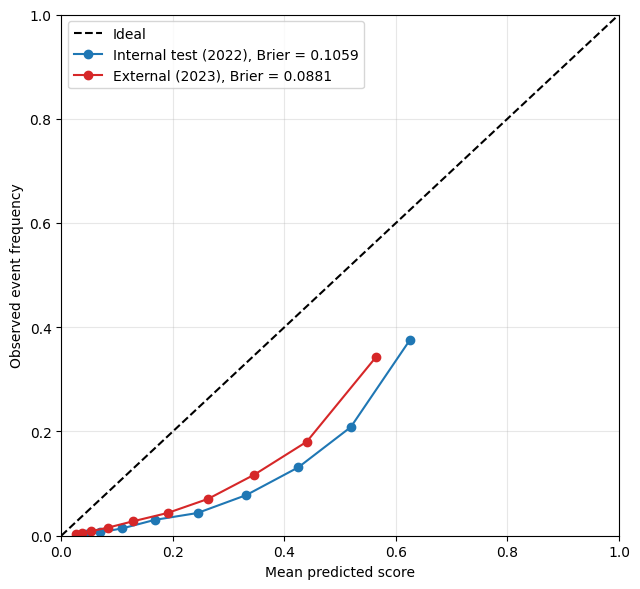

In [ ]:
import numpy as np, matplotlib.pyplot as plt
from sklearn.calibration import calibration_curve
from sklearn.metrics import brier_score_loss

fig, ax = plt.subplots(figsize=(6.5, 6))
ax.plot([0, 1], [0, 1], 'k--', label='Ideal')
for lab, y, p, c in [('Internal test (2022)', np.asarray(y_test), p_test, 'tab:blue'),
                     ('External (2023)', y23, p23, 'tab:red')]:
    fo, mp = calibration_curve(y, p, n_bins=10, strategy='quantile')
    ax.plot(mp, fo, 'o-', color=c, label=f'{lab}, Brier = {brier_score_loss(y, p):.4f}')
ax.set_xlabel('Mean predicted score'); ax.set_ylabel('Observed event frequency')
ax.set_xlim(0, 1); ax.set_ylim(0, 1); ax.grid(alpha=0.3); ax.legend(loc='upper left')
plt.tight_layout()
plt.savefig('/content/drive/MyDrive/CVD EX/figure10a_raw_calibration.png', dpi=600)
plt.show()

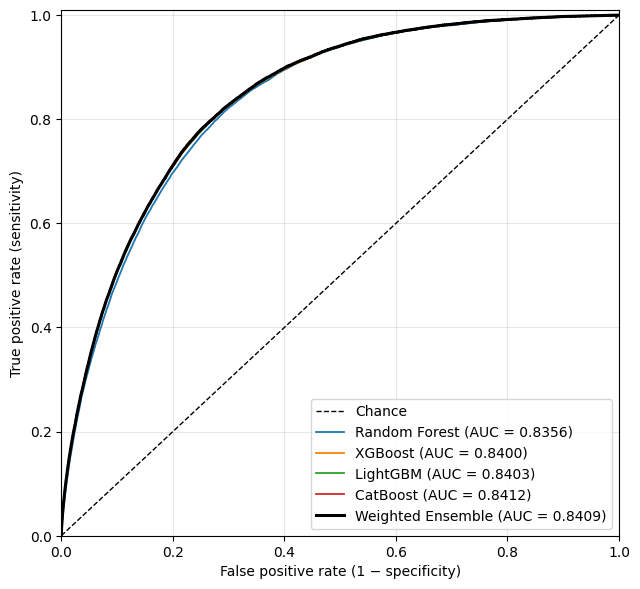

In [ ]:
import numpy as np, matplotlib.pyplot as plt
from sklearn.metrics import roc_curve, roc_auc_score

labels = {'random_forest': 'Random Forest', 'xgboost': 'XGBoost',
          'lightgbm': 'LightGBM', 'catboost': 'CatBoost'}
fig, ax = plt.subplots(figsize=(6.5, 6))
ax.plot([0, 1], [0, 1], 'k--', lw=1, label='Chance')
for n in names:
    fpr, tpr, _ = roc_curve(y23, p23m[n])
    ax.plot(fpr, tpr, lw=1.3, label=f'{labels[n]} (AUC = {roc_auc_score(y23, p23m[n]):.4f})')
fpr, tpr, _ = roc_curve(y23, p23)
ax.plot(fpr, tpr, 'k-', lw=2.2, label=f'Weighted Ensemble (AUC = {roc_auc_score(y23, p23):.4f})')
ax.set_xlabel('False positive rate (1 − specificity)')
ax.set_ylabel('True positive rate (sensitivity)')
ax.set_xlim(0, 1); ax.set_ylim(0, 1.01); ax.grid(alpha=0.3); ax.legend(loc='lower right')
plt.tight_layout()
plt.savefig('/content/drive/MyDrive/CVD EX/figure9_external_roc.png', dpi=600)
plt.show()

In [ ]:
# X2: kitna drop missing features ki wajah se hai (external)

unavail = ['SleepHours', 'RemovedTeeth', 'HighRiskLastYear']
tet = [c for c in X_test.columns if c.startswith('TetanusLast10Tdap')]
redefined = ['ChestScan', 'CovidPos'] + tet
for c in unavail: print(f"2023 {c}: unique values = {X23[c].nunique()}")

def handicap(cols):                       # (a) wahi 2023 wali kamzori 2022 test par laga do
    Xh = X_test.copy()
    for c in cols: Xh[c] = X23[c].median()
    p = ensemble_predict_proba(Xh); pr = (p >= FINAL_THRESHOLD).astype(int)
    return {'Neutralised (2022 test)': 'none' if not cols else (', '.join(cols) if len(cols) < 4 else f'{len(cols)} features'),
            'ROC': roc_auc_score(y_test, p), 'PR': average_precision_score(y_test, p), 'Recall': recall_score(y_test, pr), 'AlertRate': pr.mean()}
print("\n(a) LIKE-FOR-LIKE on 2022 test:\n", pd.DataFrame([handicap([]), handicap(unavail), handicap(unavail + redefined)]).round(4).to_string(index=False))

drop = unavail + redefined; dsan = [san(c) for c in drop]          # (b) harmonised model (sirf LightGBM)
m = clone(base_models['lightgbm'])
try: m.set_params(verbose=-1)
except Exception: pass
m.fit(X_train_lgbm.drop(columns=dsan), y_train)
hv = m.predict_proba(X_val_lgbm.drop(columns=dsan))[:, 1]; thr_h = f1_thr_val(y_val, hv)
ht = m.predict_proba(X_test_lgbm.drop(columns=dsan))[:, 1]; he = m.predict_proba(X23_l.drop(columns=dsan))[:, 1]
rows = []
for lab, y_, p_ in [('2022 internal test', np.asarray(y_test), ht), ('2023 external', y23, he)]:
    pr = (p_ >= thr_h).astype(int)
    rows.append({'Harmonised LightGBM': lab, 'ROC': roc_auc_score(y_, p_), 'PR': average_precision_score(y_, p_), 'Recall': recall_score(y_, pr),
                 'Precision': precision_score(y_, pr), 'Specificity': ((pr == 0) & (y_ == 0)).sum() / (y_ == 0).sum()})
print(f"\n(b) HARMONISED ({len(drop)} features removed), thr from 2022 val = {thr_h:.4f}\n", pd.DataFrame(rows).round(4).to_string(index=False))
print("   external calibration:", cal_stats(y23, he))

smd = ((X23.astype(float).mean() - X_test.astype(float).mean()) / np.sqrt((X23.astype(float).var() + X_test.astype(float).var()) / 2)).abs().sort_values(ascending=False)
print("\n(c) Top-8 shifted features AFTER fix:\n", smd.head(8).round(3).to_string())
print("\n2023 subgroups (frozen ensemble):\n", subgroup_report(X23, y23, p23, FINAL_THRESHOLD, age_sex_groups(X23)))

2023 SleepHours: unique values = 1
2023 RemovedTeeth: unique values = 1
2023 HighRiskLastYear: unique values = 1

(a) LIKE-FOR-LIKE on 2022 test:
                    Neutralised (2022 test)    ROC     PR  Recall  AlertRate
                                      none 0.8518 0.3699  0.8164     0.3145
SleepHours, RemovedTeeth, HighRiskLastYear 0.8502 0.3659  0.7809     0.2877
                                8 features 0.8437 0.3558  0.6805     0.2226

(b) HARMONISED (8 features removed), thr from 2022 val = 0.4928
 Harmonised LightGBM    ROC     PR  Recall  Precision  Specificity
 2022 internal test 0.8456 0.3579  0.8181     0.2230       0.7204
      2023 external 0.8428 0.3368  0.8218     0.2011       0.7107
   external calibration: {'Slope': 1.021, 'Slope_95CI': (1.01, 1.032), 'CITL_intercept': -2.441, 'Brier': 0.1733, 'Brier_null(prevalence)': 0.0748}

(c) Top-8 shifted features AFTER fix:
 RemovedTeeth                                                           1.071
ChestScan           